# B5 · Modèles de diffusion : un DDPM minimal — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/b5_diffusion/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | B5.Q1 à B5.Q11, B5.R1 à B5.R3, B5.1 à B5.5 | vérifier tes réponses courtes | 🧠 🔁 ✏️ | ★ à ★★ | |
| A | B5.12 | linear_beta_schedule, cosine_beta_schedule et noise_schedule | 🔨 | ★★ | 20 |
|  | B5.13 | Prédire l'allure d'un chiffre bruité aux pas 100, 300 et 600, planning linéaire puis cosinus | 🔮 | ★ | 10 |
|  | B5.14 | q_sample : bruiter un batch d'images à des pas différents | 🔨 | ★★ | 20 |
|  | B5.15 | Lire ᾱ_t, le rapport signal sur bruit et la grille de bruitage des deux plannings | 📈 | ★ | 15 |
|  | B5.16 | q_posterior_mean_variance et predict_x0_from_eps | 🔨 | ★★ | 30 |
|  | B5.17 | ddpm_step et ddim_step | 🔨 | ★★★ | 40 |
|  | B5.18 | Avec le vrai bruit, DDPM et DDIM retrouvent-ils x_0 ? Contrôle sur des données 2D | 🔬 | ★★ | 25 |
| B | B5.19 | Diffusion en 2D : un MLP débruiteur conditionné par le pas de temps, entraîné puis échantillonné | 📦 | ★★ | 30 |
|  | B5.20 | Flow matching en 2D : même MLP, cible « vitesse » et intégration d'Euler | 🔬 | ★★★ | 40 |
| C | B5.21 | Un U-Net minuscule en PyTorch : blocs convolutifs, connexions de saut, encodage du pas de temps | 📦 | ★★★ | 50 |
| C | B5.22 à B5.31 | la suite du U-Net sur MNIST et Fashion-MNIST : quatre bugs, entraînement avec EMA, DDPM contre DDIM, nombre de pas, guidance, mémorisation, distance de Fréchet, script autonome et défi (*prochaine étape de la génération*) | | | |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Dériver la forme fermée du bruitage et le posterior d'un pas, et calculer à la main un pas DDPM et un pas DDIM.
- Implémenter en NumPy les plannings de bruit, le bruitage et les pas d'échantillonnage, et les contrôler par l'aller-retour avec le vrai bruit.
- Écrire et entraîner un petit U-Net conditionné par le pas, l'échantillonner par DDPM et DDIM, et le conditionner par la classe avec la guidance sans classifieur.
- Évaluer un générateur (distance de Fréchet, plus proches voisins) et le situer face au VAE et au GAN.

**Rappel express.** Pas de l'article $t = 1..T$, indice du code $t - 1$. $\alpha_t = 1 - \beta_t$, $\bar\alpha_t = \prod_{s \le t} \alpha_s$, $\mathbf{x}_t = \sqrt{\bar\alpha_t}\,\mathbf{x}_0 + \sqrt{1 - \bar\alpha_t}\,\boldsymbol{\varepsilon}$, $\operatorname{SNR}(t) = \bar\alpha_t / (1 - \bar\alpha_t)$. Posterior : $\tilde\beta_t = \frac{1 - \bar\alpha_{t-1}}{1 - \bar\alpha_t}\beta_t$. DDPM : $\mathbf{x}_{t-1} = \frac{1}{\sqrt{\alpha_t}}\big(\mathbf{x}_t - \frac{\beta_t}{\sqrt{1 - \bar\alpha_t}}\boldsymbol{\varepsilon}_\theta\big) + \sigma_t\mathbf{z}$, sans bruit au dernier pas. DDIM ($\eta = 0$) : $\hat{\mathbf{x}}_0 = (\mathbf{x}_t - \sqrt{1 - \bar\alpha_t}\,\boldsymbol{\varepsilon}_\theta) / \sqrt{\bar\alpha_t}$, puis $\mathbf{x}_{t'} = \sqrt{\bar\alpha_{t'}}\,\hat{\mathbf{x}}_0 + \sqrt{1 - \bar\alpha_{t'}}\,\boldsymbol{\varepsilon}_\theta$. Guidance : $\tilde{\boldsymbol{\varepsilon}} = (1 + w)\,\boldsymbol{\varepsilon}_\theta(\mathbf{x}_t, c) - w\,\boldsymbol{\varepsilon}_\theta(\mathbf{x}_t, \varnothing)$, `guidance_scale` $= 1 + w$.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ B5.1 à B5.5)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; un vecteur : une liste de nombres (`[0.5, -1.25]`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », les dérivations ∂ B5.6 et B5.7, l'estimation 🧮 B5.8, la réflexion (🗣️ B5.9, ⚖️ B5.10, 📄 B5.11) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md). Steps: t = 1..T in the
# formulas (Ho et al.), indices 0..T-1 in the code (step t is index t - 1).
import math

import numpy as np

# ✏️ B5.1: classifier-free guidance on two pixels, (1 + w) eps_c - w eps_uncond
EC_B51, EU_B51 = np.array([0.8, -0.5]), np.array([0.5, 0.1])


def cfg_b51(w, cond=EC_B51, uncond=EU_B51):
    return [float(v) for v in (1 + w) * cond - w * uncond]


W0_B51, W1_B51, W3_B51 = cfg_b51(0), cfg_b51(1), cfg_b51(3)
GAP_B51 = 3 * float(np.linalg.norm(EC_B51 - EU_B51))                # || eps_tilde - eps_c || for w = 3
EVALS_B51 = 2 * 50                                                  # two predictions per step, 50 DDIM steps

# ✏️ B5.2: toy linear schedule T = 4, beta from 0.05 to 0.35 (it serves B5.4 to B5.7 too)
BETAS_B52 = np.linspace(0.05, 0.35, 4)
ALPHAS_B52 = 1 - BETAS_B52
AB_B52 = np.cumprod(ALPHAS_B52)                                     # alpha_bar, indices 0..3 (steps 1..4)
BETA2_B52, AB2_B52, AB4_B52 = float(BETAS_B52[1]), float(AB_B52[1]), float(AB_B52[3])
KEEP4_B52 = math.sqrt(AB4_B52)
APPROX4_B52 = math.exp(-float(BETAS_B52.sum()))
SUM1000_B52 = 1000 * (1e-4 + 0.02) / 2                              # arithmetic series: T (beta_1 + beta_T) / 2
AB1000_E5_B52 = math.exp(-SUM1000_B52) * 1e5
KEEP1000_PCT_B52 = 100 * math.sqrt(AB1000_E5_B52 * 1e-5)
SUM400_B52 = 400 * (1e-4 + 0.02) / 2
SUM400_SCALED_B52 = 400 * (1e-4 + 0.02) * (1000 / 400) / 2

# ✏️ B5.3: signal-to-noise ratio of the linear schedule (approximation exp(-S(t))) and of the cosine schedule (exact)
T_B53, B1_B53, BT_B53, S_B53 = 1000, 1e-4, 0.02, 0.008


def lin_sum_b53(t, square=False):
    """S(t), the sum of the first t betas; square=True: the t**2 slip instead of t (t - 1)."""
    return t * B1_B53 + (BT_B53 - B1_B53) * (t * t if square else t * (t - 1)) / (2 * (T_B53 - 1))


def snr_b53(ab):
    return ab / (1 - ab)


def cos_ab_b53(u, s=S_B53):
    f = lambda v: math.cos((v + s) / (1 + s) * math.pi / 2) ** 2
    return f(u) / f(0)


def lin_cross_b53(target_sum):
    """The t (real) where S(t) = target_sum: a t**2 + b t - target_sum = 0, then the fraction t / T."""
    a = (BT_B53 - B1_B53) / (2 * (T_B53 - 1))
    b = B1_B53 - a
    return (-b + math.sqrt(b * b + 4 * a * target_sum)) / (2 * a) / T_B53


def cos_cross_b53(alpha_bar, s=S_B53):
    """The fraction u where the cosine alpha_bar(u) equals alpha_bar."""
    f0 = math.cos(s / (1 + s) * math.pi / 2) ** 2
    theta = math.acos(math.sqrt(alpha_bar * f0))
    return theta * 2 / math.pi * (1 + s) - s


S500_B53 = lin_sum_b53(500)
LIN500_B53 = snr_b53(math.exp(-S500_B53))
COS500_B53 = snr_b53(cos_ab_b53(0.5))
LIN1_B53, COS1_B53 = lin_cross_b53(math.log(2)), cos_cross_b53(0.5)           # SNR = 1: alpha_bar = 1/2
LIN01_B53, COS01_B53 = lin_cross_b53(math.log(11)), cos_cross_b53(1 / 11)     # SNR = 0.1: alpha_bar = 1/11

# ✏️ B5.4: one DDPM step at step t = 3 (index 2) of the toy schedule
I_B54, X3_B54, EPS_B54, Z_B54 = 2, 0.8, 0.5, -1.0


def ddpm_mean_b54(x, eps, i=I_B54, sign=-1.0, root=True):
    """Mean of Algorithm 2; sign=+1: the sign slip; root=False: beta / (1 - alpha_bar) without the square root."""
    ab = float(AB_B52[i])
    coef = BETAS_B52[i] / (math.sqrt(1 - ab) if root else (1 - ab))
    return float((x + sign * coef * eps) / math.sqrt(ALPHAS_B52[i]))


def posterior_b54(i=I_B54):
    """coef1, coef2 and beta tilde of the posterior at index i (alpha_bar_prev = 1 at index 0)."""
    ab, ab_prev = float(AB_B52[i]), (float(AB_B52[i - 1]) if i > 0 else 1.0)
    beta = float(BETAS_B52[i])
    return (beta * math.sqrt(ab_prev) / (1 - ab), (1 - ab_prev) * math.sqrt(ALPHAS_B52[i]) / (1 - ab),
            beta * (1 - ab_prev) / (1 - ab))


COEF_B54 = float(BETAS_B52[I_B54] / math.sqrt(1 - AB_B52[I_B54]))
MEAN_B54 = ddpm_mean_b54(X3_B54, EPS_B54)
C1_B54, C2_B54, BTILDE_B54 = posterior_b54()
X2_B54 = MEAN_B54 + math.sqrt(BTILDE_B54) * Z_B54
X2_BETA_B54 = MEAN_B54 + math.sqrt(BETAS_B52[I_B54]) * Z_B54
X3C_B54, EPSC_B54 = 1.5, -0.6
X0HAT_C_B54 = (X3C_B54 - math.sqrt(1 - AB_B52[I_B54]) * EPSC_B54) / math.sqrt(AB_B52[I_B54])
CLIP_MEAN_B54 = C1_B54 * float(np.clip(X0HAT_C_B54, -1, 1)) + C2_B54 * X3C_B54
NOCLIP_MEAN_B54 = C1_B54 * X0HAT_C_B54 + C2_B54 * X3C_B54
LAST_B54 = ddpm_mean_b54(0.5, 0.2, i=0)                                         # step 1 (index 0): no noise

# ✏️ B5.5: DDIM from step 4 (index 3), x_4 = -0.5, eps_theta = -1.2
X4_B55, EPS_B55 = -0.5, -1.2


def x0hat_b55(x=X4_B55, eps=EPS_B55, i=3):
    return float((x - math.sqrt(1 - AB_B52[i]) * eps) / math.sqrt(AB_B52[i]))


def ab_b55(i):
    return 1.0 if i == -1 else float(AB_B52[i])


def ddim_b55(i, i_prev, eta=0.0, x=X4_B55, eps=EPS_B55, noise_term=True):
    """The deterministic part of a DDIM step (z = 0), and sigma."""
    a, ap = ab_b55(i), ab_b55(i_prev)
    sigma = eta * math.sqrt((1 - ap) / (1 - a)) * math.sqrt(1 - a / ap)
    x0 = (x - math.sqrt(1 - a) * eps) / math.sqrt(a)
    return math.sqrt(ap) * x0 + (math.sqrt(1 - ap - sigma ** 2) * eps if noise_term else 0.0), sigma


X0HAT_B55 = x0hat_b55()
X1_B55 = ddim_b55(3, 0)[0]
X2_B55 = ddim_b55(3, 1)[0]
SIGMA2_43_B55 = ddim_b55(3, 2, eta=1.0)[1] ** 2
SIGMA_41_B55 = ddim_b55(3, 0, eta=1.0)[1]
DIR_41_B55 = math.sqrt(1 - AB_B52[0] - SIGMA_41_B55 ** 2)

# quizzes and recalls with a computation
Q1E = 1000 * 0.02
Q2B = float(np.mean([-1, 0, 2]))
Q2C = float(np.mean((np.array([-1, 0, 2]) - Q2B) ** 2))
Q3A, Q3B, Q3D = math.sqrt(0.64), math.sqrt(1 - 0.64), 0.64 / 0.36
Q4B = (0.5 - math.sqrt(1 - 0.64) * 0.2) / math.sqrt(0.64)
Q5C = 128 // 2
Q6B, Q6D = 128 + 64, 32 // 2 ** 3
Q7A = 1000 * 0.05
Q9A = 3 * 0.3 - 2 * 0.5
Q11A = (256 // 4) ** 2 * 3
R1B = 2 * math.pi
R2A = (0 - 1) ** 2 + (1 + 4 - 2 * math.sqrt(1 * 4))
R2E = 0 ** 2 + (1 + 0 - 2 * math.sqrt(1 * 0))
R3A = 0.5 + math.exp(0.5 * math.log(0.25)) * (-2)
R3B = 0.5 * (0.5 ** 2 + 0.25 - 1 - math.log(0.25))

# The same answers from the libraries (no download): mylearn (reference) and, if installed, diffusers
D = mylearn.diffusion
toy = D.noise_schedule(D.linear_beta_schedule(4, 0.05, 0.35))
assert np.allclose(toy["betas"], BETAS_B52) and np.allclose(toy["alpha_bars"], AB_B52)

# ✏️ B5.2: the sums of the betas, and the exact alpha_bar_T that the approximation overestimates
lin1000 = D.noise_schedule(D.linear_beta_schedule(1000))
assert math.isclose(lin1000["betas"].sum(), SUM1000_B52)
assert math.isclose(D.linear_beta_schedule(400).sum(), SUM400_B52)
assert math.isclose(D.linear_beta_schedule(400, 1e-4 * 2.5, 0.02 * 2.5).sum(), SUM400_SCALED_B52)
assert lin1000["alpha_bars"][-1] < AB1000_E5_B52 * 1e-5 and toy["alpha_bars"][-1] < APPROX4_B52

# ✏️ B5.3: the exact schedules of the library (index i = step i + 1) cross the thresholds at the same 2 decimals
cos1000 = D.noise_schedule(D.cosine_beta_schedule(1000))
for sched, answers in ((lin1000, (LIN1_B53, LIN01_B53)), (cos1000, (COS1_B53, COS01_B53))):
    snr = sched["alpha_bars"] / (1 - sched["alpha_bars"])
    for threshold, answer in zip((1.0, 0.1), answers):
        first_step = int(np.argmax(snr < threshold)) + 1
        assert round(first_step / 1000, 2) == round(answer, 2), (threshold, first_step, answer)
assert math.isclose(cos1000["alpha_bars"][499], cos_ab_b53(0.5), rel_tol=1e-9)
assert round(float(lin1000["alpha_bars"][499] / (1 - lin1000["alpha_bars"][499])), 2) == round(LIN500_B53, 2)

# ✏️ B5.4: ddpm_step; its mean is step(x) - step(0) with the same seed, its variance posterior_variance
def mean_of_ddpm_step(x, i, eps, **kw):
    one = D.ddpm_step(np.array([[x]]), i, np.array([[eps]]), toy, rng=np.random.default_rng(0), **kw)
    zero = D.ddpm_step(np.array([[0.0]]), i, np.array([[0.0]]), toy, rng=np.random.default_rng(0),
                       variance=kw.get("variance", "posterior"))
    return float((one - zero)[0, 0])


assert math.isclose(mean_of_ddpm_step(X3_B54, I_B54, EPS_B54), MEAN_B54)
assert math.isclose(mean_of_ddpm_step(X3_B54, I_B54, EPS_B54, variance="beta"), MEAN_B54)
assert math.isclose(mean_of_ddpm_step(X3C_B54, I_B54, EPSC_B54, clip_x0=1.0), CLIP_MEAN_B54)
assert math.isclose(toy["posterior_variance"][I_B54], BTILDE_B54)
assert math.isclose(toy["posterior_mean_coef1"][I_B54], C1_B54) and math.isclose(toy["posterior_mean_coef2"][I_B54], C2_B54)
for variance in ("posterior", "beta"):                                 # step 1 (index 0): no noise, whatever the seed
    assert math.isclose(float(D.ddpm_step(np.array([[0.5]]), 0, np.array([[0.2]]), toy, rng=7, variance=variance)[0, 0]),
                        LAST_B54)

# ✏️ B5.5: predict_x0_from_eps and ddim_step (eta = 0: deterministic)
assert math.isclose(float(D.predict_x0_from_eps(np.array([X4_B55]), [3], np.array([EPS_B55]), AB_B52)[0]), X0HAT_B55)
x4 = np.array([[X4_B55]]); e4 = np.array([[EPS_B55]])
assert math.isclose(float(D.ddim_step(x4, 3, 0, e4, AB_B52)[0, 0]), X1_B55)
assert math.isclose(float(D.ddim_step(x4, 3, 1, e4, AB_B52)[0, 0]), X2_B55)
assert math.isclose(float(D.ddim_step(D.ddim_step(x4, 3, 1, e4, AB_B52), 1, 0, e4, AB_B52)[0, 0]), X1_B55)
assert math.isclose(float(D.ddim_step(x4, 3, -1, e4, AB_B52)[0, 0]), X0HAT_B55)
assert math.isclose(SIGMA2_43_B55, toy["posterior_variance"][3])

# recalls: positional_encoding (B3), frechet_distance (ch. 27), reparameterize and gaussian_kl (ch. 25)
pe = mylearn.attention.positional_encoding(1000, 128)
assert pe[0, 1] == 1.0 and pe.shape[1] // 2 == Q5C
assert np.allclose(pe[:, 0], np.sin(np.arange(1000)))                 # column 0: sin(p), period 2 pi
assert 2 * math.pi * 10000 ** (126 / 128) > 1000                      # the slowest pair: less than one turn
fd = mylearn.gen_metrics.frechet_distance
assert math.isclose(fd([0.0], [[1.0]], [1.0], [[4.0]]), R2A) and math.isclose(fd([0.0], [[1.0]], [0.0], [[0.0]]), R2E)
z, _ = mylearn.vae.reparameterize([[0.5]], [[math.log(0.25)]], rng=0)
assert z.shape == (1, 1)
assert math.isclose(float(mylearn.vae.gaussian_kl([[0.5]], [[math.log(0.25)]])[0]), R3B)
print("✅ the paper answers agree with mylearn (reference): diffusion, attention, gen_metrics, vae")

# Optional: diffusers' schedulers on the toy schedule (float64 tensors, noise set to zero)
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm, imported by diffusers
try:
    import torch
    import diffusers.schedulers.scheduling_ddpm as ddpm_module
    from diffusers import DDIMScheduler, DDPMScheduler
except ImportError:
    print("ℹ️ diffusers is not installed: the scheduler comparison is skipped (the closed forms above are checked)")
else:
    def as_double(scheduler, names):
        for name in names:
            setattr(scheduler, name, getattr(scheduler, name).double())
        return scheduler

    def diffusers_ddpm(x, i, eps, clip=None):
        sch = as_double(DDPMScheduler(num_train_timesteps=4, trained_betas=BETAS_B52.tolist(),
                                      clip_sample=clip is not None, clip_sample_range=clip or 1.0),
                        ("betas", "alphas", "alphas_cumprod", "one"))
        saved = ddpm_module.randn_tensor
        ddpm_module.randn_tensor = lambda shape, **kw: torch.zeros(shape, dtype=torch.float64)
        try:
            out = sch.step(torch.tensor([[eps]], dtype=torch.float64), i, torch.tensor([[x]], dtype=torch.float64))
        finally:
            ddpm_module.randn_tensor = saved
        return float(out.prev_sample), float(sch._get_variance(i))

    def diffusers_ddim(x, i, eps, n_steps):
        sch = as_double(DDIMScheduler(num_train_timesteps=4, trained_betas=BETAS_B52.tolist(), clip_sample=False,
                                      set_alpha_to_one=True), ("alphas_cumprod", "final_alpha_cumprod"))
        sch.set_timesteps(n_steps)
        out = sch.step(torch.tensor([[eps]], dtype=torch.float64), i, torch.tensor([[x]], dtype=torch.float64),
                       eta=0.0)
        return float(out.prev_sample), float(out.pred_original_sample), sch

    mean, var = diffusers_ddpm(X3_B54, I_B54, EPS_B54)
    assert math.isclose(mean, MEAN_B54, rel_tol=1e-6) and math.isclose(var, BTILDE_B54, rel_tol=1e-6)
    assert math.isclose(diffusers_ddpm(X3C_B54, I_B54, EPSC_B54, clip=1.0)[0], CLIP_MEAN_B54, rel_tol=1e-6)
    assert math.isclose(diffusers_ddpm(0.5, 0, 0.2)[0], LAST_B54, rel_tol=1e-6)
    prev, x0_pred, ddim = diffusers_ddim(X4_B55, 3, EPS_B55, 2)          # 4 // 2 = 2: index 3 -> index 1
    assert math.isclose(prev, X2_B55, rel_tol=1e-6) and math.isclose(x0_pred, X0HAT_B55, rel_tol=1e-6)
    assert math.isclose(diffusers_ddim(X4_B55, 3, EPS_B55, 1)[0], X0HAT_B55, rel_tol=1e-6)   # index 3 -> clean
    assert math.isclose(float(ddim._get_variance(3, 2)), SIGMA2_43_B55, rel_tol=1e-6)
    assert math.isclose(float(ddim._get_variance(3, 0)), SIGMA_41_B55 ** 2, rel_tol=1e-6)
    print("✅ ✏️ B5.4 and B5.5 also agree with diffusers' DDPMScheduler and DDIMScheduler")

✅ the paper answers agree with mylearn (reference): diffusion, attention, gen_metrics, vae


✅ ✏️ B5.4 and B5.5 also agree with diffusers' DDPMScheduler and DDIMScheduler


**B5.Q1 — Diffusion, VAE, GAN : comment chacun fabrique-t-il une image ?**

In [3]:
wb.record("B5.Q1a", "A", mistakes={"relis l'encadré 🔗 « Lien avec les ch. 25 et 27 » : combien de passes du décodeur pour générer avec un VAE ?": "B", "pour générer, part-on d'une image du dataset ? Relis l'encadré 🔗 de 205.1": "C"})
wb.record("B5.Q1b", False, mistakes={"relis « Détruire est facile » (§205.1) : le processus direct s'apprend-il ?": True})
wb.record("B5.Q1c", "C", mistakes={"relis l'encadré 🔗 de 205.1 : la diffusion s'entraîne-t-elle contre un adversaire ?": "A", "le VAE a-t-il un discriminateur ? Relis l'encadré 🔗 de 205.1": "B"})
wb.record("B5.Q1d", True, mistakes={"relis l'encadré 🔗 « Lien avec les ch. 25 et 27 » : quelle taille ont les codes de la diffusion ?": False})
wb.record("B5.Q1e", round(Q1E), mistakes={"c'est le nombre de passes : on demande des secondes": 1000,
          "vérifie la multiplication par 1 000": 2})

WB_ANSWER {"hash": "41720f303bfd990d3dc5f44dff8194f5c33a30516f977bcae6615a8fd8ad206d", "id": "B5.Q1a", "kind": "str", "mistakes": {"3888407bcd4f66824bda54d8a4c8d8961382b75fce8bf171aaf51b1dbdaf97b8": "pour générer, part-on d'une image du dataset ? Relis l'encadré 🔗 de 205.1", "98560c3d2eac11c494f5e3ab63b7ff5060503afc39b75132d37d247589eaf757": "relis l'encadré 🔗 « Lien avec les ch. 25 et 27 » : combien de passes du décodeur pour générer avec un VAE ?"}}
📝 Ex B5.Q1a : réponse enregistrée (str).
WB_ANSWER {"hash": "9765d05e0491668deecbfcfe28e7f8ae69a00f1227d851ef1965a5d5264a0205", "id": "B5.Q1b", "kind": "bool", "mistakes": {"060620eacdb00f1abfbb5d99e1d32d54aa87c468130a034cf0422a3ea62c1812": "relis « Détruire est facile » (§205.1) : le processus direct s'apprend-il ?"}}
📝 Ex B5.Q1b : réponse enregistrée (bool).
WB_ANSWER {"hash": "583732202f06286a76edfdd7cd55f3dc520de1afb3832471b931864676c232c5", "id": "B5.Q1c", "kind": "str", "mistakes": {"226a1167aa75d3e143a25ed867bb40659b37e20fae774013b

**B5.Q2 — Pourquoi détruire l'image en mille petits pas de bruit plutôt qu'en un seul ?**

In [4]:
wb.record("B5.Q2a", "B", mistakes={"relis l'encadré 🧮 « la MSE apprend une moyenne » (§205.1) : que rend un réseau entraîné par MSE quand plusieurs cibles sont possibles ?": "A", "un réseau entraîné par MSE recopie-t-il un exemple ? Relis l'encadré 🧮 de 205.1": "C"})
wb.record("B5.Q2b", Q2B, decimals=2, mistakes={"c'est la médiane : la MSE est minimisée par une autre grandeur (encadré 🧮 de 205.1)": 0.0,
          "c'est le milieu entre la plus petite et la plus grande cible : relis l'encadré 🧮 de 205.1": 0.5})
wb.record("B5.Q2c", Q2C, decimals=2, mistakes={"c'est la MSE de la prédiction 0 : prends la prédiction de b)": 5 / 3,
          "la MSE est une moyenne des carrés des écarts : divise par le nombre de cibles": 3 * Q2C,
          "élève les écarts au carré avant de faire la moyenne": float(np.mean(np.abs(np.array([-1, 0, 2]) - Q2B)))})
wb.record("B5.Q2d", True, mistakes={"relis « Ce qu'on voudrait » (§205.3) : que dit-on de ce pas quand β_t est petit ?": False})
wb.record("B5.Q2e", False, mistakes={"relis l'approximation ln ᾱ_T ≈ −Σβ (§205.2) : à somme égale, que deviennent les β quand il y a deux fois plus de pas ?": True})

WB_ANSWER {"hash": "094818d2a8a2354a0889983c7f1314fcaa69b394cf1774d3bca1958ccf8f9dc8", "id": "B5.Q2a", "kind": "str", "mistakes": {"b4f01a88802c1bcda9330e0f6e43afa29ced09409eb664cf85f62546f88969fc": "un réseau entraîné par MSE recopie-t-il un exemple ? Relis l'encadré 🧮 de 205.1", "c304df0643bf9b28c3a048ca9bee692254b6886c130132a69f34af724f1a9378": "relis l'encadré 🧮 « la MSE apprend une moyenne » (§205.1) : que rend un réseau entraîné par MSE quand plusieurs cibles sont possibles ?"}}
📝 Ex B5.Q2a : réponse enregistrée (str).
WB_ANSWER {"decimals": 2, "hash": "78107d440a9641580dd6fb5192b8db493bc66a5a4adb90cd7e448e056a02678a", "hash_coarse": "a1f4b98c299bedbb6d28b80d7407a26cde30ebffa5e8a43264123ec38c41e3a9", "id": "B5.Q2b", "kind": "float", "magnitude": -1, "mistakes": {"05831900b805231409287bc8e58bbec9763f9d50ba81095ef2f5588975d79921": "c'est le milieu entre la plus petite et la plus grande cible : relis l'encadré 🧮 de 205.1", "bb0f542c4a5e90f59dc4f87d31fcad0f0d4738cf05d68e7a13a2d213b8c

**B5.Q3 — ᾱ_t : quelle part de l'image reste-t-il au pas t ?**

In [5]:
wb.record("B5.Q3a", Q3A, decimals=2, mistakes={"c'est ᾱ_t : relis la forme fermée, le coefficient de x₀ est-il ᾱ_t ?": 0.64,
          "relis la question : on demande le coefficient de x₀, pas celui du bruit": Q3B})
wb.record("B5.Q3b", Q3B, decimals=2, mistakes={"c'est 1 − ᾱ_t : relis la forme fermée, le coefficient du bruit est-il 1 − ᾱ_t ?": 0.36,
          "relis la question : on demande le coefficient du bruit, pas celui de x₀": Q3A})
wb.record("B5.Q3c", False, mistakes={"calcule la somme de tes réponses a) et b) ; relis la dernière phrase de « La forme fermée »": True})
wb.record("B5.Q3d", Q3D, decimals=2, mistakes={"le SNR met la part de l'image au numérateur": 0.36 / 0.64,
          "le SNR est un rapport de variances, pas de coefficients": Q3A / Q3B})
wb.record("B5.Q3e", "C", mistakes={"relis la définition de ᾱ_t : un produit de nombres plus petits que 1 peut-il croître ?": "A", "regarde la figure `plannings.png` (§205.2) : ᾱ_t reste-t-il constant ?": "B"})

WB_ANSWER {"decimals": 2, "hash": "fad54c90c758d36d3f929e8f0beacc3e97d2de79178e24f59997151aab2e57ad", "hash_coarse": "98f03cce9a77a0dd7bd4fd37cf10094a7aa488f9099b214d928cd80ff1c03f4e", "id": "B5.Q3a", "kind": "float", "magnitude": -1, "mistakes": {"5b082ddfe2aa19d480987580180299cf94991e4d7a84ccc7a23f07aa87f0c559": "c'est ᾱ_t : relis la forme fermée, le coefficient de x₀ est-il ᾱ_t ?", "821dde2d176f9264898828ea23fc23e4b682e26de8059af02e2c168104d6d065": "relis la question : on demande le coefficient de x₀, pas celui du bruit"}, "sign": 1}
📝 Ex B5.Q3a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "25c6c597d65c25763d0625df0ff5ea63983e70adcca46841b6518cad4e722314", "hash_coarse": "ef22d2133a9888058e66f00cb45d8e46529016d0478d14c16c49f7015d0a11cd", "id": "B5.Q3b", "kind": "float", "magnitude": -1, "mistakes": {"6f6f88f03b8feffdc7148c78da558fbe48985a87911d928b3f6299a8fe3656ac": "relis la question : on demande le coefficient du bruit, pas celui de x₀", "947b55c

**B5.Q4 — Prédire le bruit, l'image ou la vitesse : la même information ?**

In [6]:
wb.record("B5.Q4a", "A", mistakes={"relis « Prédire le bruit » (§205.3) : la formule de x̂₀ est-elle une approximation quand le bruit est le vrai ?": "B", "relis « Prédire le bruit » (§205.3) : la forme fermée s'inverse-t-elle ?": "C"})
wb.record("B5.Q4b", Q4B, decimals=3, mistakes={"relis la formule de x̂₀ : on divise par la racine de ᾱ_t, et le bruit est multiplié par la racine de 1 − ᾱ_t": (0.5 - 0.36 * 0.2) / 0.64,
          "vérifie le signe : on retire le bruit de x_t": (0.5 + 0.6 * 0.2) / 0.8,
          "n'oublie pas de diviser par la racine de ᾱ_t": 0.5 - 0.6 * 0.2})
wb.record("B5.Q4c", True, mistakes={"relis le paragraphe qui suit la moyenne μ_θ (§205.3) : qu'ont trouvé Ho et coll. pour la prédiction de x₀ ?": False})
wb.record("B5.Q4d", "C", mistakes={"le réseau reçoit-il encore t quand il prédit le bruit ? Relis « Dire au réseau quel est le pas »": "A", "le bruit est-il toujours plus petit que l'image ? Relis la raison donnée en 205.3": "B"})
wb.record("B5.Q4e", False, mistakes={"relis le paragraphe qui suit l'encadré 🧮 sur Euler (§205.9) : les deux « v » sont-ils la même grandeur ?": True})

WB_ANSWER {"hash": "bfb6795642a6d6b50d64e3a40e8b3bb2d4fff9eaa5ee18f857e3bd76cb9c2863", "id": "B5.Q4a", "kind": "str", "mistakes": {"5a67a8bc195589b301e6e26ef998d5504f369e0cc0e83294614b9e4bd7855dd7": "relis « Prédire le bruit » (§205.3) : la formule de x̂₀ est-elle une approximation quand le bruit est le vrai ?", "afc7240a09d1900a530ba6801608680382c0f9ba4e916dcafdb92b7158e9f41a": "relis « Prédire le bruit » (§205.3) : la forme fermée s'inverse-t-elle ?"}}
📝 Ex B5.Q4a : réponse enregistrée (str).
WB_ANSWER {"alt_coarse": ["0ea6fb4152e772a877405d93fc9c9e5fa97403121242285b6e4949464d41d0e6"], "decimals": 3, "hash": "178742548729aa10e29912caf40ed673ca98d46c5b2df4373d38b54f6e2658b8", "hash_coarse": "8cf32c251715715e3549a6e671549d4b8a0e1b0d5f9aef859cfaed5c2eb6ed08", "id": "B5.Q4b", "kind": "float", "magnitude": -1, "mistakes": {"4a7f5bc959d6dd62cc18c51bc96a037d6ea2557f8198c380af127800b6a3be88": "n'oublie pas de diviser par la racine de ᾱ_t", "59248d3c9978905b14f5f3c063f7654c5a7cb203ce53f7fc134

**B5.Q5 — Le pas de temps est une entrée du réseau : pourquoi, et comment l'encoder ?**

In [7]:
wb.record("B5.Q5a", "C", mistakes={"relis « Reconstruire s'apprend » (§205.1) : combien de réseaux sert-on pour tous les pas ?": "A", "ᾱ_t se calcule-t-il dans le réseau ? Relis « Dire au réseau quel est le pas »": "B"})
wb.record("B5.Q5b", False, mistakes={"relis « Dire au réseau quel est le pas » (§205.4) : que dit la fiche d'un nombre de 0 à 999 donné tel quel ?": True})
wb.record("B5.Q5c", Q5C, mistakes={"c'est le nombre de colonnes : chaque couple en occupe deux": 128,
          "relis l'appel : d_model = 128": 32})
wb.record("B5.Q5d", "B", mistakes={"relis « Un bloc résiduel conditionné par le pas » : l'encodage est-il concaténé ?": "A", "relis la ligne `h = h + self.time(temb)[:, :, None, None]` du bloc résiduel": "C"})
wb.record("B5.Q5e", True, mistakes={"relis la fin de « Dire au réseau quel est le pas » : que dit la fiche des permutations de colonnes ?": False})

WB_ANSWER {"hash": "e1cc67682c4ff50a34a369e5128e3a9665034f8b5268bfed646fed0b86f6579e", "id": "B5.Q5a", "kind": "str", "mistakes": {"3e32a67cdd1a6d965cce6563c49ea7ff7bd229844195bb2bdf58803b0d526c3e": "relis « Reconstruire s'apprend » (§205.1) : combien de réseaux sert-on pour tous les pas ?", "45829bd96fc3743ec3ba777759e74f54f1bc8f1cb9d3deb584d9d287d6e0ab5f": "ᾱ_t se calcule-t-il dans le réseau ? Relis « Dire au réseau quel est le pas »"}}
📝 Ex B5.Q5a : réponse enregistrée (str).
WB_ANSWER {"hash": "ce2341a06111b77bf7037f83d0b975ccb798cbdd77b1b857fb96ecd4f34ede85", "id": "B5.Q5b", "kind": "bool", "mistakes": {"f138295139b743639d4b2842c931c2ace22fafedf4e5ce134c3f71ac1160e34b": "relis « Dire au réseau quel est le pas » (§205.4) : que dit la fiche d'un nombre de 0 à 999 donné tel quel ?"}}
📝 Ex B5.Q5b : réponse enregistrée (bool).
WB_ANSWER {"hash": "55b7f4d34aef60e4bc7f5d0432c0f8fd824b93333cd689cd5b189b683c121cdf", "id": "B5.Q5c", "kind": "int", "magnitude": 1, "mistakes": {"4dff560bed34a

**B5.Q6 — U-Net : à quoi servent les connexions de saut ?**

In [8]:
wb.record("B5.Q6a", "A", mistakes={"relis « Le U-Net et ses connexions de saut » : à quelle résolution relient-elles l'encodeur et le décodeur ?": "B", "c'est une connexion résiduelle : relis le piège classique « deux skip connections »": "C"})
wb.record("B5.Q6b", Q6B, mistakes={"la connexion de saut concatène : les canaux de l'encodeur s'ajoutent à ceux du décodeur": 128,
          "relis la question : 128 canaux du décodeur et 64 de l'encodeur": 256,
          "relis la question : la convolution suivante reçoit aussi les canaux du décodeur": 64})
wb.record("B5.Q6c", True, mistakes={"relis le paragraphe qui suit la figure du U-Net (§205.4) : que deviendrait la sortie sans connexions de saut ?": False})
wb.record("B5.Q6d", Q6D, mistakes={"recompte les réductions de l'énoncé : en as-tu appliqué une de moins ?": 8,
          "tu n'as appliqué qu'une réduction : relis l'énoncé": 16})
wb.record("B5.Q6e", "C", mistakes={"la group norm a-t-elle des paramètres γ et β ? Relis le compte du bloc résiduel": "A", "relis la définition de la group norm (§205.4) : que normalise-t-elle ?": "B"})

WB_ANSWER {"hash": "2af279216aa4a1eef516d317f75367fb5e479522b1d2c3d0fc1b487909017dcb", "id": "B5.Q6a", "kind": "str", "mistakes": {"6d4d83e07df204a3c3dd4288ecbf5971f835988e0091319bd523677ba5543401": "relis « Le U-Net et ses connexions de saut » : à quelle résolution relient-elles l'encodeur et le décodeur ?", "afc15161be5ba7bee0d167a69393dee56a41290a24cfe634b94f90254a57baa6": "c'est une connexion résiduelle : relis le piège classique « deux skip connections »"}}
📝 Ex B5.Q6a : réponse enregistrée (str).
WB_ANSWER {"hash": "3243595f7f596899ce48af140a9797adab88a4f0af263ea1f4d6d1a252f21ec7", "id": "B5.Q6b", "kind": "int", "magnitude": 2, "mistakes": {"0f43e0f63f59276edc86ad96d545c78d3cf70945276c5ed8841ffe154bca8b53": "relis la question : 128 canaux du décodeur et 64 de l'encodeur", "8a45ccb2f94a9d2e59cabfb9e208586511e0fc80bd7c2ae5fa42487d5eecec37": "la connexion de saut concatène : les canaux de l'encodeur s'ajoutent à ceux du décodeur", "ecdd1eebfcdaaedd99443d79bdbd5c7f964a3faa14d66017e60

**B5.Q7 — Échantillonnage DDPM : pourquoi est-il lent et aléatoire ?**

In [9]:
wb.record("B5.Q7a", round(Q7A), mistakes={"c'est le nombre de passes : on demande des secondes": 1000,
          "vérifie la multiplication : as-tu décalé la virgule ?": 500})
wb.record("B5.Q7b", False, mistakes={"relis « Ce que coûte un échantillon » (§205.5) : que tire-t-on à chaque pas ?": True})
wb.record("B5.Q7c", True, mistakes={"relis la phrase qui suit l'algorithme 2 (§205.5)": False})
wb.record("B5.Q7d", "A", mistakes={"le planning interdit-il les batches ? Relis « Ce que coûte un échantillon »": "B", "un réseau peut-il servir plusieurs calculs ? Relis « Ce que coûte un échantillon » : de quoi chaque passe a-t-elle besoin ?": "C"})
wb.record("B5.Q7e", "B", mistakes={"relis « Quelle variance ? » (§205.5) : le réseau prédit-il la variance ?": "A", "relis la fin de 205.3 : β̃_t ≤ β_t, et l'égalité ne vaut qu'au premier pas ?": "C"})

WB_ANSWER {"hash": "7abd9a8d854c2571a3934d519e409161e7ed3d2d53f9a0ce9e20f92cc5f3058c", "id": "B5.Q7a", "kind": "int", "magnitude": 1, "mistakes": {"a6e14655a09094448176c4cb5e2331c1360d2038ca64ee7acad944d59f4fd436": "vérifie la multiplication : as-tu décalé la virgule ?", "e6ed7d79d6ba9dcc4dbe2b5d2d89f01e7592f7120e910779d8d60bac6b2795a9": "c'est le nombre de passes : on demande des secondes"}, "sign": 1}
📝 Ex B5.Q7a : réponse enregistrée (int).
WB_ANSWER {"hash": "eaab222072e0334799831a31a53e4751c5b86148ad42644a57743c84093a759e", "id": "B5.Q7b", "kind": "bool", "mistakes": {"618ff13307c3a4a4de193992c5d98993f0993d3bb9db842ad3c43c0096610dad": "relis « Ce que coûte un échantillon » (§205.5) : que tire-t-on à chaque pas ?"}}
📝 Ex B5.Q7b : réponse enregistrée (bool).
WB_ANSWER {"hash": "4454b8b8d94464306b0d6fa11a15d819550b38912c8ed57bdd29efecd705d9a4", "id": "B5.Q7c", "kind": "bool", "mistakes": {"1a2e40b0ed14ed8c03529106a3a38687d1fe8d8e918819ab195ea53875b8c4f3": "relis la phrase qui suit l'

**B5.Q8 — DDIM : moins de pas avec le même réseau, vrai ou faux**

In [10]:
wb.record("B5.Q8a", False, mistakes={"relis « L'idée de DDIM » (§205.6) : l'entraînement change-t-il ?": True})
wb.record("B5.Q8b", True, mistakes={"relis la formule DDIM avec η = 0 : y a-t-il un tirage ?": False})
wb.record("B5.Q8c", True, mistakes={"relis « Le paramètre η » (§205.6) : que vaut σ² quand η = 1 et t' = t − 1 ?": False})
wb.record("B5.Q8d", True, mistakes={"relis l'étape 2 de DDIM (§205.6) : t' doit-il être le pas juste avant ?": False})
wb.record("B5.Q8e", False, mistakes={"relis « Pourquoi c'est plus rapide » (§205.6) : une trajectoire se suit-elle aussi bien avec très peu de pas ?": True})

WB_ANSWER {"hash": "4da32600807556aa9d50ffea57d2f49e09818c57f0a821202c78ebb248a8a8e8", "id": "B5.Q8a", "kind": "bool", "mistakes": {"c5da9d1db4071e5f788099ca426d88f231f2539222a298e5f11335ac70664a55": "relis « L'idée de DDIM » (§205.6) : l'entraînement change-t-il ?"}}
📝 Ex B5.Q8a : réponse enregistrée (bool).
WB_ANSWER {"hash": "01cefb5acadf0ba72942e087616cb638480f47471af7a121d262af006e8a2de9", "id": "B5.Q8b", "kind": "bool", "mistakes": {"94ffca2e98cd92f7b4bfa09853240e7b84068f0978b91758d230edfff0dcbeab": "relis la formule DDIM avec η = 0 : y a-t-il un tirage ?"}}
📝 Ex B5.Q8b : réponse enregistrée (bool).
WB_ANSWER {"hash": "80da9ea4e24f2e5b587aa87232a1c245752fc4b4676f6dba3b01f6ddeab92f94", "id": "B5.Q8c", "kind": "bool", "mistakes": {"5ea00f61d1ae74d9b7205097a9b4e932af46a2b20355e6c6ec8db00502755274": "relis « Le paramètre η » (§205.6) : que vaut σ² quand η = 1 et t' = t − 1 ?"}}
📝 Ex B5.Q8c : réponse enregistrée (bool).
WB_ANSWER {"hash": "1b89795826b2a5f2beea7e1ded6887b1cfd84d805119a

**B5.Q9 — Guidance sans classifieur : ce que règle l'échelle w**

In [11]:
wb.record("B5.Q9a", Q9A, decimals=1, mistakes={"vérifie le signe de l'extrapolation": -Q9A,
          "(1 + w) multiplie la prédiction avec condition, w celle sans condition": 3 * 0.5 - 2 * 0.3,
          "relis la question : w = 2": 0.3})
wb.record("B5.Q9b", "B", mistakes={"relis la formule avec w = 0 : quelle prédiction reste-t-il ?": "A", "relis la formule avec w = 0 : y a-t-il une moyenne ?": "C"})
wb.record("B5.Q9c", False, mistakes={"relis le paragraphe qui suit la figure de la guidance (§205.7)": True})
wb.record("B5.Q9d", 2, mistakes={"relis le piège classique « deux conventions pour l'échelle de guidance » (§205.7)": 3,
          "guidance_scale = 1 + w : résous pour w": 4})
wb.record("B5.Q9e", "C", mistakes={"relis « La guidance sans classifieur » : combien de réseaux entraîne-t-on ?": "A", "le réseau peut-il prédire sans condition s'il n'a jamais vu ∅ ? Relis « La guidance sans classifieur »": "B"})

WB_ANSWER {"decimals": 1, "hash": "0af48be07708958405ce64cf7f9de3610a3d19de99c05f7e84a524e0a223a910", "hash_coarse": "17533303c3aa63bf1014df2b19154c8e0e0ede98269b51a9915f2206b2122eb4", "id": "B5.Q9a", "kind": "float", "magnitude": -1, "mistakes": {"9c38cdc50d8af29fa76486ca47706708d368295bf58d384216b314081a1a5c08": "relis la question : w = 2", "d4faca14fc495a4a7adbe5a2a4cde6be696778f638667e31fcd5eadea2cb8942": "vérifie le signe de l'extrapolation", "e71ede53935594605b7002922965cbf8e2e048c17dfbdf7a50e06fa115c6a15f": "(1 + w) multiplie la prédiction avec condition, w celle sans condition"}, "sign": -1}
📝 Ex B5.Q9a : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"hash": "fc0809dbd7bd694ed8b8d16252c8223fc7ba317291e35cc2e63f2dde8db86f75", "id": "B5.Q9b", "kind": "str", "mistakes": {"a150331c475c472bd4285172026be460da0700cbc96ec9493c4f80b3ee551acc": "relis la formule avec w = 0 : quelle prédiction reste-t-il ?", "e0bbbac766ded1f58fbad31a2f8bf296ee4d323cb828ecc7cb6da333474511cd": "rel

**B5.Q10 — Un bon FID peut-il cacher de la copie des données d'entraînement ?**

In [12]:
wb.record("B5.Q10a", True, mistakes={"relis « La mémorisation » (§205.8) : que verrait une distance de Fréchet d'un modèle qui recopie ?": False})
wb.record("B5.Q10b", "A", mistakes={"plus d'images rend-il la distance de Fréchet sensible à la copie ? Relis « La mémorisation »": "B", "la loss dit-elle quelles images sont recopiées ? Relis « La mémorisation »": "C"})
wb.record("B5.Q10c", False, mistakes={"relis la dernière puce des résultats de Carlini et coll. (§205.8)": True})
wb.record("B5.Q10d", "B", mistakes={"relis les trois règles de « La distance de Fréchet » (§205.8)": "A", "la distance dépend-elle du nombre d'images de façon proportionnelle ? Relis les trois règles de 205.8": "C"})
wb.record("B5.Q10e", False, mistakes={"relis « Fidélité et diversité » (§205.8) : un seul nombre sépare-t-il les deux qualités ?": True})

WB_ANSWER {"hash": "11f4e64b983a4ca64c809ecf789230b362c61ae9d79aa239d4a9553fa4c5352e", "id": "B5.Q10a", "kind": "bool", "mistakes": {"5e726cfd17b47f2d011e4970cc5364b4c129d93e4e48e49ad044a3dc4ee3486f": "relis « La mémorisation » (§205.8) : que verrait une distance de Fréchet d'un modèle qui recopie ?"}}
📝 Ex B5.Q10a : réponse enregistrée (bool).
WB_ANSWER {"hash": "7b2d919e66fdd1c265c90a03ac4e21d35e093ad3d08a838df0ecff069bd8f47c", "id": "B5.Q10b", "kind": "str", "mistakes": {"ab8afd626935256f6c7dc30db96b5806bc1cb0cf5fd1e520b58a7aa0ec8fb372": "la loss dit-elle quelles images sont recopiées ? Relis « La mémorisation »", "e215f80387ac93053f3578231a064482fc765154e7a01d08a94d08e6fa13feb4": "plus d'images rend-il la distance de Fréchet sensible à la copie ? Relis « La mémorisation »"}}
📝 Ex B5.Q10b : réponse enregistrée (str).
WB_ANSWER {"hash": "821c814fedf24a9d0200dd5d6790a12db607a7b739dd9b14cb4ed3f5279cc1a8", "id": "B5.Q10c", "kind": "bool", "mistakes": {"02d0e2a5fa036f7fde108662747407673d

**B5.Q11 — Diffusion latente, transformers de diffusion, flow matching : ce qui a changé depuis 2020**

In [13]:
wb.record("B5.Q11a", Q11A, mistakes={"n'oublie pas les 3 canaux du latent": (256 // 4) ** 2,
          "relis l'énoncé : le latent a 3 canaux": (256 // 4) ** 2 * 4,
          "le facteur f divise la largeur et la hauteur, chacune": 256 * 256 * 3 // 4})
wb.record("B5.Q11b", "A", mistakes={"relis « Les transformers de diffusion » (§205.9) : d'où viennent les tokens d'un DiT ?": "B", "relis « Les transformers de diffusion » : combien de tokens pour un latent de 32 × 32 × 4 ?": "C"})
wb.record("B5.Q11c", "C", mistakes={"dérive x_s par rapport à s : vérifie le signe": "A", "dérive x_s par rapport à s : le coefficient de x₀ est 1 − s": "B"})
wb.record("B5.Q11d", True, mistakes={"relis l'encadré 🧮 « la méthode d'Euler » (§205.9) : d'où vient l'erreur d'Euler ?": False})
wb.record("B5.Q11e", False, mistakes={"relis « Les transformers de diffusion » et « Flow matching et rectified flow » (§205.9)": True})

WB_ANSWER {"hash": "de96e14b3f214c5c80b2f82bc5c815e0ed292442779bc290eb2ee79bc69d1d6b", "id": "B5.Q11a", "kind": "int", "magnitude": 4, "mistakes": {"18e86e4853606208274e2971b5014738375953086fd6a797314118e18bbf9da7": "relis l'énoncé : le latent a 3 canaux", "5f9fc6ffe61cb280aa8d448fbf094f0feabd9fed327f270a5791a599f096fb80": "n'oublie pas les 3 canaux du latent", "c6b4a99e948a5108a410a9a3379362f3e6c636093f116c304adf31343db52a40": "le facteur f divise la largeur et la hauteur, chacune"}, "sign": 1}
📝 Ex B5.Q11a : réponse enregistrée (int).
WB_ANSWER {"hash": "92353b2a193a5a3de8a50def67158fa4ce80a0c71d3596b70471b8631cbd53d8", "id": "B5.Q11b", "kind": "str", "mistakes": {"e33d29a407f8fcf9a138894cf7ea3af1f3f4808d124ac4a13fedcc172b233c15": "relis « Les transformers de diffusion » (§205.9) : d'où viennent les tokens d'un DiT ?", "f1b52e9f20587d428e885f2e8b20a36557a1bc04a4ab091326a402e2f24bd1f8": "relis « Les transformers de diffusion » : combien de tokens pour un latent de 32 × 32 × 4 ?"}}
📝 E

**B5.R1 — L'encodage sinusoïdal des positions**

In [14]:
wb.record("B5.R1a", 1, mistakes={"la colonne 1 est impaire : sinus ou cosinus ?": 0})
wb.record("B5.R1b", R1B, decimals=2, mistakes={"une période de sinus est un tour complet : relis la formule de la colonne 0": math.pi,
          "relis la formule : à la colonne 0, la fréquence vaut 1": 1.0})
wb.record("B5.R1c", False, mistakes={"relis l'encodage sinusoïdal en B3 : quelles colonnes changent vite d'une position à la suivante ?": True})
wb.record("B5.R1d", True, mistakes={"calcule la période 2π · 10 000^(126/128) de la dernière paire et compare-la à 1 000": False})
wb.record("B5.R1e", "B", mistakes={"relis la formule de l'énoncé : PE[p, 2i] est-il un cosinus ?": "A", "relis la formule de l'énoncé": "C"})

WB_ANSWER {"hash": "202d43d8d1c269bb9e12d78036ab5f808798ab51438e19bb4f3660119673093b", "id": "B5.R1a", "kind": "int", "magnitude": 0, "mistakes": {"c84fc6e33ed6f157a8b2f8f6c243c822cfd54635e73af0f6a9da333b1661b944": "la colonne 1 est impaire : sinus ou cosinus ?"}, "sign": 1}
📝 Ex B5.R1a : réponse enregistrée (int).
WB_ANSWER {"decimals": 2, "hash": "6d3933b0ed309f90a2b3b717d8a9549f18e8e27dd36fbebd78d20dd7714eba6a", "hash_coarse": "39a734eef1f0c33882483056bb9048911eb7ff24c729c08f5ac3f8aa6b0fbbab", "id": "B5.R1b", "kind": "float", "magnitude": 0, "mistakes": {"6530bbdb6de830448c4b5982c0260de9cb3447d3df4aff1d403523e01dbd13b1": "une période de sinus est un tour complet : relis la formule de la colonne 0", "d45c99575cc61fd84c83f38d3e968293ba7cfc9bc169d97839c5499aa31e0c6f": "relis la formule : à la colonne 0, la fréquence vaut 1"}, "sign": 1}
📝 Ex B5.R1b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "212a846eeb25c4f27c7fdd4aecff2bdb6d6e1c331d715b3fd547d5f80e065a37", "id": 

**B5.R2 — Ce que mesure la distance de Fréchet et l'effondrement de mode**

In [15]:
wb.record("B5.R2a", round(R2A), mistakes={"il manque un des deux termes de la formule : la moyenne ou la covariance": 1,
          "n'oublie pas le terme −2(Σ₁Σ₂)^(1/2)": 6},
          fractional="relis le calcul : avec ces nombres, le résultat est entier")
wb.record("B5.R2b", "A", mistakes={"la distance de Fréchet juge-t-elle chaque image à part ? Relis la formule": "B", "une distance nulle demanderait la même moyenne et la même covariance : est-ce le cas ?": "C"})
wb.record("B5.R2c", True, mistakes={"chaque terme de la formule est-il nul quand les moyennes et les covariances sont égales, et seulement alors ?": False})
wb.record("B5.R2d", False, mistakes={"relis le ch. 27 : sur quoi le FID calcule-t-il ses moyennes et covariances ?": True})
wb.record("B5.R2e", round(R2E), mistakes={"un générateur qui rend toujours la même feature a-t-il la covariance des vraies images ?": 0},
          fractional="relis le calcul : avec ces nombres, le résultat est entier")

WB_ANSWER {"fractional": "relis le calcul : avec ces nombres, le résultat est entier", "hash": "b83d9d99b3eed1583b2eaa5e72d559a9750b87880502487d824686e070b64f89", "id": "B5.R2a", "kind": "int", "magnitude": 0, "mistakes": {"61b9200131427d9b18dc01905732e1dabfe69943e249762a18f16f5858b34723": "il manque un des deux termes de la formule : la moyenne ou la covariance", "8b7f9a80672acd1ff7d4e7c15c6d0713e3654cc17c6cb47cf2021cc9041e86d6": "n'oublie pas le terme −2(Σ₁Σ₂)^(1/2)"}, "sign": 1}
📝 Ex B5.R2a : réponse enregistrée (int).
WB_ANSWER {"hash": "11cc26a8c983eac465f3bb2e44c43ae71a9968feebf6067c81917a05612dd26d", "id": "B5.R2b", "kind": "str", "mistakes": {"b4ac2d11ebe3fa70c291149a9e7db70fa53d79b44857ddaa0e5469ac5908269a": "la distance de Fréchet juge-t-elle chaque image à part ? Relis la formule", "d55440c668e38f4ee072c9da2837bf60c89c82879cb7cdc85bd414fcb74d5286": "une distance nulle demanderait la même moyenne et la même covariance : est-ce le cas ?"}}
📝 Ex B5.R2b : réponse enregistrée (st

**B5.R3 — L'astuce de reparamétrisation et le terme KL du VAE**

In [16]:
wb.record("B5.R3a", R3A, decimals=2, mistakes={"ln σ² = ln 0,25 : σ est la racine de 0,25, pas 0,25": 0.5 + 0.25 * (-2),
          "z = μ + σ ε, avec σ = exp(0,5 ln σ²), pas ln σ²": 0.5 + math.log(0.25) * (-2),
          "vérifie le signe : ε = −2": 0.5 + 0.5 * 2})
wb.record("B5.R3b", R3B, decimals=4, mistakes={"n'oublie pas le facteur 1/2 de la formule": 2 * R3B,
          "il manque le terme − ln σ²": 0.5 * (0.25 + 0.25 - 1),
          "σ² = 0,25 : relis le terme de variance de la formule": 0.5 * (0.25 + 0.5 - 1 - math.log(0.25))})
wb.record("B5.R3c", "A", mistakes={"la reparamétrisation change-t-elle la taille du latent ? Relis le ch. 25": "B", "z reste-t-il aléatoire avec la reparamétrisation ? Relis le ch. 25": "C"})
wb.record("B5.R3d", True, mistakes={"relis l'encadré 🔗 « Lien avec la reparamétrisation (ch. 25) » (§205.3)": False})
wb.record("B5.R3e", False, mistakes={"relis « Le lien avec l'ELBO » (§205.3) : ce terme dépend-il des paramètres du réseau ?": True})

WB_ANSWER {"decimals": 2, "hash": "74d92e69dd584e8cd12f4067743354cb01abc0f6d2d58915f7641709340bb60b", "hash_coarse": "c2c7317387fe4e7a5fb26410de3d5731c4fac5fd5e9c51c62f17aa940bd86618", "id": "B5.R3a", "kind": "float", "magnitude": -1, "mistakes": {"1d0008746d8f4c5f9108f2fd031efbcc97b6e531e17de8d2302bb26206b5ab93": "z = μ + σ ε, avec σ = exp(0,5 ln σ²), pas ln σ²", "27633c0bbbf1269b90dd5d644b3efc9e2d7f1c6ec1db27a153bf4cb9e7e45855": "vérifie le signe : ε = −2", "ea380cbd28f2038e3a9b0895ecf26daccbf07fc6f1238f5671a0b0e9e9dbb475": "ln σ² = ln 0,25 : σ est la racine de 0,25, pas 0,25"}, "sign": -1}
📝 Ex B5.R3a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "73a66e9612aa81154a4233733a66e20d6aedcf4e7e1426ac29e9ae347dc48788", "hash_coarse": "bcbf3cb8f72efc38a22c0897eae033cec3ebdc3f73ca5e2c6da87e5206c6d433", "id": "B5.R3b", "kind": "float", "magnitude": -1, "mistakes": {"42a511f3dce60b38f25218a5da75f01c30f8a09a3798e77c5cd80ae3d3dc2382": "σ² = 0,25 : relis le term

**Ex B5.1 — Guidance sans classifieur : combiner les deux prédictions pour w = 0, 1 et 3**

In [17]:
wb.record("B5.1a", W0_B51, decimals=2, mistakes={"avec w = 0, quelle prédiction garde-t-on ? Relis la formule": [0.5, 0.1]})
wb.record("B5.1b", W1_B51, decimals=2, mistakes={"la guidance n'est pas une moyenne des deux prédictions : relis la formule": [0.65, -0.2],
          "(1 + w) multiplie la prédiction avec condition, w celle sans condition": cfg_b51(1, EU_B51, EC_B51),
          "relis la question : w = 1": W0_B51})
wb.record("B5.1c", W3_B51, decimals=2, mistakes={"(1 + w) multiplie la prédiction avec condition, w celle sans condition": cfg_b51(3, EU_B51, EC_B51),
          "c'est guidance_scale = 3, la convention de diffusers : relis le piège classique de 205.7": cfg_b51(2),
          "relis la question : w = 3": W1_B51})
wb.record("B5.1d", 4, mistakes={"relis le piège classique « deux conventions pour l'échelle de guidance » (§205.7)": 3,
          "guidance_scale = 1 + w : vérifie le sens": 2})
wb.record("B5.1e", GAP_B51, decimals=2, mistakes={"multiplie l'écart des deux prédictions par w": GAP_B51 / 3,
          "la norme euclidienne est la racine de la somme des carrés": 3 * (0.3 + 0.6),
          "relis la question : on demande l'écart à ε_c, pas la norme de ε̃": float(np.linalg.norm(W3_B51))})
wb.record("B5.1f", True, mistakes={"remplace w par −1 dans la formule": False})
wb.record("B5.1g", False, mistakes={"compare ta réponse c) aux deux prédictions, composante par composante": True})
wb.record("B5.1h", EVALS_B51, mistakes={"la guidance demande deux prédictions à chaque pas": 50,
          "relis la question : 50 pas DDIM, pas 1 000": 2 * 1000})

WB_ANSWER {"decimals": 2, "element_coarse": [["75cf984b49cac05a94877637e73315d1f2b7acb186378e629665822ae4e69360"], ["4c4a8c4935ee5e1688ff9bb447e876a80f1621d62a739f2c36bc4d1185efb371"]], "element_hashes": ["e48c8f6ba388968e4973462718ee5d4aa31092e4bd8c6e20540f8238a78e2fa8", "41899b55e99828d02fa01a26c79f06fbd3040fffa196695c0050cfa18045eb1d"], "hash": "6e866ad36d5037bc93a7bc059fb047ede01d463e310e7f1dfd1951ca4d3933e6", "id": "B5.1a", "kind": "array", "mistakes": {"106644b23b35aef1a281a8e3c919cee7aba0b75bcb7205b695e108021794f509": "avec w = 0, quelle prédiction garde-t-on ? Relis la formule"}, "shape": [2]}
📝 Ex B5.1a : réponse enregistrée (array, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "element_coarse": [["a4383bfebb4e94ea8d1a966b683350d9973383d74a5d5e3a69ba3de2b0c448ad"], ["8158bbaa05b412dcf247b5884c199e3aa865b6dbbd030c62038f59ce6d83335e"]], "element_hashes": ["2e2ba7cfbaa38dd9ee4198e91d1585521df08c06ca908fb7d1bd3f9472480b2b", "f1e56ab2a569ed3610ac0e5335cc9e5602fb463114da88659bc861d0ad5f

**Ex B5.2 — Planning linéaire : β_t, α_t et ᾱ_t pour T = 4, puis ᾱ_T pour T = 1 000**

In [18]:
wb.record("B5.2a", BETA2_B52, decimals=2, mistakes={"4 valeurs de 0,05 à 0,35 font 3 intervalles, pas 4": 0.05 + 0.3 / 4,
          "relis la question : β_2 est la deuxième valeur, à l'indice 1": 0.25})
wb.record("B5.2b", AB2_B52, decimals=4, mistakes={"c'est α_2 : ᾱ_2 est le produit des α jusqu'au pas 2": float(ALPHAS_B52[1]),
          "ᾱ est un produit des 1 − β, pas 1 moins la somme des β": 1 - 0.05 - 0.15,
          "relis la question : on demande ᾱ_2, au pas 2": float(AB_B52[0])})
wb.record("B5.2c", AB4_B52, decimals=4, mistakes={"c'est α_4 : ᾱ_4 est le produit des α jusqu'au pas 4": float(ALPHAS_B52[3]),
          "ᾱ est un produit des 1 − β, pas 1 moins la somme des β": 1 - float(BETAS_B52.sum()),
          "on demande ᾱ_4, pas sa racine": KEEP4_B52,
          "relis la question : le produit va jusqu'au pas 4": float(AB_B52[2])})
wb.record("B5.2d", KEEP4_B52, decimals=4, mistakes={"c'est ᾱ_4 : relis la forme fermée, le coefficient de x₀ est sa racine": AB4_B52,
          "relis la question : on demande le coefficient de x₀, pas celui du bruit": math.sqrt(1 - AB4_B52)})
wb.record("B5.2e", APPROX4_B52, decimals=4, mistakes={"recompte la somme des quatre β": math.exp(-1.0),
          "relis la question : on demande l'approximation e^(−Σβ), pas la valeur exacte": AB4_B52})
wb.record("B5.2f", False, mistakes={"compare tes réponses c) et e) : calcule l'écart relatif": True})
wb.record("B5.2g", SUM1000_B52, decimals=2, mistakes={"la somme d'une suite arithmétique est T × (premier + dernier) / 2 : n'oublie pas le / 2": 2 * SUM1000_B52,
          "relis la question : on demande la somme des 1 000 β, pas leur moyenne": SUM1000_B52 / 1000,
          "relis l'énoncé : le dernier β vaut 0,02": 1000 * (1e-4 + 0.2) / 2})
wb.record("B5.2h", AB1000_E5_B52, decimals=2, mistakes={"garde la somme des β de g) sans l'arrondir à 10": math.exp(-10) * 1e5,
          "relis la question : multiplie l'approximation par 10⁵": math.exp(-SUM1000_B52) * 1e6,
          "tu as arrondi e^(−Σβ) à cinq décimales : pour un si petit nombre, garde cinq chiffres significatifs": 4.0,
          "c'est le produit exact des 1 − β : on demande l'approximation e^(−Σβ)": float(np.prod(1 - np.linspace(1e-4, 0.02, 1000))) * 1e5})
wb.record("B5.2i", KEEP1000_PCT_B52, decimals=2, mistakes={"h) est multiplié par 10⁵ : reviens à ᾱ_T avant de prendre la racine": math.sqrt(AB1000_E5_B52),
          "relis la question : en pourcentage, donc multiplié par 100": KEEP1000_PCT_B52 / 100,
          "c'est la racine du produit exact : l'énoncé demande celle de ta valeur de h)": 100 * math.sqrt(float(np.prod(1 - np.linspace(1e-4, 0.02, 1000))))})
wb.record("B5.2j", SUM400_B52, decimals=2, mistakes={"relis la question : les mêmes bornes, mais 400 β seulement": SUM1000_B52,
          "n'oublie pas le / 2 de la somme d'une suite arithmétique": 2 * SUM400_B52})
wb.record("B5.2k", SUM400_SCALED_B52, decimals=2, mistakes={"relis la question : les deux bornes sont multipliées par 1 000/400": SUM400_B52,
          "n'oublie pas le / 2 de la somme d'une suite arithmétique": 2 * SUM400_SCALED_B52})
wb.record("B5.2l", True, mistakes={"compare tes réponses g) et k)": False})

WB_ANSWER {"alt_coarse": ["224a543eff99f0b2de7bf76237bf384820558b603d655abee3b6462dae59851c"], "decimals": 2, "hash": "0067a79e6beaa07629aadd1f114b3ff1667466986f35e8acc37a14973db47afd", "hash_coarse": "3203b3757c6cf58604daee14f407b1d9abad07671320857c638a2f548d2d79d5", "id": "B5.2a", "kind": "float", "magnitude": -1, "mistakes": {"459c5919e1341d81e56adbd78bcee8bfbe7056be11b506c4f83bc7922c520517": "4 valeurs de 0,05 à 0,35 font 3 intervalles, pas 4", "e8f110db21a2238bbfc72f982bdc259c846e622a974a01d5118f5a791c5150d1": "relis la question : β_2 est la deuxième valeur, à l'indice 1"}, "sign": 1}
📝 Ex B5.2a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"alt_coarse": ["6872f72db8799cddf431a33ff0e055a559a2ce08f8e6cd4ca4507d20960c907f"], "decimals": 4, "hash": "9439a649f005fc82c5c9e8494be5f16627692d820f33798209d6e1e50b7bf9fb", "hash_coarse": "01f5fe76506d62f4e45227ff7b9f2b29d730d2bbee6cbee429736b53930a3d63", "id": "B5.2b", "kind": "float", "magnitude": -1, "mistakes": {"4e42f9ef93bcbb

**Ex B5.3 — Rapport signal sur bruit : à quel pas un chiffre devient-il illisible, planning linéaire ou cosinus ?**

In [19]:
wb.record("B5.3a", S500_B53, decimals=3, mistakes={"relis la formule de S(t) : t(t − 1), pas t²": lin_sum_b53(500, square=True),
          "S(500) somme les 500 premiers β, pas 500 fois la moyenne de tous les β": 500 * (1e-4 + 0.02) / 2})
wb.record("B5.3b", LIN500_B53, decimals=2, mistakes={"le SNR met la part de l'image au numérateur, celle du bruit au dénominateur": 1 / LIN500_B53,
          "c'est ᾱ_t : on demande le SNR": math.exp(-S500_B53)})
wb.record("B5.3c", COS500_B53, decimals=2, mistakes={"n'oublie pas le décalage s = 0,008": 1.0,
          "c'est ᾱ_t : on demande le SNR": cos_ab_b53(0.5)})
wb.record("B5.3d", LIN1_B53, decimals=2, mistakes={"SNR = 1 veut dire ᾱ = 1/2 : relis le lien entre ᾱ_t et S(t)": lin_cross_b53(1.0),
          "résous l'équation du second degré en t, puis divise t par T": lin_cross_b53(math.log(2)) / 2})
wb.record("B5.3e", COS1_B53, decimals=2, mistakes={"SNR = 1 veut dire ᾱ = 1/2 : c'est le carré du cosinus qui vaut 1/2, pas le cosinus": cos_cross_b53(0.25)})
wb.record("B5.3f", LIN01_B53, decimals=2, mistakes={"SNR = 0,1 ne veut pas dire ᾱ = 0,1 : écris ᾱ en fonction du SNR": lin_cross_b53(math.log(10)),
          "relis la question : le seuil de lisibilité est 0,1, pas 1": LIN1_B53})
wb.record("B5.3g", COS01_B53, decimals=2, mistakes={"n'oublie pas le décalage s = 0,008": cos_cross_b53(1 / 11, s=0.0),
          "SNR = 0,1 ne veut pas dire ᾱ = 0,1 : écris ᾱ en fonction du SNR": cos_cross_b53(0.1)})
wb.record("B5.3h", True, mistakes={"compare ta réponse f) à 0,5": False})
wb.record("B5.3i", False, mistakes={"relis ta réponse g) : quelle part des pas reste lisible ?": True})
wb.record("B5.3j", "B", mistakes={"compare f) − d) et g) − e)": "A", "calcule f) − d) et g) − e) : sont-elles égales ?": "C"})

WB_ANSWER {"decimals": 3, "hash": "dd7f468dd0741eb01bea3e073c31c08efb73870a9bef0a0c04f36c160e2a9967", "hash_coarse": "1c37021d581d21d3cfa20600546e8e9ef41077389f44c3d1a63467885aefcd1b", "id": "B5.3a", "kind": "float", "magnitude": 0, "mistakes": {"51bee9f92e760812f6f084a3e1376839b39818a4e850b142591fd5f8abb0574a": "S(500) somme les 500 premiers β, pas 500 fois la moyenne de tous les β", "e43b033db3a967db4cc93430fa90ad0e55dfe1adf7c97410024c9c2ebd54899f": "relis la formule de S(t) : t(t − 1), pas t²"}, "sign": 1}
📝 Ex B5.3a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "04bbe4817ed33ec112f2ddac10cf9e65fab01cdd297639bdfb7a3ce12778f980", "hash_coarse": "d2d92be9a99273785043510db2fcb695c4aef2a7d671b5fa97053db07e235c0f", "id": "B5.3b", "kind": "float", "magnitude": -2, "mistakes": {"3302ca29d0b6cc1a975e5561e4359b75a9e66b7c2c4c7a4b4568fd0b47efd47c": "le SNR met la part de l'image au numérateur, celle du bruit au dénominateur", "b5fe43e0d0ad9bc6c704d7984f00d509b

**Ex B5.4 — Un pas DDPM à la main, en dimension 1, avec un bruit prédit donné**

In [20]:
wb.record("B5.4a", COEF_B54, decimals=4, mistakes={"relis l'algorithme 2 : β_t est divisé par la racine de 1 − ᾱ_t": float(BETAS_B52[2] / (1 - AB_B52[2])),
          "décalage d'un cran : le pas 3 est l'indice 2, avec β_3 = 0,25": float(BETAS_B52[3] / math.sqrt(1 - AB_B52[3])),
          "relis l'algorithme 2 : c'est 1 − ᾱ_t, pas 1 − α_t": float(BETAS_B52[2] / math.sqrt(BETAS_B52[2]))})
wb.record("B5.4b", MEAN_B54, decimals=4, mistakes={"vérifie le signe : on retire le bruit prédit": ddpm_mean_b54(X3_B54, EPS_B54, sign=1.0),
          "relis l'algorithme 2 : β_t est divisé par la racine de 1 − ᾱ_t": ddpm_mean_b54(X3_B54, EPS_B54, root=False),
          "on divise par la racine de α_t, pas de ᾱ_t": float((X3_B54 - COEF_B54 * EPS_B54) / math.sqrt(AB_B52[2])),
          "décalage d'un cran : le pas 3 est l'indice 2": ddpm_mean_b54(X3_B54, EPS_B54, i=3)})
wb.record("B5.4c", BTILDE_B54, decimals=4, mistakes={"c'est β_3 : la variance du posterior a un facteur en plus": float(BETAS_B52[2]),
          "décalage d'un cran : le pas 3 est l'indice 2": posterior_b54(3)[2],
          "relis la formule de β̃ : (1 − ᾱ_{t−1}) au numérateur, (1 − ᾱ_t) au dénominateur": float(BETAS_B52[2] * (1 - AB_B52[2]) / (1 - AB_B52[1]))})
wb.record("B5.4d", X2_B54, decimals=4, mistakes={"z multiplie l'écart-type σ_t, pas la variance": MEAN_B54 + BTILDE_B54 * Z_B54,
          "vérifie le signe de z : z = −1": MEAN_B54 - math.sqrt(BTILDE_B54) * Z_B54,
          "relis la question : on demande x₂, avec le tirage z": MEAN_B54})
wb.record("B5.4e", X2_BETA_B54, decimals=4, mistakes={"z multiplie l'écart-type, la racine de β_3": MEAN_B54 + float(BETAS_B52[2]) * Z_B54,
          "relis la question : la variance est β_3, pas β̃_3": X2_B54})
wb.record("B5.4f", CLIP_MEAN_B54, decimals=4, mistakes={"tu n'as pas écrêté x̂₀ dans [−1, 1]": NOCLIP_MEAN_B54,
          "relis la question : on demande la moyenne, pas x̂₀ écrêté": 1.0,
          "as-tu arrondi les coefficients du posterior à quatre décimales ? Garde-en cinq : ce chemin tombe à la limite d'un arrondi": 1.2036})
wb.record("B5.4g", LAST_B54, decimals=4, mistakes={"vérifie le signe : on retire le bruit prédit": ddpm_mean_b54(0.5, 0.2, i=0, sign=1.0),
          "relis la question : au pas 1, on prend les constantes de l'indice 0": ddpm_mean_b54(0.5, 0.2, i=1)})
wb.record("B5.4h", False, mistakes={"relis la docstring de ddpm_step (« no noise at all at t = 0 ») et la phrase qui suit l'algorithme 2": True})
wb.record("B5.4i", True, mistakes={"compare tes calculs de d) et e) : quelle partie change ?": False})

WB_ANSWER {"decimals": 4, "hash": "b1e75ea809fcf0089334134f40817cc8f813abba329c7baecc46d356c13b9ad1", "hash_coarse": "c1dc85a0a41fd480635175e25d63361feeddebc1fe87a53020edd5da86116bff", "id": "B5.4a", "kind": "float", "magnitude": -1, "mistakes": {"416e7ffe47ce4ca821a6d3123ddbdc82478cc2f144f319d67d780281e71523ac": "décalage d'un cran : le pas 3 est l'indice 2, avec β_3 = 0,25", "e298d2288abdd80e6bd119148fa06c7a596902f9e2d3048954be750e33222199": "relis l'algorithme 2 : β_t est divisé par la racine de 1 − ᾱ_t", "e9b7d9fdac10783a34838fae264a93a91e675870940439f4c5ee1739d6657c1b": "relis l'algorithme 2 : c'est 1 − ᾱ_t, pas 1 − α_t"}, "sign": 1}
📝 Ex B5.4a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "9c9d979f59e6a7964e192195fb30317e78a22e05688afe8e36b1d8f49bdc1aaa", "hash_coarse": "6da5fde0c481cec3270b44eea159b2aacd31d02f536d3f466d79d0be3f3c5a7b", "id": "B5.4b", "kind": "float", "magnitude": -1, "mistakes": {"2734739da7f52805c415d17ddd157a521d73b2066efb83da

**Ex B5.5 — Un pas DDIM à la main et l'image estimée x̂_0**

In [21]:
wb.record("B5.5a", X0HAT_B55, decimals=4, mistakes={"vérifie le signe : on retire le bruit de x_t": x0hat_b55(eps=-EPS_B55),
          "relis la formule de x̂₀ : des racines de ᾱ_t et de 1 − ᾱ_t": float((X4_B55 - (1 - AB_B52[3]) * EPS_B55) / AB_B52[3]),
          "décalage d'un cran : le pas 4 est l'indice 3": x0hat_b55(i=2)})
wb.record("B5.5b", X1_B55, decimals=4, mistakes={"le pas DDIM réutilise aussi le bruit prédit, multiplié par la racine de 1 − ᾱ_{t'}": ddim_b55(3, 0, noise_term=False)[0],
          "relis la question : on s'arrête au pas 1 (indice 0), pas à l'image propre": X0HAT_B55,
          "relis la question : du pas 4 au pas 1": X2_B55})
wb.record("B5.5c", "B", mistakes={"ta librairie compte les pas en indices : le pas t est l'indice t − 1": "A", "l'indice −1 désigne l'image propre : relis la question, on va au pas 1": "C"})
wb.record("B5.5d", X2_B55, decimals=4, mistakes={"le pas DDIM réutilise aussi le bruit prédit": ddim_b55(3, 1, noise_term=False)[0],
          "décalage d'un cran : le pas 2 est l'indice 1": ddim_b55(3, 2)[0]})
wb.record("B5.5e", True, mistakes={"recalcule x̂₀ à partir de ton x₂ et du même ε_θ : que trouves-tu ?": False})
wb.record("B5.5f", SIGMA2_43_B55, decimals=4, mistakes={"c'est β_4 : relis la formule de σ dans « Le paramètre η »": float(BETAS_B52[3]),
          "on demande σ², pas σ": math.sqrt(SIGMA2_43_B55),
          "relis la formule de σ : le premier rapport est (1 − ᾱ_{t'}) / (1 − ᾱ_t)": float((1 - AB_B52[3]) / (1 - AB_B52[2]) * (1 - AB_B52[3] / AB_B52[2]))})
wb.record("B5.5g", SIGMA_41_B55, decimals=4, mistakes={"on demande σ, pas σ²": SIGMA_41_B55 ** 2,
          "σ tombe près d'une limite d'arrondi : as-tu arrondi σ² à cinq décimales avant la racine ? Garde-en six": math.sqrt(round(SIGMA_41_B55 ** 2, 5)),
          "relis la question : du pas 4 au pas 1, soit de l'indice 3 à l'indice 0": ddim_b55(3, 1, eta=1.0)[1]})
wb.record("B5.5h", DIR_41_B55, decimals=4, mistakes={"n'oublie pas de retirer σ² sous la racine": math.sqrt(1 - AB_B52[0]),
          "prends la racine de 1 − ᾱ₁ − σ²": float(1 - AB_B52[0] - SIGMA_41_B55 ** 2),
          "1 − ᾱ₁ et σ² sont presque égaux : leur différence a perdu des chiffres ; garde six décimales de σ²": math.sqrt(1 - AB_B52[0] - round(SIGMA_41_B55 ** 2, 5)),
          "tu as repris σ arrondi de g) : 1 − ᾱ₁ − σ² est une petite différence, calcule σ² sans l'arrondir": math.sqrt(1 - AB_B52[0] - round(SIGMA_41_B55, 4) ** 2)})
wb.record("B5.5i", False, mistakes={"compare tes réponses g) et h)": True})

WB_ANSWER {"decimals": 4, "hash": "7fe12fc3d66a21be99ac4f5e3233fcf3eb14c34cd8bf3b18ac2a5177706a8afe", "hash_coarse": "f950b957e41e7dee8b8c72414c25bec1c8a7ec39e0fb0fafde41c45d54169a9f", "id": "B5.5a", "kind": "float", "magnitude": -1, "mistakes": {"388471095fc8b5cd1199a3fd8ed6b29729ed4a3bf4740be2d1e6b7aa20f00bb2": "relis la formule de x̂₀ : des racines de ᾱ_t et de 1 − ᾱ_t", "3b258e8f4dd8a5f9eeb2b432efceced75502dbcf358a3f4ec37c9badf13a48de": "vérifie le signe : on retire le bruit de x_t", "be6e024fb5947aef1ce7596570a4e8c34f4b67e5a2dc9c7d47ff9bab92944782": "décalage d'un cran : le pas 4 est l'indice 3"}, "sign": 1}
📝 Ex B5.5a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "68d0628f68cd26e670461c4323870c5a8c6c6da82b8dbab02438016f0e49304b", "hash_coarse": "f6465323aee8a33550b4c1bb6c9115bb24b9c6b739efead1855857dc56e3480c", "id": "B5.5b", "kind": "float", "magnitude": -1, "mistakes": {"2cd11380b1420e644cee71cd2ff99290f604b69c7aa0ae6a41a05984eaab3c91": "le pas

## Partie A · Les mathématiques de ta librairie et leurs contrôles

Tu écris dans `mylearn/diffusion.py` tout ce qui, dans un modèle de diffusion, ne dépend pas du réseau : les plannings de bruit et leurs constantes (B5.12), le bruitage en forme fermée (B5.14), le posterior et l'estimation de $\mathbf{x}_0$ (B5.16), puis un pas DDPM et un pas DDIM (B5.17). Entre deux, tu prédis ce qu'un classifieur voit encore d'un chiffre bruité (B5.13) et tu lis les plannings sur une figure (B5.15). Pour finir, tu enchaînes tes pas sur des points 2D avec le vrai bruit, le contrôle qui attrape les erreurs d'indice et de racine avant tout entraînement (B5.18).

**Contrat commun de `diffusion.py`** (les docstrings, plus ces précisions que vérifient les tests) :
- les pas sont des **indices** de 0 à $T - 1$ : le pas $t$ de l'article, celui des formules de la fiche, est l'indice $t - 1$ ; un indice $-1$ ou $T$ lève `ValueError`, jamais `IndexError` (−1 n'est pas « le dernier pas ») ;
- tes fonctions ne modifient jamais leurs entrées (pas de `-=` ni de `*=` sur un tableau reçu) ; les entrées peuvent être des listes ;
- une valeur hors de son intervalle lève `ValueError`, **`nan` compris** : `nan` ne vérifie aucune condition « 0 < β < 1 », il doit donc être refusé ;
- tolérances des tests : $10^{-9}$ en relatif pour les plannings (des float64, par contrat), $10^{-6}$ en relatif et en absolu ailleurs (un calcul en float32 passe) ;
- si la bibliothèque diffusers est installée (elle l'est sur Colab), 25 tests comparent aussi tes fonctions à ses `DDPMScheduler` et `DDIMScheduler` ; sans elle, ils sont ignorés et les formes fermées restent testées.

La cellule suivante charge les outils des parties A et B : `TEST_DIFF` (le fichier des tests), `T_STEPS` (le nombre de pas du notebook : 400 en mode rapide, 1 000 en mode complet), `BETAS` (le planning linéaire du notebook, aux bornes multipliées par $1\,000/T$ : avec les bornes par défaut et $T = 400$, il resterait trop d'image au dernier pas, le piège « SNR final non nul » de la fiche), `DIGITS` (1 000 chiffres de test de MNIST, ramenés dans $[-1, 1]$ par `wbd.to_signed`, toujours les mêmes), `toy_schedule` (les neuf constantes de `noise_schedule`, écrites sans ton code, pour les vérifications) et `show_images`. Le module `wbd` (`wb.diffusion`) contient l'infrastructure du chapitre : données, plannings, jouets 2D et modèles de référence ; le notebook ne s'en sert que pour vérifier ton code ou quand il manque.

In [22]:
# Tools of parts A and B: your NumPy library diffusion.py, then the 2-D toys
import copy
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from wb import diffusion as wbd
from wb.nbtools import (StopCheck, checked, filled, fr, pair, refuses, returned, run_pytest_group, same, shape_text,
                        verdict, written)

TEST_DIFF = "tests/test_chb5_diffusion.py"          # the tests of your library diffusion.py
T_STEPS = wbd.n_steps(FAST_MODE)                     # 400 steps in fast mode, 1 000 in full mode
BETAS = wbd.schedule_betas("linear", T_STEPS)        # linear, bounds x 1000 / T (computed here, without your code)
DIGITS = wbd.image_subset("mnist", 1000, split="test")   # 1 000 MNIST test digits in [-1, 1], always the same


def fr_e(x):
    """A small number in French scientific notation: 3,6e-05."""
    return f"{x:.1e}".replace(".", ",")


def toy_schedule(betas):
    """The nine constants of noise_schedule (B5.12), written once without your code, for the checks."""
    b = np.asarray(betas, dtype=float)
    a = 1 - b
    ab = np.cumprod(a)
    ab_prev = np.concatenate([[1.0], ab[:-1]])
    return {"betas": b, "alphas": a, "alpha_bars": ab, "alpha_bars_prev": ab_prev, "sqrt_alpha_bars": np.sqrt(ab),
            "sqrt_one_minus_alpha_bars": np.sqrt(1 - ab), "posterior_variance": b * (1 - ab_prev) / (1 - ab),
            "posterior_mean_coef1": b * np.sqrt(ab_prev) / (1 - ab),
            "posterior_mean_coef2": (1 - ab_prev) * np.sqrt(a) / (1 - ab)}


def show_images(images, titles=None, ncol=None, size=1.3, suptitle=None):
    """Images in [-1, 1] (a tensor or an array (N, 1, 28, 28)) in a grid of ncol columns."""
    arr = images.detach().cpu().numpy() if torch.is_tensor(images) else np.asarray(images, dtype=float)
    arr = wbd.to_unit(arr.reshape(-1, 28, 28))
    ncol = ncol or len(arr)
    nrow = math.ceil(len(arr) / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(size * ncol, size * nrow + (0.4 if suptitle else 0.1)), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(arr):
        axes.ravel()[i].imshow(img, cmap="gray", vmin=0, vmax=1)
        if titles is not None:
            axes.ravel()[i].set_title(titles[i], fontsize=8)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()


print(f"T = {T_STEPS} pas en {'mode rapide' if FAST_MODE else 'mode complet'} ; planning linéaire de bornes "
      f"{fr_e(BETAS[0])} et {fr_e(BETAS[-1])} : ᾱ au dernier indice = {fr_e(wbd.alpha_bars(BETAS)[-1])}. "
      f"{len(DIGITS)} chiffres de test de MNIST dans [−1, 1].")

T = 400 pas en mode rapide ; planning linéaire de bornes 2,5e-04 et 5,0e-02 : ᾱ au dernier indice = 3,6e-05. 1000 chiffres de test de MNIST dans [−1, 1].


### Ex B5.12 — linear_beta_schedule, cosine_beta_schedule et noise_schedule 🔨 ★★ ⏱️ 20 min
**Objectif :** écrire les deux plannings de bruit et toutes les constantes qui en dérivent.  
**Prérequis :** ✏️ B5.2 · fiche §205.2 (« Le planning linéaire de Ho et coll. », « Le planning cosinus de Nichol et Dhariwal », « Bruiter un batch : `noise_schedule` et `q_sample` ») · **mylearn :** `diffusion.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/diffusion.py` (créé par `python tools/start_chapter.py B5`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb5_diffusion.py -q` les lance tous dans un terminal.

**Contrat**
- `linear_beta_schedule(n_steps, beta_start=1e-4, beta_end=0.02)` : un tableau float64 de forme `(T,)`, de `beta_start` (indice 0) à `beta_end` (indice $T - 1$), régulièrement espacés ; pour `n_steps = 1`, `[beta_start]`, comme `np.linspace` (aucune division par $T - 1$) ; `ValueError` si `n_steps < 1` ou si $0 < \text{beta\_start} \le \text{beta\_end} < 1$ n'est pas vérifié (`nan` compris).
- `cosine_beta_schedule(n_steps, s=0.008, max_beta=0.999)` : la fonction $f$ de la docstring évaluée aux $T + 1$ points $t/T$, $t = 0 \dots T$ (ni $T$ points, ni des points de $[0, 1)$), puis $\beta_t = \min(1 - f(t+1)/f(t),\ \text{max\_beta})$ pour $t = 0 \dots T - 1$, en float64 ; l'écrêtage à `max_beta` est atteint au dernier indice ; `ValueError` si `n_steps < 1`, `s < 0` ou `max_beta` hors de $(0, 1)$ (`nan` compris).
- `noise_schedule(betas)` : un dictionnaire aux neuf clés de la docstring, chacune un tableau float64 de forme `(T,)`, **même pour des betas en float32** ; `alpha_bars_prev[0]` vaut 1, donc `posterior_variance[0]` vaut 0 **exactement** ; `ValueError` si `betas` n'est pas 1-D ou si un $\beta$ est hors de $(0, 1)$, `nan` compris.

La première cellule de vérification essaie tes trois fonctions sur les exemples des docstrings, contre `np.linspace` et la forme fermée du cosinus, sur le cas $T = 1$, l'écrêtage et six refus, puis affiche $\bar\alpha$ au dernier indice du planning linéaire de $T$ = `T_STEPS` pas, avec les bornes par défaut puis multipliées par $1\,000/T$ (rien à taper). La seconde lance les 60 tests de l'exercice (`-k "test_linear_beta_schedule_ or test_cosine_beta_schedule_ or test_noise_schedule_"`).

Dans tes notes : pourquoi `posterior_variance[0]` vaut-il 0, et qu'en conclure pour le dernier pas de l'échantillonnage ? Avec $T = 400$, que vaut $\bar\alpha$ au dernier indice avec les bornes par défaut, quelle part de l'image reste-t-il (son coefficient $\sqrt{\bar\alpha}$), et pourquoi multiplier les bornes par $1\,000/T$ règle-t-il le problème (✏️ B5.2) ? Pourquoi un test « aucun $\beta$ n'est $\le 0$ ni $\ge 1$ » laisse-t-il passer un `nan` ?

In [23]:
with checked("B5.12"):
    M = mylearn.diffusion
    lin_12 = M.linear_beta_schedule(5)
    if returned("B5.12", "linear_beta_schedule", lin_12):
        verdict("B5.12", np.asarray(lin_12).dtype == np.float64, "linear_beta_schedule rend des float64.",
                f"linear_beta_schedule doit rendre des float64, reçu {np.asarray(lin_12).dtype}.")
        same("B5.12", "linear_beta_schedule(5) (exemple de la docstring)", lin_12, np.linspace(1e-4, 0.02, 5))
    same("B5.12", f"linear_beta_schedule({T_STEPS}, …) aux bornes × 1000/T, contre np.linspace",
         M.linear_beta_schedule(T_STEPS, 1e-4 * 1000 / T_STEPS, 0.02 * 1000 / T_STEPS), BETAS)
    same("B5.12", "linear_beta_schedule(1, 0.3, 0.5) : un seul pas, beta_start comme np.linspace",
         M.linear_beta_schedule(1, 0.3, 0.5), [0.3])
    refuses("B5.12", "linear_beta_schedule(10, beta_start=nan)", lambda: M.linear_beta_schedule(10, float("nan")))
    refuses("B5.12", "linear_beta_schedule(10, 0.02, 0.01) (beta_start > beta_end)",
            lambda: M.linear_beta_schedule(10, 0.02, 0.01))
    refuses("B5.12", "linear_beta_schedule(0)", lambda: M.linear_beta_schedule(0))

    f_12 = np.cos((np.arange(6) / 5 + 0.008) / 1.008 * np.pi / 2) ** 2          # f at the T + 1 = 6 points t / T
    same("B5.12", "cosine_beta_schedule(5) contre la forme fermée", M.cosine_beta_schedule(5),
         np.minimum(1 - f_12[1:] / f_12[:-1], 0.999))
    same("B5.12", "cosine_beta_schedule(1000) contre la forme fermée", M.cosine_beta_schedule(1000),
         wbd.schedule_betas("cosine", 1000))
    same("B5.12", "cosine_beta_schedule(8, max_beta=0.3) : l'écrêtage atteint au dernier indice",
         np.asarray(M.cosine_beta_schedule(8, max_beta=0.3))[-1], 0.3)
    refuses("B5.12", "cosine_beta_schedule(10, max_beta=1.0)", lambda: M.cosine_beta_schedule(10, max_beta=1.0))
    refuses("B5.12", "cosine_beta_schedule(10, s=-0.1)", lambda: M.cosine_beta_schedule(10, s=-0.1))

    betas_12 = np.array([0.1, 0.2, 0.5])
    sched_12 = M.noise_schedule(betas_12)
    if returned("B5.12", "noise_schedule", sched_12):
        want_12 = toy_schedule(betas_12)
        keys_12 = set(sched_12) if isinstance(sched_12, dict) else set()
        verdict("B5.12", keys_12 == set(want_12), "noise_schedule rend les neuf clés de la docstring.",
                f"noise_schedule doit rendre un dictionnaire aux clés {sorted(want_12)} ; manquent "
                f"{sorted(set(want_12) - keys_12)}, en trop {sorted(keys_12 - set(want_12))}.")
        for name_12 in sorted(set(want_12) & keys_12):
            same("B5.12", f"noise_schedule([0.1, 0.2, 0.5])[{name_12!r}]", sched_12[name_12], want_12[name_12])
        if "posterior_variance" in keys_12:
            verdict("B5.12", np.asarray(sched_12["posterior_variance"])[0] == 0,
                    "posterior_variance[0] vaut 0 exactement.",
                    "posterior_variance[0] doit valoir 0 exactement (alpha_bars_prev[0] = 1).")
    sched32_12 = M.noise_schedule(np.array([0.1, 0.2], dtype=np.float32))
    verdict("B5.12", all(np.asarray(v).dtype == np.float64 for v in sched32_12.values()),
            "des betas en float32 donnent des constantes en float64.",
            "noise_schedule doit rendre des float64, même pour des betas en float32.")
    verdict("B5.12", np.array_equal(betas_12, [0.1, 0.2, 0.5]), "les betas reçus n'ont pas changé.",
            "noise_schedule a modifié les betas reçus.")
    refuses("B5.12", "noise_schedule([0.1, nan])", lambda: M.noise_schedule([0.1, float("nan")]))
    refuses("B5.12", "noise_schedule([0.1, 1.0])", lambda: M.noise_schedule([0.1, 1.0]))
    refuses("B5.12", "noise_schedule([[0.1, 0.2]]) (2-D)", lambda: M.noise_schedule([[0.1, 0.2]]))

    end_default_12 = float(M.noise_schedule(M.linear_beta_schedule(T_STEPS))["alpha_bars"][-1])
    end_scaled_12 = float(M.noise_schedule(BETAS)["alpha_bars"][-1])
    print(f"ᾱ au dernier indice, T = {T_STEPS} : bornes par défaut {fr_e(end_default_12)}, bornes × 1000/T "
          f"{fr_e(end_scaled_12)} (avec ta librairie).")

✅ Ex B5.12 : linear_beta_schedule rend des float64.
✅ Ex B5.12 : linear_beta_schedule(5) (exemple de la docstring) : [0.0001, 0.005075, 0.01005, 0.015025, 0.02], comme attendu.
✅ Ex B5.12 : linear_beta_schedule(400, …) aux bornes × 1000/T, contre np.linspace : un tableau (400,), comme attendu.
✅ Ex B5.12 : linear_beta_schedule(1, 0.3, 0.5) : un seul pas, beta_start comme np.linspace : [0.3], comme attendu.
✅ Ex B5.12 : linear_beta_schedule(10, beta_start=nan) : ValueError levée (beta_start must be a number, got NaN).
✅ Ex B5.12 : linear_beta_schedule(10, 0.02, 0.01) (beta_start > beta_end) : ValueError levée (expected 0 < beta_start <= beta_end < 1, got beta_start=0.02, beta_end=0.01).
✅ Ex B5.12 : linear_beta_schedule(0) : ValueError levée (n_steps must be >= 1, got 0).
✅ Ex B5.12 : cosine_beta_schedule(5) contre la forme fermée : [0.10129408, 0.27954385, 0.47363535, 0.72405237, 0.999], comme attendu.
✅ Ex B5.12 : cosine_beta_schedule(1000) contre la forme fermée : un tableau (1000,),

In [24]:
if written(lambda: mylearn.diffusion.linear_beta_schedule(2)):
    run_pytest_group(TEST_DIFF, impl="ref", keyword="test_linear_beta_schedule_ or test_cosine_beta_schedule_ or test_noise_schedule_")   # 60 tests
else:
    print("⏳ Ex B5.12 : les tests attendent tes fonctions.")

pytest: 60 passed, 149 deselected in 2.47s


### Ex B5.13 — Prédire l'allure d'un chiffre bruité aux pas 100, 300 et 600, planning linéaire puis cosinus 🔮 ★ ⏱️ 10 min
**Objectif :** prédire jusqu'à quel niveau de bruit un classifieur entraîné sur des chiffres propres reconnaît encore un chiffre bruité, et comparer à la convention de lisibilité de ✏️ B5.3.  
**Prérequis :** Ex B5.12 · ✏️ B5.3 · fiche §205.2 (« Le rapport signal sur bruit ») · ch. 27 (le classifieur de la partie B) · **Fil rouge :** MNIST · **Parcours :** R, C

En ✏️ B5.3, tu as adopté une **convention** : un chiffre reste lisible tant que son rapport signal sur bruit vaut au moins 0,1. Qu'en pense un vrai lecteur ? La cellule suivante prépare `CLF`, le petit CNN de la partie B du ch. 27 (`wbd.classifier`), entraîné une fois sur 10 000 chiffres **propres** de MNIST ; il en reconnaît environ 97 % sur les 1 000 chiffres de test. Elle donne aussi `noisy_13(planning, pas)`, qui bruite ces 1 000 chiffres par la forme fermée, au **pas de l'article** 100, 300 ou 600 (les indices 99, 299 et 599), du planning linéaire ou cosinus de $T = 1\,000$, toujours avec le même bruit.

L'expérience montre quatre chiffres à ces trois pas pour chaque planning, puis, pour chacun des six cas, le SNR et l'**accuracy** du classifieur sur les chiffres bruités. Tu peux calculer les six SNR (✏️ B5.3), pas l'accuracy. **Avant d'exécuter**, écris tes deux prédictions :
- a) `strong_13` : dans combien des six cas (3 pas × 2 plannings) le classifieur reconnaît-il **au moins 70 %** des chiffres ? Un entier de 0 à 6 ;
- b) `cos600_13` : au pas 600 du planning cosinus, où le SNR dépasse largement le seuil 0,1 de ta convention, le classifieur reconnaît-il **plus de la moitié** des chiffres ? `True` ou `False`.

La cellule d'expérience n'affiche rien tant que tes deux prédictions ne sont pas écrites ; elle les vérifie à la fin. Rien n'y dépend de ton code.

In [25]:
CLF = wbd.classifier("mnist")                      # the CNN of ch. 27, trained once on clean digits, then reloaded
STEPS_13 = (100, 300, 600)                          # steps of the paper: indices 99, 299, 599
AB_13 = {"linéaire": wbd.alpha_bars(wbd.schedule_betas("linear", 1000)),
         "cosinus": wbd.alpha_bars(wbd.schedule_betas("cosine", 1000))}
EPS_13 = np.random.default_rng(13).standard_normal(tuple(DIGITS.images.shape))   # one noise per digit, for every case
X0_13 = DIGITS.images.double().numpy()


def noisy_13(kind, step):
    """The 1 000 test digits at the step `step` of the paper (index step - 1) of the schedule `kind` (T = 1 000),
    all with the same noise EPS_13 (the closed form, written here without your q_sample)."""
    a = AB_13[kind][step - 1]
    return math.sqrt(a) * X0_13 + math.sqrt(1 - a) * EPS_13


print(f"Le classifieur reconnaît {fr(100 * np.mean(wbd.predict(CLF, X0_13) == DIGITS.labels.numpy()), 1)} % des "
      "1 000 chiffres propres.")

Le classifieur reconnaît 96,4 % des 1 000 chiffres propres.


In [26]:
strong_13, cos600_13 = 3, False

In [27]:
wb.record("B5.13a", 3, mistakes={"relis le tableau : au pas 100, le classifieur reconnaît-il encore les chiffres ?": 0, "relis le tableau : compte le pas 100 des deux plannings": 1, "relis le tableau : le cosinus au pas 300 atteint-il 70 % ?": 2, "relis le tableau : le linéaire au pas 300 atteint-il 70 % ? ": 4, "relis le tableau : au pas 600, le cosinus atteint-il 70 % ?": 5, "relis le tableau : que vaut l'accuracy au pas 600 du linéaire ?": 6}, fractional="on demande un nombre de cas, un entier de 0 à 6", choices=[0, 1, 2, 3, 4, 5, 6], prediction=True)
wb.record("B5.13b", False, mistakes={"relis le tableau : au pas 600 du cosinus, l'accuracy dépasse-t-elle 50 % ?": True}, prediction=True)

WB_ANSWER {"choices": ["0", "1", "2", "3", "4", "5", "6"], "fractional": "on demande un nombre de cas, un entier de 0 à 6", "hash": "34942d4136247375ad996ec344e1bb592faa4e47fe0f7cd660cd24c55b8782e7", "id": "B5.13a", "kind": "int", "magnitude": 0, "mistakes": {"14157f3694bd6adc9572a95e29b7db1604f1dfb3b9b17ea17d96d666fcd665f7": "relis le tableau : que vaut l'accuracy au pas 600 du linéaire ?", "6a02be9130a34a3b82fbc9fd8667cc9515ea888a660a0f7b59bc7f4f1b31b5c4": "relis le tableau : le linéaire au pas 300 atteint-il 70 % ? ", "b2058ace0346fe9a0cc1b97eb964d86fb0eb1330eb029286e6534884c383e442": "relis le tableau : au pas 600, le cosinus atteint-il 70 % ?", "dbc0ce0dd4286d72acd47c7d59a4e1c49eafea5a9859cedf62c94d58c6756db9": "relis le tableau : le cosinus au pas 300 atteint-il 70 % ?", "e072bf347d9afedc5229527c6cebcc389b48d3db8556b75d2dcfded7fca5edd8": "relis le tableau : compte le pas 100 des deux plannings", "e3b933762d6efc3604f6c1d5f8374aeaeff057c2de7c34f54dedd3d1132fe1ca": "relis le tableau

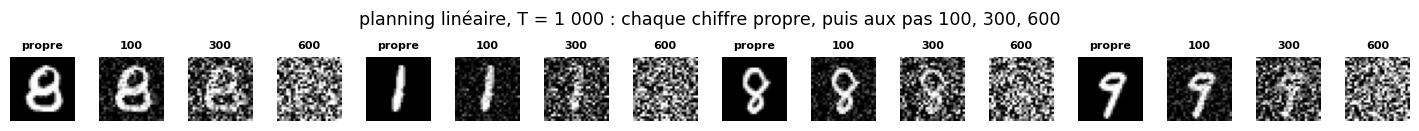

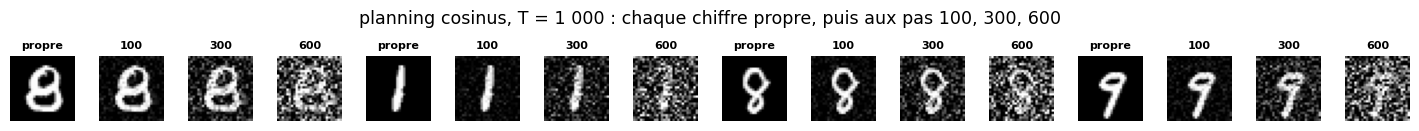

 linéaire pas 100 : SNR   8,710 · accuracy  95,7 % · classe la plus prédite : 1 (11 % des chiffres)
 linéaire pas 300 : SNR   0,657 · accuracy  45,0 % · classe la plus prédite : 2 (36 % des chiffres)


 linéaire pas 600 : SNR   0,027 · accuracy  12,6 % · classe la plus prédite : 2 (39 % des chiffres)
  cosinus pas 100 : SNR  34,833 · accuracy  96,3 % · classe la plus prédite : 1 (11 % des chiffres)
  cosinus pas 300 : SNR   3,693 · accuracy  93,7 % · classe la plus prédite : 2 (12 % des chiffres)


  cosinus pas 600 : SNR   0,517 · accuracy  39,5 % · classe la plus prédite : 2 (39 % des chiffres)
✅ Ex B5.13a : Bien joué !
✅ Ex B5.13b : C'est ça !


In [28]:
if any(answer is ... or answer is None for answer in [strong_13, cos600_13]):
    print("⏳ Ex B5.13 : écris d'abord tes deux prédictions dans la cellule précédente.")
else:
    # 1. four digits, clean then at the steps 100, 300 and 600 of each schedule (the same noise everywhere)
    for kind_13 in AB_13:
        row_13 = [X0_13[:4]] + [noisy_13(kind_13, s)[:4] for s in STEPS_13]
        show_images(np.stack(row_13, axis=1).reshape(-1, 1, 28, 28), ncol=16,
                    titles=[f"{s}" for _ in range(4) for s in ("propre",) + STEPS_13], size=0.9,
                    suptitle=f"planning {kind_13}, T = 1 000 : chaque chiffre propre, puis aux pas 100, 300, 600")

    # 2. the accuracy of the classifier, and the SNR, in each of the 6 cases
    acc_13 = {}
    for kind_13 in AB_13:
        for step_13 in STEPS_13:
            a_13 = AB_13[kind_13][step_13 - 1]
            pred_13 = wbd.predict(CLF, noisy_13(kind_13, step_13))
            acc_13[kind_13, step_13] = float(np.mean(pred_13 == DIGITS.labels.numpy()))
            top_13 = np.bincount(pred_13, minlength=10)
            print(f"{kind_13:>9} pas {step_13} : SNR {fr(a_13 / (1 - a_13), 3):>7} · accuracy {fr(100 * acc_13[kind_13, step_13], 1):>5} % "
                  f"· classe la plus prédite : {top_13.argmax()} ({fr(100 * top_13.max() / len(pred_13), 0)} % des chiffres)")
    wb.check("B5.13a", strong_13)
    wb.check("B5.13b", cos600_13)

Dans tes notes : pour chaque prédiction ratée, qu'est-ce qui t'a trompé ? À partir de quel SNR, à peu près, le classifieur décroche-t-il, et ton œil, sur les images ? Quelle classe le classifieur prédit-il quand il ne sait plus, et pourquoi un réseau entraîné sur des images propres se trompe-t-il ainsi sur du bruit qu'il n'a jamais vu ? Qu'est-ce que cela dit du débruiteur d'un modèle de diffusion, qui, lui, voit des images de tous les niveaux de bruit pendant son entraînement ?

### Ex B5.14 — q_sample : bruiter un batch d'images à des pas différents 🔨 ★★ ⏱️ 20 min
**Objectif :** écrire le bruitage en forme fermée d'un batch où chaque exemple a son propre pas.  
**Prérequis :** Ex B5.12 · ∂ B5.6 · fiche §205.2 (« La forme fermée », « Bruiter un batch » et le piège « `alpha_bars[t]` sans remise en forme ») · **Fil rouge :** MNIST · **mylearn :** `diffusion.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/diffusion.py` (créé par `python tools/start_chapter.py B5`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb5_diffusion.py -q` les lance tous dans un terminal.

**Contrat** de `q_sample(x0, t, alpha_bars, noise=None, rng=None)`, qui rend le couple `(x_t, noise)` :
- $\mathbf{x}_t = \sqrt{\bar\alpha_{t}}\,\mathbf{x}_0 + \sqrt{1 - \bar\alpha_{t}}\,\boldsymbol{\varepsilon}$ pour chaque exemple, avec **son** indice `t[n]` ; le coefficient est remis en forme `(N, 1, …, 1)`, quel que soit le nombre d'axes de `x0` (1-D, 2-D, `(N, C, H, W)`) ;
- `t` a **exactement un indice entier par exemple**, de forme `(N,)` : un `t` de longueur 1 pour un batch de plusieurs exemples lève `ValueError`, **même si NumPy saurait le diffuser** ; un indice hors de $[0, T)$ aussi ;
- `noise`, s'il est donné, a **exactement** la forme de `x0` (un bruit de forme `(2,)` pour `x0` de forme `(3, 2)` est refusé, même s'il se diffuse) ; sinon, **un seul** appel `rng.standard_normal(x0.shape)`, et c'est ce bruit qui est rendu (la cible de l'entraînement) ; `rng=None` : `np.random.default_rng()`, sans graine.

La première cellule de vérification essaie ta fonction sur l'exemple de la docstring, sur 6 chiffres de MNIST `(6, 1, 28, 28)` à 6 indices différents, sur un `x0` en 1-D, sur le bruit tiré par `rng`, et quatre refus ; elle montre les 6 chiffres bruités. La seconde lance les 19 tests de l'exercice (`-k "test_q_sample_"`).

Dans tes notes : que se passe-t-il, sans erreur, si tu multiplies `x0` de forme `(3, 1, 4, 3)` par `np.sqrt(alpha_bars[t])` de forme `(3,)` sans remise en forme (fiche, piège « `alpha_bars[t]` sans remise en forme ») ? Pourquoi rendre le bruit tiré, et pas seulement $\mathbf{x}_t$ ? Pourquoi refuser un `t` de longueur 1 que NumPy diffuserait volontiers ?

✅ Ex B5.14 : q_sample de l'exemple de la docstring : [[1.26491106, -0.63245553], [1.1, 0.8]], comme attendu.
✅ Ex B5.14 : 6 chiffres (6, 1, 28, 28), un pas par image : un tableau (6, 1, 28, 28), comme attendu.
✅ Ex B5.14 : le bruit rendu est celui reçu : un tableau (6, 1, 28, 28), comme attendu.
✅ Ex B5.14 : les entrées n'ont pas changé.
✅ Ex B5.14 : x0 en 1-D (3 exemples d'une valeur) : [0.79056942, 0.63403646, 3.0], comme attendu.
✅ Ex B5.14 : sans noise : le bruit de rng.standard_normal(x0.shape), rendu : [[-0.80193143, -1.324359], [-0.24836162, 0.42044524]], comme attendu.
✅ Ex B5.14 : t de longueur 1 pour 2 exemples : ValueError levée (t must have shape (2,), one index per sample, got (1,)).
✅ Ex B5.14 : un bruit de forme (2,) pour x0 de forme (2, 2) : ValueError levée (noise must have the shape of x0 (2, 2), got (2,)).
✅ Ex B5.14 : t = -1 : ValueError levée (every index of t must be in [0, 3), got values from -1 to 0).
✅ Ex B5.14 : t = T : ValueError levée (every index of t must 

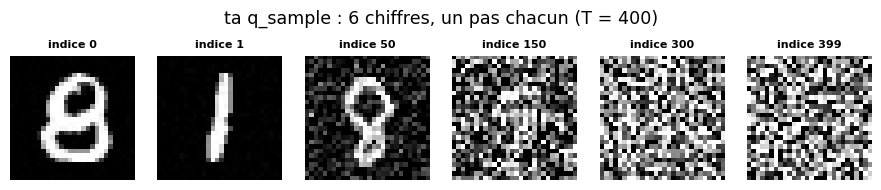

In [29]:
xt_14 = None
with checked("B5.14"):
    M = mylearn.diffusion
    ab_14 = np.array([0.9, 0.72, 0.36])
    x0_14 = np.array([[1.0, -1.0], [0.5, 0.0]])
    out_14, noise_14 = pair("B5.14", "q_sample", M.q_sample(x0_14.copy(), [0, 2], ab_14, noise=np.ones((2, 2))),
                            names=("x_t", "noise"))
    same("B5.14", "q_sample de l'exemple de la docstring", out_14,
         np.sqrt(ab_14[[0, 2]])[:, None] * x0_14 + np.sqrt(1 - ab_14[[0, 2]])[:, None], rtol=1e-6, atol=1e-6)

    ab_nb = wbd.alpha_bars(BETAS)
    imgs_14 = DIGITS.images[:6].double().numpy()
    t_14 = np.array([0, 1, 50, 150, 300, T_STEPS - 1])
    eps_14 = np.random.default_rng(14).standard_normal(imgs_14.shape)
    copies_14 = (imgs_14.copy(), t_14.copy(), eps_14.copy(), ab_nb.copy())
    xt_14, n_14 = pair("B5.14", "q_sample", M.q_sample(imgs_14, t_14, ab_nb, noise=eps_14), names=("x_t", "noise"))
    want_14 = np.sqrt(ab_nb[t_14])[:, None, None, None] * imgs_14 + np.sqrt(1 - ab_nb[t_14])[:, None, None, None] * eps_14
    if not same("B5.14", "6 chiffres (6, 1, 28, 28), un pas par image", xt_14, want_14, rtol=1e-6, atol=1e-6):
        xt_14 = None
    same("B5.14", "le bruit rendu est celui reçu", n_14, eps_14, rtol=1e-6, atol=1e-6)
    verdict("B5.14", all(np.array_equal(a, b) for a, b in zip((imgs_14, t_14, eps_14, ab_nb), copies_14)),
            "les entrées n'ont pas changé.", "q_sample a modifié une de ses entrées (x0, t, noise ou alpha_bars).")
    same("B5.14", "x0 en 1-D (3 exemples d'une valeur)", M.q_sample(np.array([0.5, -0.5, 1.0]), [0, 1, 2], ab_14,
                                                                    noise=np.array([1.0, 2.0, 3.0]))[0],
         np.sqrt(ab_14) * [0.5, -0.5, 1.0] + np.sqrt(1 - ab_14) * [1.0, 2.0, 3.0], rtol=1e-6, atol=1e-6)
    x_r, n_r = pair("B5.14", "q_sample", M.q_sample(x0_14, [1, 1], ab_14, rng=np.random.default_rng(5)),
                    names=("x_t", "noise"))
    same("B5.14", "sans noise : le bruit de rng.standard_normal(x0.shape), rendu", n_r,
         np.random.default_rng(5).standard_normal((2, 2)), rtol=1e-6, atol=1e-6)
    refuses("B5.14", "t de longueur 1 pour 2 exemples", lambda: M.q_sample(x0_14, [1], ab_14, noise=np.ones((2, 2))))
    refuses("B5.14", "un bruit de forme (2,) pour x0 de forme (2, 2)",
            lambda: M.q_sample(x0_14, [0, 1], ab_14, noise=np.ones(2)))
    refuses("B5.14", "t = -1", lambda: M.q_sample(x0_14, [-1, 0], ab_14, noise=np.ones((2, 2))))
    refuses("B5.14", "t = T", lambda: M.q_sample(x0_14, [0, 3], ab_14, noise=np.ones((2, 2))))
if xt_14 is not None:
    show_images(xt_14, titles=[f"indice {t}" for t in t_14], size=1.5,
                suptitle=f"ta q_sample : 6 chiffres, un pas chacun (T = {T_STEPS})")

In [30]:
if written(lambda: mylearn.diffusion.q_sample([0.0], [0], [0.5], noise=[0.0])):
    run_pytest_group(TEST_DIFF, impl="ref", keyword="test_q_sample_")   # 19 tests
else:
    print("⏳ Ex B5.14 : les tests attendent ta fonction q_sample.")

pytest: 19 passed, 190 deselected in 2.71s


### Ex B5.15 — Lire ᾱ_t, le rapport signal sur bruit et la grille de bruitage des deux plannings 📈 ★ ⏱️ 15 min
**Objectif :** lire sur une figure ce qui distingue les plannings, et voir un même chiffre se dissoudre dans le bruit.  
**Prérequis :** Ex B5.14 · ✏️ B5.3 · fiche §205.2 (« Le planning linéaire… », « Le planning cosinus… », « Le rapport signal sur bruit » et le piège « un SNR final qui n'est pas nul ») · **Fil rouge :** MNIST · **Parcours :** C

La figure trace $\bar\alpha$ (à gauche) et $\ln \operatorname{SNR}$ (à droite) de quatre plannings, en fonction de la **fraction de la chaîne** parcourue, (indice + 1)/$T$, pour les comparer malgré leurs $T$ différents : **L**, le linéaire de Ho et coll. ($T = 1\,000$) ; **C**, le cosinus ($T = 1\,000$) ; **D**, le linéaire raccourci à $T = 400$ avec les bornes par défaut ; **S**, le linéaire à $T = 400$ avec les bornes multipliées par $1\,000/T$, celui du notebook en mode rapide. Dessous, le même chiffre et le même bruit aux indices 0, 99, 199, …, 999 de L, puis de C. Rien ne dépend de ton code. Réponds en lisant la figure :
- a) `same_curve_15` : laquelle des deux courbes à $T = 400$ suit celle de L : `"D"` ou `"S"` ?
- b) `largest_end_15` : quel planning garde **le plus** de l'image à son dernier indice : `"L"`, `"C"`, `"D"` ou `"S"` ?
- c) `cos_above_15` : sur quelle part de la chaîne le $\ln \operatorname{SNR}$ de C est-il au-dessus de celui de L ? `"A"` moins de la moitié ; `"B"` entre la moitié et 90 % ; `"C"` plus de 95 %.

Dans tes notes : avec L, à partir de quelle colonne de la grille ne distingues-tu plus le chiffre, et avec C ? Que gagne le planning cosinus, en nombre de pas « utiles » (où il reste quelque chose à débruiter), d'après la figure et ✏️ B5.3 ? Pourquoi D est-il un piège, et que verrait un modèle entraîné avec lui, puis échantillonné à partir d'un bruit pur ?

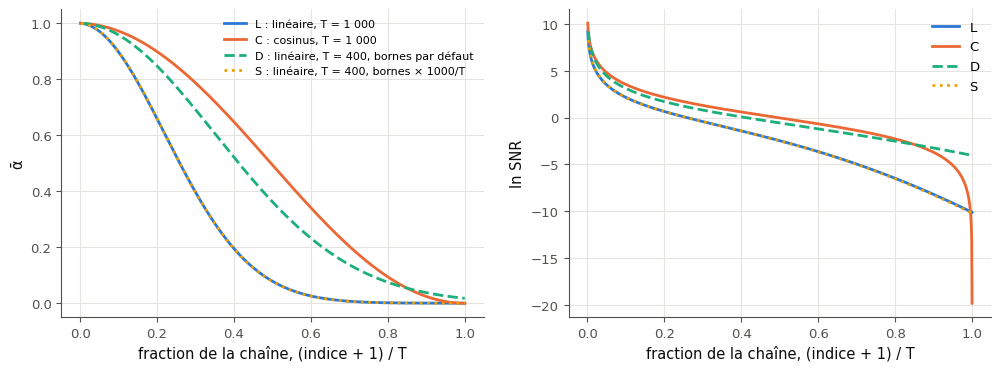

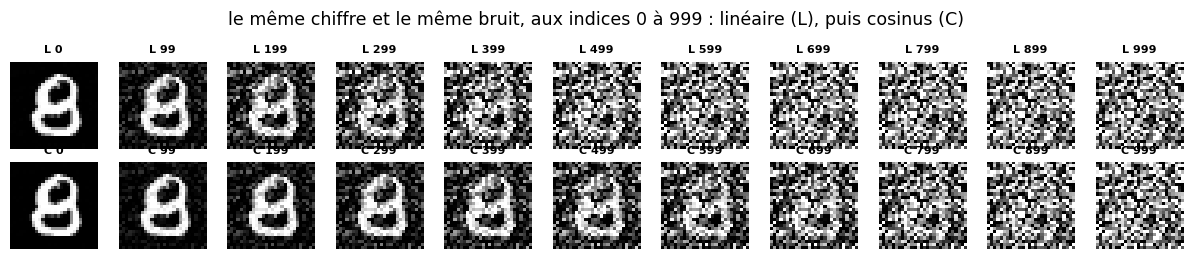

In [31]:
# The four schedules of the figure, against the fraction t / T of the chain (computed without your code)
SCHEDULES_15 = {"L": ("linéaire, T = 1 000", wbd.schedule_betas("linear", 1000)),
                "C": ("cosinus, T = 1 000", wbd.schedule_betas("cosine", 1000)),
                "D": ("linéaire, T = 400, bornes par défaut", np.linspace(1e-4, 0.02, 400)),
                "S": ("linéaire, T = 400, bornes × 1000/T", wbd.schedule_betas("linear", 400))}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for (letter, (label, betas)), style in zip(SCHEDULES_15.items(), ("-", "-", "--", ":")):
    ab = wbd.alpha_bars(betas)
    frac = np.arange(1, len(ab) + 1) / len(ab)
    ax1.plot(frac, ab, style, lw=2, label=f"{letter} : {label}")
    ax2.plot(frac, np.log(ab / (1 - ab)), style, lw=2, label=letter)
ax1.set_xlabel("fraction de la chaîne, (indice + 1) / T")
ax1.set_ylabel("ᾱ")
ax1.legend(fontsize=8)
ax2.set_xlabel("fraction de la chaîne, (indice + 1) / T")
ax2.set_ylabel("ln SNR")
ax2.legend()
plt.show()

# One digit at the indices 0, 99, ..., 999 of the two schedules of T = 1 000, with the same noise
idx_15 = [0] + list(range(99, 1000, 100))
x0_15 = DIGITS.images[0].double().numpy()
eps_15 = np.random.default_rng(15).standard_normal(x0_15.shape)
grid_15 = [math.sqrt(a) * x0_15 + math.sqrt(1 - a) * eps_15
           for key in ("L", "C") for a in wbd.alpha_bars(SCHEDULES_15[key][1])[idx_15]]
show_images(np.stack(grid_15), titles=[f"{k} {i}" for k in ("L", "C") for i in idx_15], ncol=len(idx_15), size=1.1,
            suptitle="le même chiffre et le même bruit, aux indices 0 à 999 : linéaire (L), puis cosinus (C)")

In [32]:
same_curve_15, largest_end_15, cos_above_15 = "S", "D", "C"

with wb.attempt("B5.15"):
    wb.check("B5.15a", same_curve_15)
with wb.attempt("B5.15"):
    wb.check("B5.15b", largest_end_15)
with wb.attempt("B5.15"):
    wb.check("B5.15c", cos_above_15)

✅ Ex B5.15a : Parfait !
✅ Ex B5.15b : Bravo !
✅ Ex B5.15c : Exact !


In [33]:
wb.record("B5.15a", "S", mistakes={"compare les deux courbes à T = 400 à la courbe L du graphique de gauche : laquelle se superpose ?": "D"})
wb.record("B5.15b", "D", mistakes={"lis la fin des courbes du graphique de droite : la courbe L finit-elle le plus haut ?": "L", "lis la fin des courbes du graphique de droite : la courbe C finit-elle le plus haut ?": "C", "lis la fin des courbes du graphique de droite : la courbe S finit-elle le plus haut ?": "S"})
wb.record("B5.15c", "C", mistakes={"suis les courbes C et L du graphique de droite : où se croisent-elles ?": "A", "suis les courbes C et L du graphique de droite jusqu'au dernier indice : où se croisent-elles ?": "B"})

WB_ANSWER {"hash": "0d733b3a883aebc74bae889a2be9181451a40ef6535cd0bb0cdc8498f1c9f35c", "id": "B5.15a", "kind": "str", "mistakes": {"70d14e8cd9736ce24853d849220b6e590506979a3602b81f6227578cf8cdfcce": "compare les deux courbes à T = 400 à la courbe L du graphique de gauche : laquelle se superpose ?"}}
📝 Ex B5.15a : réponse enregistrée (str).
WB_ANSWER {"hash": "c2e8f889c1fcc0cfc934517e2fb9a13993b6afec1059380433a28eab63092e03", "id": "B5.15b", "kind": "str", "mistakes": {"6019932b0c4ba9b5e96d2c315db587af9f921ec33cc67a87d89e0bf6b8586f31": "lis la fin des courbes du graphique de droite : la courbe L finit-elle le plus haut ?", "85ce77f168bb69e1b236963c949f2685cf7ec9388fccf97cb09718bea75c7ea6": "lis la fin des courbes du graphique de droite : la courbe S finit-elle le plus haut ?", "9e23ff474db1b766dd41682fc710694054471b0c7660d2d62e3645c91bbea4ca": "lis la fin des courbes du graphique de droite : la courbe C finit-elle le plus haut ?"}}
📝 Ex B5.15b : réponse enregistrée (str).
WB_ANSWER {"ha

### Ex B5.16 — q_posterior_mean_variance et predict_x0_from_eps 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire la moyenne et la variance du posterior d'un pas, et l'estimation de $\mathbf{x}_0$ à partir d'un bruit.  
**Prérequis :** Ex B5.14 · ∂ B5.7 · fiche §205.3 (« Le posterior : un pas en arrière quand on connaît $\mathbf{x}_0$ », « Prédire le bruit ») · **mylearn :** `diffusion.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/diffusion.py` (créé par `python tools/start_chapter.py B5`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb5_diffusion.py -q` les lance tous dans un terminal.

**Contrat**
- `q_posterior_mean_variance(x0, x_t, t, schedule)` rend le couple `(mean, variance)` :
  - `schedule` est le dictionnaire de `noise_schedule` (B5.12) ; tu y lis `posterior_mean_coef1`, `posterior_mean_coef2` et `posterior_variance` à l'indice de chaque exemple ;
  - `mean` a la forme de `x0` ; `variance` a la forme `(N, 1, …, 1)`, avec **autant d'axes que `x0`** (`(N,)` si `x0` est 1-D), et vaut 0 à l'indice 0 ;
  - mêmes règles que `q_sample` pour `t` (un indice entier par exemple, dans $[0, T)$) ; `x_t` a **exactement** la forme de `x0`, sans diffusion.
- `predict_x0_from_eps(x_t, t, eps, alpha_bars)` : $\hat{\mathbf{x}}_0 = \big(\mathbf{x}_t - \sqrt{1 - \bar\alpha_t}\,\boldsymbol{\varepsilon}\big) / \sqrt{\bar\alpha_t}$, de la forme de `x_t` ; `eps` a exactement la forme de `x_t` ; mêmes règles pour `t`. L'aller-retour `predict_x0_from_eps(q_sample(x0, t, ab, noise)[0], t, noise, ab)` redonne `x0`.

La première cellule de vérification essaie tes deux fonctions sur les exemples des docstrings, les formes de la variance en 4-D et en 1-D, un **Bayes numérique** en dimension 1 (le produit des deux densités gaussiennes de ∂ B5.7, normalisé sur une grille de 600 001 points, dont on lit la moyenne et la variance), l'aller-retour avec le vrai bruit et quatre refus. La seconde lance les 29 tests de l'exercice (`-k "test_q_posterior_mean_variance_ or test_predict_x0_from_eps_"`).

Dans tes notes : à l'indice 0, que valent la moyenne et la variance du posterior, et pourquoi ? D'où vient l'écart entre la moyenne du Bayes numérique et ta formule, et que faudrait-il pour le réduire ? Que devient l'erreur de $\hat{\mathbf{x}}_0$ quand le bruit prédit se trompe de 0,1, au pas 10 puis au dernier pas du planning du notebook ?

In [34]:
with checked("B5.16"):
    M = mylearn.diffusion
    s_16 = toy_schedule([0.1, 0.2, 0.5])
    x0_16 = np.array([[1.0, -1.0], [0.5, 0.0]])
    xt_16 = np.array([[1.2649, -0.6325], [1.1, 0.8]])
    copies_16 = (x0_16.copy(), xt_16.copy())
    mean_16, var_16 = pair("B5.16", "q_posterior_mean_variance",
                           M.q_posterior_mean_variance(x0_16, xt_16, [0, 2], s_16), names=("mean", "variance"))
    t_16 = np.array([0, 2])
    same("B5.16", "moyenne du posterior (exemple de la docstring)", mean_16,
         s_16["posterior_mean_coef1"][t_16][:, None] * x0_16 + s_16["posterior_mean_coef2"][t_16][:, None] * xt_16,
         rtol=1e-6, atol=1e-6)
    same("B5.16", "variance du posterior, forme (2, 1)", var_16, s_16["posterior_variance"][t_16][:, None],
         rtol=1e-6, atol=1e-6)
    verdict("B5.16", np.asarray(var_16).ravel()[0] == 0, "à l'indice 0, la variance vaut 0 exactement.",
            "à l'indice 0, la variance du posterior doit valoir 0 exactement.")
    verdict("B5.16", all(np.array_equal(a, b) for a, b in zip((x0_16, xt_16), copies_16)),
            "les entrées n'ont pas changé.", "q_posterior_mean_variance a modifié x0 ou x_t.")
    _, var4_16 = M.q_posterior_mean_variance(np.zeros((3, 1, 2, 2)), np.ones((3, 1, 2, 2)), [0, 1, 2], s_16)
    verdict("B5.16", np.shape(var4_16) == (3, 1, 1, 1), "variance de forme (3, 1, 1, 1) pour x0 de forme (3, 1, 2, 2).",
            f"pour x0 de forme (3, 1, 2, 2), la variance doit avoir la forme (3, 1, 1, 1), reçu {np.shape(var4_16)}.")
    _, var1_16 = M.q_posterior_mean_variance(np.zeros(3), np.ones(3), [0, 1, 2], s_16)
    verdict("B5.16", np.shape(var1_16) == (3,), "variance de forme (3,) pour x0 en 1-D.",
            f"pour x0 de forme (3,), la variance doit avoir la forme (3,), reçu {np.shape(var1_16)}.")

    # Bayes on a fine grid, in 1-D: prior q(x_{t-1} | x0) times the likelihood q(x_t | x_{t-1}), at index 2
    x0_b, xt_b, t_b = -0.4, 0.7, 2
    grid = np.linspace(-15, 15, 600_001)
    ab, a = s_16["alpha_bars"], s_16["alphas"]
    log_post = (-(grid - math.sqrt(ab[t_b - 1]) * x0_b) ** 2 / (2 * (1 - ab[t_b - 1]))
                - (xt_b - math.sqrt(a[t_b]) * grid) ** 2 / (2 * (1 - a[t_b])))
    w_b = np.exp(log_post - log_post.max())
    m_b = float((grid * w_b).sum() / w_b.sum())
    mean_b, var_b = M.q_posterior_mean_variance(np.array([x0_b]), np.array([xt_b]), [t_b], s_16)
    same("B5.16", "moyenne contre Bayes sur une grille (x0 = −0,4, x_t = 0,7, indice 2)", mean_b, [m_b], rtol=1e-6, atol=1e-6)
    same("B5.16", "variance contre Bayes sur une grille", var_b, [float(((grid - m_b) ** 2 * w_b).sum() / w_b.sum())],
         rtol=1e-6, atol=1e-6)
    refuses("B5.16", "x_t de forme (2, 3) pour x0 de forme (2, 2)",
            lambda: M.q_posterior_mean_variance(x0_16, np.ones((2, 3)), [0, 1], s_16))
    refuses("B5.16", "t = 3 avec T = 3", lambda: M.q_posterior_mean_variance(x0_16, xt_16, [0, 3], s_16))

    eps_16 = np.array([[0.3, -2.0], [1.0, 0.5]])
    ab_16 = s_16["alpha_bars"]
    noisy_16 = np.sqrt(ab_16[[1, 2]])[:, None] * x0_16 + np.sqrt(1 - ab_16[[1, 2]])[:, None] * eps_16
    same("B5.16", "predict_x0_from_eps : l'aller-retour avec le vrai bruit redonne x0",
         M.predict_x0_from_eps(noisy_16, [1, 2], eps_16, ab_16), x0_16, rtol=1e-6, atol=1e-6)
    refuses("B5.16", "predict_x0_from_eps avec eps de forme (2,)",
            lambda: M.predict_x0_from_eps(noisy_16, [1, 2], np.ones(2), ab_16))
    refuses("B5.16", "predict_x0_from_eps avec t = -1", lambda: M.predict_x0_from_eps(noisy_16, [-1, 2], eps_16, ab_16))

✅ Ex B5.16 : moyenne du posterior (exemple de la docstring) : [[1.0, -1.0], [0.67175144, 0.24748737]], comme attendu.
✅ Ex B5.16 : variance du posterior, forme (2, 1) : [[0.0], [0.21875]], comme attendu.
✅ Ex B5.16 : à l'indice 0, la variance vaut 0 exactement.
✅ Ex B5.16 : les entrées n'ont pas changé.
✅ Ex B5.16 : variance de forme (3, 1, 1, 1) pour x0 de forme (3, 1, 2, 2).
✅ Ex B5.16 : variance de forme (3,) pour x0 en 1-D.
✅ Ex B5.16 : moyenne contre Bayes sur une grille (x0 = −0,4, x_t = 0,7, indice 2) : [-0.04861359], comme attendu.
✅ Ex B5.16 : variance contre Bayes sur une grille : [0.21875], comme attendu.
✅ Ex B5.16 : x_t de forme (2, 3) pour x0 de forme (2, 2) : ValueError levée (x_t must have the shape of x0 (2, 2), got (2, 3)).
✅ Ex B5.16 : t = 3 avec T = 3 : ValueError levée (every index of t must be in [0, 3), got values from 0 to 3).
✅ Ex B5.16 : predict_x0_from_eps : l'aller-retour avec le vrai bruit redonne x0 : [[1.0, -1.0], [0.5, 0.0]], comme attendu.
✅ Ex B5.16 : 

In [35]:
if written(lambda: mylearn.diffusion.predict_x0_from_eps([0.0], [0], [0.0], [0.5])):
    run_pytest_group(TEST_DIFF, impl="ref", keyword="test_q_posterior_mean_variance_ or test_predict_x0_from_eps_")   # 29 tests
else:
    print("⏳ Ex B5.16 : les tests attendent tes fonctions.")

pytest: 29 passed, 180 deselected in 0.15s


### Ex B5.17 — ddpm_step et ddim_step 🔨 ★★★ ⏱️ 40 min
**Objectif :** écrire un pas d'échantillonnage DDPM et un pas DDIM, avec leurs cas particuliers.  
**Prérequis :** Ex B5.16 · ✏️ B5.4, B5.5 · fiche §205.5 (« L'algorithme », « Un pas à la main », le piège « l'échelle et le dernier pas »), §205.6 (« L'idée de DDIM », « Le paramètre η ») · **mylearn :** `diffusion.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/diffusion.py` (créé par `python tools/start_chapter.py B5`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb5_diffusion.py -q` les lance tous dans un terminal.

**Contrat**
- `ddpm_step(x_t, t, eps_pred, schedule, rng=None, variance="posterior", clip_x0=None)` rend $\mathbf{x}_{t-1}$, de la forme de `x_t` :
  - `t` est un **entier Python** de $[0, T)$, le même pour tout le batch ; −1 est refusé ;
  - `variance` vaut exactement `"posterior"` ($\tilde\beta_t$) ou `"beta"` ($\beta_t$), et se vérifie **même à $t = 0$** : la clause *Raises* de la docstring est inconditionnelle ;
  - sans `clip_x0`, la moyenne de l'algorithme 2 de Ho et coll. ; avec `clip_x0`, $\hat{\mathbf{x}}_0$ écrêté à `[-clip_x0, clip_x0]` (la borne reçue, pas 1), puis la moyenne du posterior ;
  - à $t > 0$, on ajoute `sqrt(var) * z` : **l'écart-type**, pas la variance ; $\mathbf{z}$ est tiré de `rng`, de la forme de `x_t`, sans dépendre des valeurs de `x_t` ni de `eps_pred` (deux appels avec la même graine tirent le même $\mathbf{z}$ : c'est ainsi que les tests isolent la moyenne) ; **aucun bruit à $t = 0$**.
- `ddim_step(x_t, t, t_prev, eps_pred, alpha_bars, eta=0.0, rng=None)` rend $\mathbf{x}_{t_{\text{prev}}}$ :
  - `t_prev = -1` veut dire « l'image propre » : $\bar\alpha_{\text{prev}} = 1$ ; **ne lis pas `alpha_bars[-1]`** ;
  - `ValueError` si $-1 \le t_{\text{prev}} < t < T$ n'est pas vérifié (`t_prev >= t` refusé), ou si `eta` est hors de $[0, 1]$, `nan` compris ;
  - avec `eta = 0`, **aucun nombre n'est tiré de `rng`** (les tests vérifient l'état du générateur).

La première cellule de vérification essaie `ddpm_step` à $t = 0$ (l'exemple de la docstring), sa moyenne à l'indice 2 (deux appels à la même graine, l'un avec `x_t` et `eps_pred` nuls, dont la différence est la moyenne), le rapport des bruits des deux variances, l'écrêtage à 0,5 et trois refus ; puis `ddim_step` avec le vrai bruit (vers −1, puis vers l'indice 0), l'état de `rng` avec `eta = 0` et trois refus. La seconde lance les 101 tests de l'exercice (`-k "test_ddpm_step_ or test_ddim_step_"`).

Dans tes notes : pourquoi n'ajoute-t-on pas de bruit au dernier pas, et que verrais-tu sur des images si tu en ajoutais (fiche, piège « l'échelle et le dernier pas ») ? Pourquoi `alpha_bars[-1]` serait-il une erreur silencieuse pour `t_prev = -1` ? Avec `eta = 1` et `t_prev = t - 1`, que vaut $\sigma^2$, et qu'en conclus-tu sur le lien entre DDIM et DDPM ?

In [36]:
with checked("B5.17"):
    M = mylearn.diffusion
    s_17 = toy_schedule([0.1, 0.2, 0.5])
    b, a, ab = s_17["betas"], s_17["alphas"], s_17["alpha_bars"]

    def algo2_17(x, t, eps):        # the mean of Algorithm 2 (Ho et al.)
        return (np.asarray(x) - b[t] / math.sqrt(1 - ab[t]) * np.asarray(eps)) / math.sqrt(a[t])

    x_17, e_17 = np.array([[0.5, -0.5]]), np.array([[1.0, 1.0]])
    same("B5.17", "ddpm_step à t = 0 (exemple de la docstring : pas de bruit)", M.ddpm_step(x_17, 0, e_17, s_17),
         algo2_17(x_17, 0, e_17), rtol=1e-6, atol=1e-6)
    xb_17 = np.random.default_rng(1).standard_normal((4, 3))
    eb_17 = np.random.default_rng(2).standard_normal((4, 3))
    copies_17 = (xb_17.copy(), eb_17.copy())
    full_17 = M.ddpm_step(xb_17, 2, eb_17, s_17, rng=np.random.default_rng(7))
    again_17 = M.ddpm_step(xb_17, 2, eb_17, s_17, rng=np.random.default_rng(7))
    verdict("B5.17", np.array_equal(np.asarray(full_17), np.asarray(again_17)), "même graine, même résultat.",
            "deux appels avec la même graine doivent rendre le même x_{t-1} : z est-il tiré de rng ?")
    noise_17 = np.asarray(M.ddpm_step(np.zeros((4, 3)), 2, np.zeros((4, 3)), s_17, rng=np.random.default_rng(7)))
    same("B5.17", "moyenne à l'indice 2 (même graine : la différence de deux appels)", np.asarray(full_17) - noise_17,
         algo2_17(xb_17, 2, eb_17), rtol=1e-6, atol=1e-6)
    beta_17 = np.asarray(M.ddpm_step(np.zeros((4, 3)), 2, np.zeros((4, 3)), s_17, rng=np.random.default_rng(7),
                                     variance="beta"))
    same("B5.17", "bruit avec variance='beta' contre 'posterior' : le rapport des écarts-types",
         beta_17, noise_17 * math.sqrt(b[2] / s_17["posterior_variance"][2]), rtol=1e-6, atol=1e-6)
    verdict("B5.17", all(np.array_equal(u, v) for u, v in zip((xb_17, eb_17), copies_17)), "les entrées n'ont pas changé.",
            "ddpm_step a modifié x_t ou eps_pred.")
    big_17 = np.array([[-3.0, 2.0, 0.1]])                                     # x0_hat far outside [-0.5, 0.5]
    xc_17 = np.array([[0.2, -0.1, 0.3]])
    x0hat_17 = (xc_17 - math.sqrt(1 - ab[1]) * big_17) / math.sqrt(ab[1])
    clipped_17 = (np.asarray(M.ddpm_step(xc_17, 1, big_17, s_17, rng=np.random.default_rng(3), clip_x0=0.5))
                  - np.asarray(M.ddpm_step(np.zeros((1, 3)), 1, np.zeros((1, 3)), s_17, rng=np.random.default_rng(3),
                                           clip_x0=0.5)))
    same("B5.17", "clip_x0 = 0.5 : moyenne du posterior de x̂₀ écrêté à [−0,5 ; 0,5]", clipped_17,
         s_17["posterior_mean_coef1"][1] * np.clip(x0hat_17, -0.5, 0.5) + s_17["posterior_mean_coef2"][1] * xc_17,
         rtol=1e-6, atol=1e-6)
    refuses("B5.17", "variance='betas' (inconnue), même à t = 0", lambda: M.ddpm_step(x_17, 0, e_17, s_17, variance="betas"))
    refuses("B5.17", "ddpm_step à t = 3 avec T = 3", lambda: M.ddpm_step(x_17, 3, e_17, s_17))
    refuses("B5.17", "ddpm_step à t = -1", lambda: M.ddpm_step(x_17, -1, e_17, s_17))

    x0_17 = np.array([[0.5, -1.0, 0.25]])
    eps_17 = np.array([[1.0, 0.0, -2.0]])
    xt_17 = math.sqrt(ab[2]) * x0_17 + math.sqrt(1 - ab[2]) * eps_17
    same("B5.17", "ddim_step de l'indice 2 à -1 avec le vrai bruit : x0", M.ddim_step(xt_17, 2, -1, eps_17, ab), x0_17,
         rtol=1e-6, atol=1e-6)
    same("B5.17", "ddim_step de l'indice 2 à 0 avec le vrai bruit : le x au pas 0 du même bruit",
         M.ddim_step(xt_17, 2, 0, eps_17, ab), math.sqrt(ab[0]) * x0_17 + math.sqrt(1 - ab[0]) * eps_17,
         rtol=1e-6, atol=1e-6)
    rng_17 = np.random.default_rng(11)
    state_17 = copy.deepcopy(rng_17.bit_generator.state)
    M.ddim_step(xt_17, 2, 1, eps_17, ab, eta=0.0, rng=rng_17)
    verdict("B5.17", rng_17.bit_generator.state == state_17, "avec eta = 0, rng n'a pas servi.",
            "avec eta = 0, ddim_step ne doit tirer aucun nombre de rng (son état a changé).")
    refuses("B5.17", "ddim_step avec t_prev = t", lambda: M.ddim_step(xt_17, 2, 2, eps_17, ab))
    refuses("B5.17", "ddim_step avec eta = 1.5", lambda: M.ddim_step(xt_17, 2, 1, eps_17, ab, eta=1.5))
    refuses("B5.17", "ddim_step avec eta = nan", lambda: M.ddim_step(xt_17, 2, 1, eps_17, ab, eta=float("nan")))

✅ Ex B5.17 : ddpm_step à t = 0 (exemple de la docstring : pas de bruit) : [[0.19371294, -0.86037961]], comme attendu.
✅ Ex B5.17 : même graine, même résultat.
✅ Ex B5.17 : moyenne à l'indice 2 (même graine : la différence de deux appels) : un tableau (4, 3), comme attendu.
✅ Ex B5.17 : bruit avec variance='beta' contre 'posterior' : le rapport des écarts-types : un tableau (4, 3), comme attendu.
✅ Ex B5.17 : les entrées n'ont pas changé.
✅ Ex B5.17 : clip_x0 = 0.5 : moyenne du posterior de x̂₀ écrêté à [−0,5 ; 0,5] : [[0.40270312, -0.37075929, 0.29315248]], comme attendu.
✅ Ex B5.17 : variance='betas' (inconnue), même à t = 0 : ValueError levée (variance must be 'posterior' or 'beta', got 'betas').
✅ Ex B5.17 : ddpm_step à t = 3 avec T = 3 : ValueError levée (t must be in [0, 3), got 3).
✅ Ex B5.17 : ddpm_step à t = -1 : ValueError levée (t must be in [0, 3), got -1).
✅ Ex B5.17 : ddim_step de l'indice 2 à -1 avec le vrai bruit : x0 : [[0.5, -1.0, 0.25]], comme attendu.
✅ Ex B5.17 : dd

In [37]:
if written(lambda: mylearn.diffusion.ddim_step([0.0], 1, 0, [0.0], [0.9, 0.8])):
    run_pytest_group(TEST_DIFF, impl="ref", keyword="test_ddpm_step_ or test_ddim_step_")   # 101 tests
else:
    print("⏳ Ex B5.17 : les tests attendent tes fonctions.")

pytest: 101 passed, 108 deselected in 2.69s


### Ex B5.18 — Avec le vrai bruit, DDPM et DDIM retrouvent-ils x_0 ? Contrôle sur des données 2D 🔬 ★★ ⏱️ 25 min
**Objectif :** enchaîner tes pas DDPM et DDIM avec le vrai bruit, pour savoir lesquels doivent retrouver $\mathbf{x}_0$ exactement : le contrôle de ta librairie avant tout entraînement.  
**Prérequis :** Ex B5.17 · fiche §205.5 (« L'algorithme »), §205.6 (« L'idée de DDIM », « Le paramètre η ») · **Fil rouge :** synthétique · **Parcours :** M, C

Un réseau parfait prédirait le **vrai** bruit. Sans réseau, on peut donc éprouver une chaîne d'échantillonnage : partir d'une donnée $\mathbf{x}_0$ connue, la bruiter jusqu'au dernier indice, puis remonter en donnant aux pas « le vrai bruit » à la place de $\boldsymbol{\varepsilon}_\theta$. La fiche dit qu'**un** pas DDIM vers l'indice −1 rend alors $\mathbf{x}_0$. Mais quel est « le vrai bruit » au milieu d'une chaîne, et qu'en est-il des chaînes entières ?

**Contrat**
- `true_noise_18(x_t, t, x0, alpha_bars)` : le bruit $\boldsymbol{\varepsilon}$ tel que $\mathbf{x}_t = \sqrt{\bar\alpha_t}\,\mathbf{x}_0 + \sqrt{1 - \bar\alpha_t}\,\boldsymbol{\varepsilon}$, pour un indice `t` entier (le même pour tout le batch) ; un nouveau tableau, de la forme de `x_t` ;
- `ddpm_chain_18(x0, eps, schedule, rng, oracle=False)` : $\mathbf{x}$ à l'indice $T - 1$ fait de `x0` et `eps` par la forme fermée, puis ta `ddpm_step` de l'indice $T - 1$ à 0 (avec `rng`, sans écrêtage, la variance par défaut), avec pour `eps_pred` le bruit **initial** `eps` à chaque pas (`oracle=False`), ou le vrai bruit du $\mathbf{x}$ **courant**, `true_noise_18(x, t, x0, …)` (`oracle=True`) ; rend le $\mathbf{x}$ final ;
- `ddim_chain_18(x0, eps, alpha_bars, timesteps, eta=0.0, rng=None)` : $\mathbf{x}$ à l'indice `timesteps[0]` fait de `x0` et `eps`, puis ta `ddim_step` de chaque indice de la sous-séquence décroissante `timesteps` au suivant, et du dernier à −1, toujours avec `eps_pred = eps`, le bruit initial ; rend le $\mathbf{x}$ final.

La cellule de vérification essaie tes trois fonctions sur un planning de 3 pas, contre la chaîne écrite pas à pas. Puis l'expérience prend 500 points de l'anneau de 8 gaussiennes (`wbd.ring`), le planning du notebook (ta `noise_schedule` de `BETAS`), et mesure l'écart maximal entre $\mathbf{x}_0$ et la fin de cinq chaînes : DDPM avec le bruit initial ; DDPM avec le vrai bruit du $\mathbf{x}$ courant ; DDIM ($\eta = 0$) sur tous les indices ; DDIM ($\eta = 0$) sur 10 indices (`wbd.ddim_timesteps(T_STEPS, 10)`) ; DDIM ($\eta = 1$) sur tous les indices. Réponds ensuite, d'après le tableau, par `True` ou `False` : la chaîne retrouve-t-elle $\mathbf{x}_0$ à $10^{-6}$ près ?
- a) `ddpm_fixed_18` : DDPM, bruit initial à chaque pas ;
- b) `ddpm_oracle_18` : DDPM, vrai bruit du $\mathbf{x}$ courant ;
- c) `ddim_ten_18` : DDIM, $\eta = 0$, 10 pas ;
- d) `ddim_eta1_18` : DDIM, $\eta = 1$, tous les pas.

Dans tes notes : pourquoi le bruit initial n'est-il plus « le vrai bruit » d'un $\mathbf{x}_t$ de la chaîne DDPM après le premier pas, alors qu'il le reste tout au long de la chaîne DDIM avec $\eta = 0$ ? Pourquoi la chaîne DDPM avec le vrai bruit courant finit-elle exactement sur $\mathbf{x}_0$, quelle que soit sa trajectoire (regarde le dernier pas) ? Pourquoi le nombre de pas de DDIM ne change-t-il rien ici, alors qu'il comptera avec un réseau ? Quelle erreur de ta librairie ce contrôle aurait-il attrapée (un indice décalé, $\bar\alpha$ au lieu de $\sqrt{\bar\alpha}$), et laquelle pas ?

✅ Ex B5.18 : true_noise_18 redonne le bruit de x_t : [[0.5, 1.0], [-1.5, 0.2]], comme attendu.
✅ Ex B5.18 : true_noise_18 n'a pas modifié x_t.
✅ Ex B5.18 : ddpm_chain_18 (T = 3, bruit initial) contre la chaîne pas à pas : [[-0.76522844, -1.28487178], [2.67205375, 0.40777282]], comme attendu.
✅ Ex B5.18 : ddim_chain_18 sur [2, 0] (η = 0) contre la formule : [[0.3, -0.7], [1.2, 0.1]], comme attendu.
DDPM, bruit initial à chaque pas : écart maximal à x0 = 8,5e+02
   DDPM, vrai bruit du x courant : écart maximal à x0 = 5,6e-15
         DDIM η = 0, les 400 pas : écart maximal à x0 = 2,3e-13
              DDIM η = 0, 10 pas : écart maximal à x0 = 4,5e-14
         DDIM η = 1, les 400 pas : écart maximal à x0 = 6,0e+02
✅ Ex B5.18 : les trois chaînes exactes retrouvent x0 à moins de 1e-9.


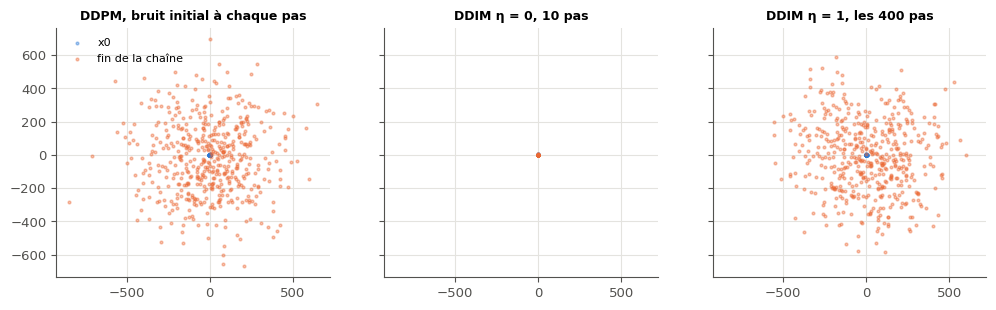

✅ Ex B5.18a : Bien joué !
✅ Ex B5.18b : C'est ça !
✅ Ex B5.18c : Parfait !
✅ Ex B5.18d : Bravo !


In [38]:
def true_noise_18(x_t, t, x0, alpha_bars):
    """The noise eps such that x_t = sqrt(alpha_bar_t) x0 + sqrt(1 - alpha_bar_t) eps, for one step index t
    (an int, the same for the whole batch); a new array with the shape of x_t."""
    ab = float(np.asarray(alpha_bars)[t])
    return (np.asarray(x_t, dtype=float) - math.sqrt(ab) * np.asarray(x0, dtype=float)) / math.sqrt(1 - ab)


def ddpm_chain_18(x0, eps, schedule, rng, oracle=False):
    """The whole DDPM chain: x at index T - 1 made from x0 and eps by the closed form, then ddpm_step (your library)
    from index T - 1 down to 0, with as eps_pred the initial eps (oracle=False) or the true noise of the current x
    (true_noise_18, oracle=True). Returns the final x."""
    ab = schedule["alpha_bars"]
    T = len(ab)
    x = math.sqrt(ab[T - 1]) * np.asarray(x0, dtype=float) + math.sqrt(1 - ab[T - 1]) * np.asarray(eps, dtype=float)
    for t in range(T - 1, -1, -1):
        eps_pred = true_noise_18(x, t, x0, ab) if oracle else eps
        x = mylearn.diffusion.ddpm_step(x, t, eps_pred, schedule, rng=rng)
    return x


def ddim_chain_18(x0, eps, alpha_bars, timesteps, eta=0.0, rng=None):
    """The DDIM chain on the decreasing sub-sequence timesteps: x at index timesteps[0] made from x0 and eps by the
    closed form, then ddim_step (your library) from each index to the next one, and from the last one to -1, always
    with eps_pred = eps, the initial noise. Returns the final x."""
    steps = [int(t) for t in timesteps] + [-1]
    a0 = float(alpha_bars[steps[0]])
    x = math.sqrt(a0) * np.asarray(x0, dtype=float) + math.sqrt(1 - a0) * np.asarray(eps, dtype=float)
    for t, t_prev in zip(steps[:-1], steps[1:]):
        x = mylearn.diffusion.ddim_step(x, t, t_prev, eps, alpha_bars, eta=eta, rng=rng)
    return x


ddpm_fixed_18, ddpm_oracle_18, ddim_ten_18, ddim_eta1_18 = False, True, True, False


chains_ok_18 = False
with checked("B5.18"):
    s_18 = toy_schedule([0.1, 0.2, 0.5])
    ab_18 = s_18["alpha_bars"]
    x0_c = np.array([[0.3, -0.7], [1.2, 0.1]])
    e_c = np.array([[0.5, 1.0], [-1.5, 0.2]])
    xt_c = math.sqrt(ab_18[2]) * x0_c + math.sqrt(1 - ab_18[2]) * e_c
    copy_c = xt_c.copy()
    ok_18 = same("B5.18", "true_noise_18 redonne le bruit de x_t", true_noise_18(xt_c, 2, x0_c, ab_18), e_c,
                 rtol=1e-9, atol=1e-12)
    verdict("B5.18", np.array_equal(xt_c, copy_c), "true_noise_18 n'a pas modifié x_t.", "true_noise_18 a modifié x_t.")
    ok_18 &= np.array_equal(xt_c, copy_c)
    # the DDPM chain with T = 3 and the initial noise, written step by step without your functions
    rng_a, rng_b = np.random.default_rng(4), np.random.default_rng(4)
    x_ref = xt_c.copy()
    for t in (2, 1, 0):
        mean = (x_ref - s_18["betas"][t] / math.sqrt(1 - ab_18[t]) * e_c) / math.sqrt(s_18["alphas"][t])
        x_ref = mean if t == 0 else mean + np.asarray(mylearn.diffusion.ddpm_step(
            np.zeros_like(x_ref), t, np.zeros_like(x_ref), s_18, rng=rng_b))
    ok_18 &= same("B5.18", "ddpm_chain_18 (T = 3, bruit initial) contre la chaîne pas à pas",
                  ddpm_chain_18(x0_c, e_c, s_18, rng_a), x_ref, rtol=1e-6, atol=1e-6)
    x_dd = math.sqrt(ab_18[2]) * x0_c + math.sqrt(1 - ab_18[2]) * e_c
    x0h = (x_dd - math.sqrt(1 - ab_18[2]) * e_c) / math.sqrt(ab_18[2])
    ok_18 &= same("B5.18", "ddim_chain_18 sur [2, 0] (η = 0) contre la formule", ddim_chain_18(x0_c, e_c, ab_18, [2, 0]),
                  x0h, rtol=1e-6, atol=1e-6)
    chains_ok_18 = bool(ok_18)
if not chains_ok_18:
    print("⏳ Ex B5.18 : l'expérience attend tes trois fonctions (et ddpm_step, ddim_step de B5.17).")
else:
    X0_18 = wbd.ring(500, seed=18)                                   # 500 points of the ring of 8 Gaussians
    EPS_18 = np.random.default_rng(180).standard_normal(X0_18.shape)
    SCHED_18 = mylearn.diffusion.noise_schedule(BETAS)
    AB_18 = SCHED_18["alpha_bars"]
    runs_18 = {"DDPM, bruit initial à chaque pas": ddpm_chain_18(X0_18, EPS_18, SCHED_18, np.random.default_rng(1)),
               "DDPM, vrai bruit du x courant": ddpm_chain_18(X0_18, EPS_18, SCHED_18, np.random.default_rng(1), oracle=True),
               f"DDIM η = 0, les {T_STEPS} pas": ddim_chain_18(X0_18, EPS_18, AB_18, np.arange(T_STEPS - 1, -1, -1)),
               "DDIM η = 0, 10 pas": ddim_chain_18(X0_18, EPS_18, AB_18, wbd.ddim_timesteps(T_STEPS, 10)),
               f"DDIM η = 1, les {T_STEPS} pas": ddim_chain_18(X0_18, EPS_18, AB_18, np.arange(T_STEPS - 1, -1, -1),
                                                                eta=1.0, rng=np.random.default_rng(2))}
    ERRORS_18 = {name: float(np.abs(np.asarray(x) - X0_18).max()) for name, x in runs_18.items()}
    for name, err in ERRORS_18.items():
        print(f"{name:>32} : écart maximal à x0 = {fr_e(err)}")
    verdict("B5.18", max(ERRORS_18[k] for k in list(ERRORS_18)[1:4]) < 1e-9,
            "les trois chaînes exactes retrouvent x0 à moins de 1e-9.",
            "une chaîne qui devrait être exacte s'écarte de x0 de plus de 1e-9 : relis tes trois fonctions.")
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True)
    for ax, name in zip(axes, [list(runs_18)[0], list(runs_18)[3], list(runs_18)[4]]):
        ax.scatter(*X0_18.T, s=4, alpha=0.4, label="x0")
        ax.scatter(*np.asarray(runs_18[name]).T, s=4, alpha=0.4, label="fin de la chaîne")
        ax.set_title(name, fontsize=9)
        ax.set_aspect("equal")
    axes[0].legend(fontsize=8)
    plt.show()
    for letter, answer in zip("abcd", [ddpm_fixed_18, ddpm_oracle_18, ddim_ten_18, ddim_eta1_18]):
        with wb.attempt("B5.18"):
            wb.check(f"B5.18{letter}", answer)

In [39]:
wb.record("B5.18a", False, mistakes={"relis l'écart de la première ligne du tableau": True})
wb.record("B5.18b", True, mistakes={"relis l'écart de la deuxième ligne du tableau": False})
wb.record("B5.18c", True, mistakes={"relis l'écart de la quatrième ligne du tableau": False})
wb.record("B5.18d", False, mistakes={"relis l'écart de la dernière ligne du tableau": True})

WB_ANSWER {"hash": "52afd4015cf940a2145abb1f91b4a76ddf2a082601db183e1b097bacfdf7a29f", "id": "B5.18a", "kind": "bool", "mistakes": {"ecc08c6a37511bf1b76456dd855e785173adb6f2612265eeb21808221a470cca": "relis l'écart de la première ligne du tableau"}}
📝 Ex B5.18a : réponse enregistrée (bool).
WB_ANSWER {"hash": "bc384163679c2df81951723ef8b3b8cfe19b93d3f290cd375558a21101a8aacc", "id": "B5.18b", "kind": "bool", "mistakes": {"f0866915345a51279154f81e2fc7d82e2d7ecbc193b5b21fe8e98bc70a7eb356": "relis l'écart de la deuxième ligne du tableau"}}
📝 Ex B5.18b : réponse enregistrée (bool).
WB_ANSWER {"hash": "d0b32a88a842dd9e7855cbe92362a868949d9e6ce126fc62f038daedcde60f5f", "id": "B5.18c", "kind": "bool", "mistakes": {"6c42fb840e08fc45736751781f1bb60f4ebefb06a23f78f1bf10fe25063fbee8": "relis l'écart de la quatrième ligne du tableau"}}
📝 Ex B5.18c : réponse enregistrée (bool).
WB_ANSWER {"hash": "9f0e26d55bd03dd66a9473dc74031a87714402a38d1c1814d98f51776c48bff0", "id": "B5.18d", "kind": "bool", "mis

## Partie B · Jouets 2D : un MLP débruiteur, puis le flow matching

Avant les images, des points du plan : l'**anneau de 8 gaussiennes** (`wbd.ring` : 8 centres sur un cercle de rayon 1,5, écart-type 0,15 autour de chacun ; sa variance par coordonnée, 1,15, est proche de celle du bruit). Tout s'y voit d'un coup d'œil et s'entraîne en une dizaine de secondes. Tu y entraînes un MLP qui prédit le bruit, conditionné par le pas comme le U-Net de la fiche, puis tu l'échantillonnes avec ta `ddpm_step` (B5.19) ; puis tu entraînes le **même** MLP à prédire une vitesse (flow matching, fiche §205.9) et tu compares les deux échantillonneurs à nombre de pas égal (B5.20).

**Mesurer la qualité.** Une distance de Fréchet en 2D ne compare que les moyennes et les covariances : un nuage gaussien de variance 1 a presque celles de l'anneau. On prend la **distance de Wasserstein en tranches** (`wbd.sliced_wasserstein`) : la moyenne, sur 64 directions du plan, de la distance de Wasserstein du ch. 27 entre les deux projections (l'écart moyen de leurs valeurs triées). La fonction `quality(points)` rend cette distance à `REAL_B` (2 000 points de l'anneau), la part des points à moins de trois écarts-types d'un centre et le nombre de modes atteints (`wbd.mode_report`) ; la cellule suivante affiche ses deux repères, deux échantillons de l'anneau et du bruit pur.

**Encoder le pas.** Le MLP reçoit une **position entière**, comme le U-Net : l'indice $t$ du pas pour la diffusion ; pour le flow matching, dont le temps $s$ est continu sur $[0, 1]$, on le prend sur une grille de 1 000 valeurs, $s = u / 1\,000$ avec $u$ entier de 1 à 1 000 (`wbd.FM_POSITIONS` = 1 001 positions). La position $p$ est encodée par la ligne $p$ de ta `positional_encoding` de B3 (`mylearn.attention`) : si tu n'as pas écrit `attention.py`, la référence la remplace (une ligne ℹ️ le dit) ; s'il existe sans cette fonction, la vérification te le signale.

`SETTINGS_B` donne le budget des deux entraînements : 3 000 itérations, des batches de 512 points, AdamW au learning rate 2e-3 (environ 10 s chacun sur un CPU à deux cœurs). `wbd` contient une solution de référence (`Denoiser2D`, `train_toy`, `sample_toy_ddpm`…) : la vérification s'en sert pour comparer tes fonctions ; ne la lis qu'une fois les tiennes écrites.

In [40]:
# Part B: the ring of 8 Gaussians, the settings of the two trainings, the measures of quality
DATA_B = torch.tensor(wbd.ring(50_000, seed=1900), dtype=torch.float32)   # 50 000 training points
REAL_B = wbd.ring(2000, seed=2020)                                         # 2 000 other points, for the measures
SETTINGS_B = dict(wbd.TOY_SETTINGS)                    # 3 000 iterations, batches of 512, AdamW at 2e-3 (≈ 10 s)
SCHED_B = toy_schedule(BETAS)                          # the schedule of the notebook, T = T_STEPS (without your code)
FLOOR_B = wbd.sliced_wasserstein(wbd.ring(2000, seed=2021), REAL_B)        # two samples of the ring itself
BLOB_B = wbd.sliced_wasserstein(np.random.default_rng(3).standard_normal((2000, 2)), REAL_B)   # pure noise


def quality(points):
    """(sliced Wasserstein distance to REAL_B, share of points on a mode, modes reached) of 2 000 points."""
    report = wbd.mode_report(points)
    return wbd.sliced_wasserstein(points, REAL_B), report["on_mode"], report["modes"]


print(f"distance de Wasserstein en tranches : {fr(FLOOR_B, 3)} entre deux échantillons de l'anneau, "
      f"{fr(BLOB_B, 3)} pour du bruit gaussien.")

distance de Wasserstein en tranches : 0,052 entre deux échantillons de l'anneau, 0,260 pour du bruit gaussien.


### Ex B5.19 — Diffusion en 2D : un MLP débruiteur conditionné par le pas de temps, entraîné puis échantillonné 📦 ★★ ⏱️ 30 min
**Objectif :** entraîner un MLP à prédire le bruit de points 2D, puis générer de nouveaux points avec ta `ddpm_step`.  
**Prérequis :** Ex B5.17 · B3 (`positional_encoding`, B3.15) · fiche §205.3 (« La loss simplifiée »), §205.4 (« Dire au réseau quel est le pas »), §205.5 (« L'algorithme ») · **Fil rouge :** synthétique · **Parcours :** R, M, C

**Contrat**
- `Denoiser2D_19(n_positions, t_dim=32, hidden=128)`, un `nn.Module` :
  - un buffer **non persistant** `pe` (`register_buffer(..., persistent=False)` : il n'entre pas dans le `state_dict`), la table `positional_encoding(n_positions, t_dim)` de ta librairie (B3) en float32 ;
  - `net = nn.Sequential(nn.Linear(2 + t_dim, hidden), nn.SiLU(), nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, 2))` ;
  - `forward(x, t)` : `x` de forme `(N, 2)` en float32, `t` de forme `(N,)` en int64 → `net` appliqué aux coordonnées **suivies** de l'encodage de la position, `(N, 2)`.
- `train_19(model, data, alpha_bars, n_iters, batch_size, lr, generator)` entraîne `model` sur place et rend la liste des `n_iters` loss (des floats Python) :
  - un `torch.optim.AdamW(model.parameters(), lr=lr)`, avec ses autres réglages par défaut ;
  - à chaque itération, **dans cet ordre**, trois tirages par `generator` : les indices du batch `torch.randint(len(data), (batch_size,))`, les pas `torch.randint(0, T, (batch_size,))` ($T$ = `len(alpha_bars)`), le bruit `torch.randn((batch_size, 2))` ; puis $\mathbf{x}_t$ par la forme fermée en float32, la loss `F.mse_loss(model(x_t, t), eps)`, les gradients et un pas de l'optimiseur.
- `sample_19(model, n, schedule, generator, rng)` : `n` points par l'échantillonnage ancestral : $\mathbf{x}$ = `torch.randn((n, 2), generator=generator)` converti en float64 NumPy, puis, pour $t$ de $T - 1$ à 0, la prédiction du réseau (sans gradient, en float32) et ta `ddpm_step(x, t, eps, schedule, rng=rng)` (variance du posterior, sans écrêtage) ; rend un tableau float64 `(n, 2)`.

La cellule de vérification contrôle ton MLP (noms et formes du `state_dict`, le buffer `pe`, la sortie aux mêmes poids que le modèle du contrat), 5 itérations de `train_19` contre la recette du contrat (mêmes tirages, mêmes loss) et `sample_19` sur 6 points. La cellule suivante entraîne ton MLP avec les réglages de `SETTINGS_B` sur `DATA_B`, génère 2 000 points, trace la loss et les points, et vérifie qu'ils couvrent les 8 modes (une distance en tranches sous 0,2, plus de 80 % des points sur un mode). Le temps affiché est une mesure, pas une réponse.

Dans tes notes : la loss descend-elle vers 0 ? Pourquoi pas, alors que le modèle génère de bons points (pense à ce que vaut l'erreur sur $\boldsymbol{\varepsilon}$ aux petits indices, où $\mathbf{x}_t$ ne dit presque rien du bruit) ? Combien de passes du réseau a coûté l'échantillonnage ? Que se passe-t-il si tu supprimes l'encodage du pas (des zéros à la place) ?

In [41]:
class Denoiser2D_19(nn.Module):
    """MLP that predicts the noise of a 2-D point x_t at the integer position t (contract of the statement)."""

    def __init__(self, n_positions, t_dim=32, hidden=128):
        super().__init__()
        table = mylearn.attention.positional_encoding(n_positions, t_dim)        # your encoding of B3
        self.register_buffer("pe", torch.tensor(table, dtype=torch.float32), persistent=False)
        self.net = nn.Sequential(nn.Linear(2 + t_dim, hidden), nn.SiLU(), nn.Linear(hidden, hidden), nn.SiLU(),
                                 nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, 2))

    def forward(self, x, t):
        return self.net(torch.cat([x, self.pe[t]], dim=1))


def train_19(model, data, alpha_bars, n_iters, batch_size, lr, generator):
    """Train model to predict the noise (recipe of the contract); returns the list of the losses (floats)."""
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    ab = torch.tensor(np.asarray(alpha_bars), dtype=torch.float32)
    losses = []
    for _ in range(n_iters):
        x0 = data[torch.randint(len(data), (batch_size,), generator=generator)]
        t = torch.randint(0, len(ab), (batch_size,), generator=generator)
        eps = torch.randn((batch_size, 2), generator=generator)
        a = ab[t][:, None]
        loss = F.mse_loss(model(a.sqrt() * x0 + (1 - a).sqrt() * eps, t), eps)
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses


def sample_19(model, n, schedule, generator, rng):
    """n points by DDPM ancestral sampling with your ddpm_step; a float64 array (n, 2)."""
    x = torch.randn((n, 2), generator=generator).double().numpy()
    with torch.no_grad():
        for t in range(len(schedule["alpha_bars"]) - 1, -1, -1):
            eps = model(torch.tensor(x, dtype=torch.float32), torch.full((n,), t, dtype=torch.long)).double().numpy()
            x = mylearn.diffusion.ddpm_step(x, t, eps, schedule, rng=rng)
    return x


model_ok_19 = False
with checked("B5.19"):
    torch.manual_seed(0)
    mine_19 = Denoiser2D_19(50)
    ref_19 = wbd.Denoiser2D(50)
    names_19 = {k: tuple(v.shape) for k, v in mine_19.state_dict().items()}
    want_19 = {k: tuple(v.shape) for k, v in ref_19.state_dict().items()}
    verdict("B5.19", names_19 == want_19, "noms et formes des paramètres : ceux du contrat (net.0 à net.6).",
            f"le state_dict doit avoir les noms et formes {want_19} ; reçu {names_19} (le buffer pe est-il non persistant ?).")
    pe_19 = getattr(mine_19, "pe", None)
    verdict("B5.19", pe_19 is not None and tuple(pe_19.shape) == (50, 32)
            and np.allclose(pe_19.double().numpy(), wbd.sinusoidal_table(50, 32), atol=1e-6),
            "le buffer pe est la table de positional_encoding(50, 32) (B3).",
            "self.pe doit être la table positional_encoding(n_positions, t_dim) de B3, en float32.")
    with torch.no_grad():
        for p_ in ref_19.parameters():
            p_.add_(0.3 * torch.randn(p_.shape))                    # weights far from the initialisation
    mine_19.load_state_dict(ref_19.state_dict())
    xq_19, tq_19 = torch.randn(7, 2), torch.tensor([0, 3, 9, 17, 25, 33, 49])
    with torch.no_grad():
        same("B5.19", "sortie de ton MLP contre celle du contrat, aux mêmes poids", mine_19(xq_19, tq_19),
             ref_19(xq_19, tq_19), rtol=1e-5, atol=1e-6)
    # 5 iterations of train_19 against the recipe of the contract (the same draws, the same model at the start)
    ab_19 = toy_schedule(np.linspace(1e-3, 0.2, 50))["alpha_bars"]
    a_19, b_19 = copy.deepcopy(ref_19), copy.deepcopy(ref_19)
    got_19 = train_19(a_19, DATA_B, ab_19, 5, 64, 1e-3, torch.Generator().manual_seed(5))
    want_l19 = wbd.train_toy(b_19, DATA_B, 5, 64, 1e-3, torch.Generator().manual_seed(5), ab_19)
    if returned("B5.19", "train_19", got_19):
        same("B5.19", "les 5 premières loss de train_19 contre la recette du contrat", got_19, want_l19, rtol=1e-5, atol=1e-6)
        same("B5.19", "les poids après 5 itérations", a_19.net[0].weight, b_19.net[0].weight, rtol=1e-4, atol=1e-6)
    sched_19 = toy_schedule(np.linspace(1e-3, 0.2, 50))
    b_19.eval()
    pts_19 = sample_19(b_19, 6, sched_19, torch.Generator().manual_seed(8), np.random.default_rng(9))
    if returned("B5.19", "sample_19", pts_19):
        model_ok_19 = same("B5.19", "sample_19 (6 points, T = 50) contre l'échantillonnage DDPM du contrat", pts_19,
                           wbd.sample_toy_ddpm(b_19, 6, sched_19["alpha_bars"], torch.Generator().manual_seed(8),
                                               np.random.default_rng(9)), rtol=1e-5, atol=1e-5)

✅ Ex B5.19 : noms et formes des paramètres : ceux du contrat (net.0 à net.6).
✅ Ex B5.19 : le buffer pe est la table de positional_encoding(50, 32) (B3).
✅ Ex B5.19 : sortie de ton MLP contre celle du contrat, aux mêmes poids : un tableau (7, 2), comme attendu.
✅ Ex B5.19 : les 5 premières loss de train_19 contre la recette du contrat : [332.949646, 229.56652832, 157.03587341, 137.88955688, 61.96021652], comme attendu.
✅ Ex B5.19 : les poids après 5 itérations : un tableau (128, 34), comme attendu.
✅ Ex B5.19 : sample_19 (6 points, T = 50) contre l'échantillonnage DDPM du contrat : un tableau (6, 2), comme attendu.


entraînement et échantillonnage : 10 s (une mesure, pas une réponse)
loss moyenne des 200 dernières itérations : 0,232 ; distance en tranches 0,073 ; 90,5 % des points sur un mode ; 8 modes sur 8


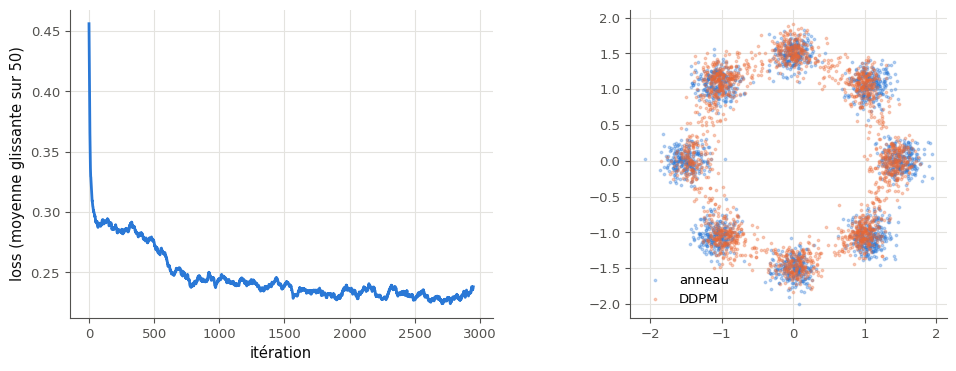

✅ Ex B5.19 : les points générés couvrent les 8 modes, à distance de l'anneau proche de celle de deux échantillons.


In [42]:
# Train on the ring, then 2 000 points by DDPM (≈ 10 s of training)
MODEL_19 = None
if not model_ok_19:
    print("⏳ Ex B5.19 : l'entraînement attend ton MLP, train_19 et sample_19 (cellule précédente sans ❌).")
else:
    torch.manual_seed(19)
    MODEL_19 = Denoiser2D_19(T_STEPS)
    start_19 = time.perf_counter()
    LOSSES_19 = train_19(MODEL_19, DATA_B, SCHED_B["alpha_bars"], SETTINGS_B["n_iters"], SETTINGS_B["batch_size"],
                         SETTINGS_B["lr"], torch.Generator().manual_seed(190))
    MODEL_19.eval()
    POINTS_19 = sample_19(MODEL_19, 2000, SCHED_B, torch.Generator().manual_seed(191), np.random.default_rng(192))
    swd_19, on_19, modes_19 = quality(POINTS_19)
    print(f"entraînement et échantillonnage : {time.perf_counter() - start_19:.0f} s (une mesure, pas une réponse)")
    print(f"loss moyenne des 200 dernières itérations : {fr(np.mean(LOSSES_19[-200:]), 3)} ; distance en tranches "
          f"{fr(swd_19, 3)} ; {fr(100 * on_19, 1)} % des points sur un mode ; {modes_19} modes sur 8")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(np.convolve(LOSSES_19, np.ones(50) / 50, mode="valid"))
    ax1.set_xlabel("itération")
    ax1.set_ylabel("loss (moyenne glissante sur 50)")
    ax2.scatter(*REAL_B.T, s=3, alpha=0.3, label="anneau")
    ax2.scatter(*POINTS_19.T, s=3, alpha=0.3, label="DDPM")
    ax2.set_aspect("equal")
    ax2.legend()
    plt.show()
    verdict("B5.19", swd_19 < 0.2 and on_19 > 0.8 and modes_19 == 8,
            "les points générés couvrent les 8 modes, à distance de l'anneau proche de celle de deux échantillons.",
            "les points générés sont loin de l'anneau (distance ≥ 0,2, moins de 80 % sur un mode, ou un mode manqué) : "
            "relis l'entraînement (le pas t donné au modèle, la cible) et l'échantillonnage.")

### Ex B5.20 — Flow matching en 2D : même MLP, cible « vitesse » et intégration d'Euler 🔬 ★★★ ⏱️ 40 min
**Objectif :** entraîner le même MLP à prédire une vitesse, l'intégrer par la méthode d'Euler, et comparer la qualité au DDIM du modèle de B5.19 selon le nombre de pas, sans présumer du gagnant.  
**Prérequis :** Ex B5.19 · fiche §205.9 (« Flow matching et rectified flow », encadré « la méthode d'Euler »), §205.6 (« L'idée de DDIM ») · **Fil rouge :** synthétique · **Parcours :** M, C

Le flow matching relie la donnée et le bruit par la ligne droite $\mathbf{x}_s = (1 - s)\,\mathbf{x}_0 + s\,\boldsymbol{\varepsilon}$ (fiche §205.9) et fait prédire au réseau la vitesse $\mathbf{v} = \boldsymbol{\varepsilon} - \mathbf{x}_0$ ; on génère en suivant le champ des vitesses de $s = 1$ (le bruit) à $s = 0$. La question : à nombre de pas égal, ces points valent-ils mieux que ceux de DDIM avec le modèle de B5.19, qui prédit le bruit ? Même MLP, même budget d'entraînement, mêmes points de départ.

**Contrat**
- `train_fm_20(model, data, n_iters, batch_size, lr, generator)` : la recette de `train_19`, à trois différences près : le deuxième tirage est la position `u = torch.randint(1, 1001, (batch_size,))`, et $s = u / 1\,000$ ; l'entrée est $\mathbf{x}_s$ ; la cible est $\boldsymbol{\varepsilon} - \mathbf{x}_0$, et le modèle reçoit la position `u` (un `Denoiser2D_19(wbd.FM_POSITIONS)`, 1 001 positions). Rend la liste des loss.
- `euler_20(model, n, n_steps, generator)` : $\mathbf{x}$ = `torch.randn((n, 2), generator=generator)`, puis `n_steps` pas d'Euler égaux, de $s = 1$ vers $s = 0$ : au pas $k$ (de 0 à `n_steps` − 1), la position `round(1000 * (1 - k / n_steps))` et $\mathbf{x} \leftarrow \mathbf{x} - \mathbf{v}/\text{n\_steps}$ ; sans gradient ; rend un tableau float64 `(n, 2)`.
- `ddim_20(model, n, n_steps, alpha_bars, generator)` : $\mathbf{x}$ = `torch.randn((n, 2), generator=generator)` en float64 NumPy, puis ta `ddim_step` ($\eta = 0$) d'un indice au suivant de `wbd.ddim_timesteps(T, n_steps)` (de $T - 1$ à 0, `n_steps` indices), et du dernier à −1 ; rend un tableau float64 `(n, 2)`.

La cellule de vérification compare tes trois fonctions aux fonctions du contrat (5 itérations, puis 1, 3 et 8 pas d'Euler, 1, 4 et 50 pas de DDIM). La cellule suivante (environ 15 s) entraîne le modèle de flow matching avec `SETTINGS_B`, puis mesure la distance en tranches de 2 000 points de chaque échantillonneur pour chaque nombre de pas de `STEPS_20`, avec le modèle de B5.19 pour DDIM ; elle trace les deux courbes, avec, en bandes, les **cinq graines** du protocole complet (`FULL_20`, précalculé avec les mêmes cellules ; ta graine est la première), et montre les points à 5 pas. Réponds ensuite d'après le tableau du protocole complet, **pour toutes ses graines** :
- a) `fewest_20` : le plus petit nombre de pas de `STEPS_20` à partir duquel la distance d'Euler est au plus le triple de sa distance à 100 pas ;
- b) `better5_20` : à 5 pas, lequel a la plus petite distance : `"D"` (DDIM) ou `"E"` (Euler) ?

Dans tes notes : pourquoi DDIM à 1 ou 2 pas rend-il des points aussi loin (regarde $\hat{\mathbf{x}}_0$ au dernier indice, et la division par $\sqrt{\bar\alpha_t}$) ? Et Euler à 1 pas, où envoie-t-il tous les points (fiche, encadré 🧮 « la MSE apprend une moyenne ») ? Le gagnant change-t-il avec le nombre de pas ? À 100 pas, compare le DDIM et le DDPM de B5.19 sur le même modèle : que conclus-tu de l'aléa de l'échantillonnage ancestral ? Qu'est-ce que la comparaison ne dit pas (un seul jeu de données, des réglages choisis pour l'un ou l'autre, la loss de chaque modèle) ?

In [43]:
STEPS_20 = (1, 2, 5, 10, 20, 50, 100)                       # numbers of sampling steps of the comparison
# The full protocol (tools/chapters/history_chB5.py): the same cells with 5 seeds (seed 0 is yours), the
# distance of 2 000 points to REAL_B for each number of steps; DDIM depends on T, so on the mode
FULL_20 = {
    "seeds": [0, 1, 2, 3, 4],
    "DDIM (bruit prédit, B5.19)": [[6.8056, 6.6697, 0.4236, 0.2481, 0.1714, 0.147, 0.1404], [6.1998, 6.0638, 0.2993, 0.166, 0.1385, 0.1305, 0.1267], [5.4068, 5.2936, 0.2236, 0.1235, 0.0988, 0.0944, 0.0941], [6.4142, 6.281, 0.4477, 0.2235, 0.142, 0.1142, 0.1103], [6.4573, 6.3336, 0.2506, 0.1266, 0.0929, 0.0793, 0.078]] if FAST_MODE else [[3.3798, 3.3267, 0.4504, 0.2462, 0.1769, 0.1459, 0.1325], [5.2962, 5.2241, 0.3061, 0.1471, 0.1043, 0.0893, 0.0885], [7.4443, 7.3397, 0.4981, 0.1764, 0.1343, 0.1246, 0.1249], [4.9974, 4.9374, 0.3049, 0.1222, 0.0803, 0.0845, 0.0825], [5.2451, 5.1807, 0.2499, 0.0878, 0.09, 0.0913, 0.0908]],
    "Euler (vitesse prédite)": [[0.9146, 0.3714, 0.1034, 0.0814, 0.0774, 0.0751, 0.0749], [0.8998, 0.3423, 0.0725, 0.0441, 0.0403, 0.0414, 0.0404], [0.8987, 0.3947, 0.0889, 0.0574, 0.0502, 0.0509, 0.0505], [0.8727, 0.3712, 0.1305, 0.1156, 0.109, 0.1006, 0.1009], [0.8969, 0.3872, 0.084, 0.0549, 0.0442, 0.0393, 0.0361]],
}

In [44]:
def train_fm_20(model, data, n_iters, batch_size, lr, generator):
    """Train model to predict the velocity eps - x0 at s = u / 1000 (recipe of the contract); returns the losses."""
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    losses = []
    for _ in range(n_iters):
        x0 = data[torch.randint(len(data), (batch_size,), generator=generator)]
        u = torch.randint(1, 1001, (batch_size,), generator=generator)
        eps = torch.randn((batch_size, 2), generator=generator)
        s = (u.float() / 1000)[:, None]
        loss = F.mse_loss(model((1 - s) * x0 + s * eps, u), eps - x0)
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses


def euler_20(model, n, n_steps, generator):
    """n points by Euler integration of the flow from s = 1 to s = 0 in n_steps steps; a float64 array (n, 2)."""
    x = torch.randn((n, 2), generator=generator)
    with torch.no_grad():
        for k in range(n_steps):
            u = round(1000 * (1 - k / n_steps))                     # s = 1, 1 - 1/n, ..., 1/n
            x = x - model(x, torch.full((n,), u, dtype=torch.long)) / n_steps
    return x.double().numpy()


def ddim_20(model, n, n_steps, alpha_bars, generator):
    """n points by DDIM (eta = 0, your ddim_step) on wbd.ddim_timesteps(T, n_steps), then to -1; float64 (n, 2)."""
    x = torch.randn((n, 2), generator=generator).double().numpy()
    steps = [int(t) for t in wbd.ddim_timesteps(len(alpha_bars), n_steps)] + [-1]
    with torch.no_grad():
        for t, t_prev in zip(steps[:-1], steps[1:]):
            eps = model(torch.tensor(x, dtype=torch.float32), torch.full((n,), t, dtype=torch.long)).double().numpy()
            x = mylearn.diffusion.ddim_step(x, t, t_prev, eps, alpha_bars)
    return x


fm_ok_20 = False
with checked("B5.20"):
    torch.manual_seed(1)
    ref_20 = wbd.Denoiser2D(wbd.FM_POSITIONS)
    a_20, b_20 = copy.deepcopy(ref_20), copy.deepcopy(ref_20)
    got_20 = train_fm_20(a_20, DATA_B, 5, 64, 1e-3, torch.Generator().manual_seed(6))
    if returned("B5.20", "train_fm_20", got_20):
        same("B5.20", "les 5 premières loss de train_fm_20 contre la recette du contrat", got_20,
             wbd.train_toy(b_20, DATA_B, 5, 64, 1e-3, torch.Generator().manual_seed(6), flow=True), rtol=1e-5, atol=1e-6)
    b_20.eval()
    ok_20 = True
    for steps_c in (1, 3, 8):
        ok_20 &= same("B5.20", f"euler_20 en {steps_c} pas contre l'intégration du contrat",
                      euler_20(b_20, 5, steps_c, torch.Generator().manual_seed(7)),
                      wbd.sample_toy_euler(b_20, 5, steps_c, torch.Generator().manual_seed(7)), rtol=1e-5, atol=1e-5)
    torch.manual_seed(2)
    eps_net_20 = wbd.Denoiser2D(50).eval()
    ab_20 = toy_schedule(np.linspace(1e-3, 0.2, 50))["alpha_bars"]
    for steps_c in (1, 4, 50):
        ok_20 &= same("B5.20", f"ddim_20 en {steps_c} pas contre le DDIM du contrat",
                      ddim_20(eps_net_20, 5, steps_c, ab_20, torch.Generator().manual_seed(8)),
                      wbd.sample_toy_ddim(eps_net_20, 5, steps_c, ab_20, torch.Generator().manual_seed(8)),
                      rtol=1e-5, atol=1e-5)
    fm_ok_20 = bool(ok_20)

✅ Ex B5.20 : les 5 premières loss de train_fm_20 contre la recette du contrat : [2.30227089, 2.33523893, 2.23584676, 2.14624381, 2.26137614], comme attendu.
✅ Ex B5.20 : euler_20 en 1 pas contre l'intégration du contrat : un tableau (5, 2), comme attendu.
✅ Ex B5.20 : euler_20 en 3 pas contre l'intégration du contrat : un tableau (5, 2), comme attendu.
✅ Ex B5.20 : euler_20 en 8 pas contre l'intégration du contrat : un tableau (5, 2), comme attendu.
✅ Ex B5.20 : ddim_20 en 1 pas contre le DDIM du contrat : un tableau (5, 2), comme attendu.
✅ Ex B5.20 : ddim_20 en 4 pas contre le DDIM du contrat : un tableau (5, 2), comme attendu.
✅ Ex B5.20 : ddim_20 en 50 pas contre le DDIM du contrat : un tableau (5, 2), comme attendu.


entraînement du flow matching : 9 s


pas :      1       2       5      10      20      50     100
DDIM (bruit prédit, B5.19) :  6,806   6,670   0,424   0,248   0,171   0,147   0,140
Euler (vitesse prédite) :  0,915   0,371   0,103   0,081   0,077   0,075   0,075


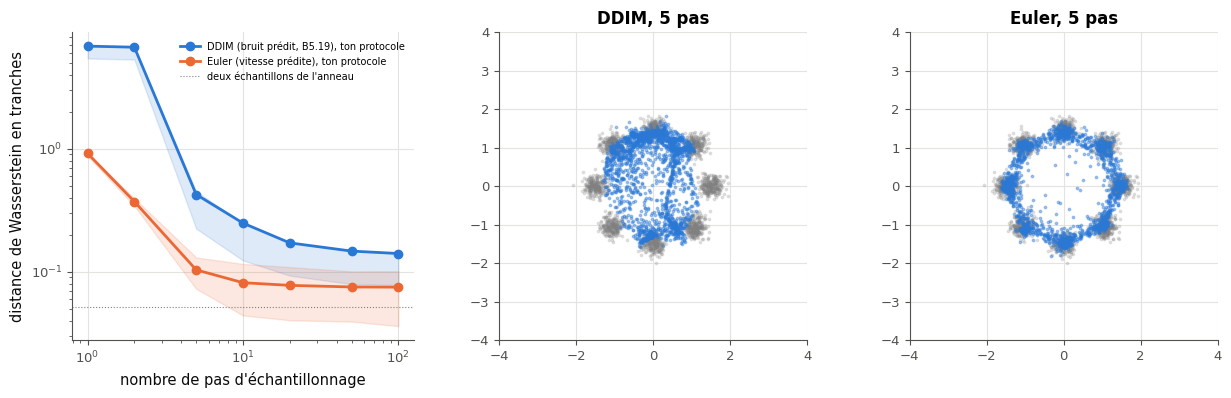

protocole complet (5 graines, bandes du graphique) : distance médiane par nombre de pas
DDIM (bruit prédit, B5.19) :  6,414   6,281   0,299   0,166   0,139   0,114   0,110
Euler (vitesse prédite) :  0,899   0,371   0,089   0,057   0,050   0,051   0,051


In [45]:
# The flow matching model, the same MLP and the same budget as in B5.19, then both samplers from 1 to 100 steps
MEASURED_20 = None
if not (fm_ok_20 and MODEL_19 is not None):
    print("⏳ Ex B5.20 : l'expérience attend tes trois fonctions (cellule précédente sans ❌) et le modèle de B5.19.")
else:
    torch.manual_seed(20)
    MODEL_FM_20 = Denoiser2D_19(wbd.FM_POSITIONS)
    start_20 = time.perf_counter()
    LOSSES_FM_20 = train_fm_20(MODEL_FM_20, DATA_B, SETTINGS_B["n_iters"], SETTINGS_B["batch_size"], SETTINGS_B["lr"],
                               torch.Generator().manual_seed(200))
    MODEL_FM_20.eval()
    print(f"entraînement du flow matching : {time.perf_counter() - start_20:.0f} s")
    MEASURED_20 = {"DDIM (bruit prédit, B5.19)": [], "Euler (vitesse prédite)": []}
    SAMPLES_20 = {}
    for n_20 in STEPS_20:
        pts_d = ddim_20(MODEL_19, 2000, n_20, SCHED_B["alpha_bars"], torch.Generator().manual_seed(201))
        pts_e = euler_20(MODEL_FM_20, 2000, n_20, torch.Generator().manual_seed(201))
        SAMPLES_20[n_20] = (pts_d, pts_e)
        MEASURED_20["DDIM (bruit prédit, B5.19)"].append(quality(pts_d)[0])
        MEASURED_20["Euler (vitesse prédite)"].append(quality(pts_e)[0])
    print("pas :", "  ".join(f"{n:>6}" for n in STEPS_20))
    for name, values in MEASURED_20.items():
        print(f"{name} :", "  ".join(f"{fr(v, 3):>6}" for v in values))
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))
    for (name, values), color in zip(MEASURED_20.items(), ("C0", "C1")):
        ax1.plot(STEPS_20, values, "o-", color=color, label=f"{name}, ton protocole")
        rows = np.array(FULL_20[name])                         # (seeds, steps) of the full protocol
        ax1.fill_between(STEPS_20, rows.min(axis=0), rows.max(axis=0), color=color, alpha=0.15)
    ax1.axhline(FLOOR_B, color="gray", lw=0.8, ls=":", label="deux échantillons de l'anneau")
    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.set_xlabel("nombre de pas d'échantillonnage")
    ax1.set_ylabel("distance de Wasserstein en tranches")
    ax1.legend(fontsize=7)
    for ax, (pts, title) in zip((ax2, ax3), ((SAMPLES_20[5][0], "DDIM, 5 pas"), (SAMPLES_20[5][1], "Euler, 5 pas"))):
        ax.scatter(*REAL_B.T, s=3, alpha=0.2, color="gray")
        ax.scatter(*np.clip(pts, -4, 4).T, s=3, alpha=0.4)
        ax.set_xlim(-4, 4)
        ax.set_ylim(-4, 4)
        ax.set_aspect("equal")
        ax.set_title(title)
    plt.show()
    print(f"protocole complet ({len(FULL_20['seeds'])} graines, bandes du graphique) : distance médiane par nombre de pas")
    for name in MEASURED_20:
        print(f"{name} :", "  ".join(f"{fr(v, 3):>6}" for v in np.median(np.array(FULL_20[name]), axis=0)))

In [46]:
fewest_20, better5_20 = 5, "E"

with wb.attempt("B5.20"):
    wb.check("B5.20a", fewest_20)
with wb.attempt("B5.20"):
    wb.check("B5.20b", better5_20)

✅ Ex B5.20a : Bravo !
✅ Ex B5.20b : Exact !


In [47]:
wb.record("B5.20a", 5, mistakes={"relis la ligne Euler du protocole complet : à 1 pas, la distance est-elle au plus le triple de celle à 100 pas pour toutes les graines ?": 1, "relis la ligne Euler du protocole complet : à 2 pas, la distance est-elle au plus le triple de celle à 100 pas pour toutes les graines ?": 2, "relis la ligne Euler du protocole complet : à 10 pas, la distance est-elle au plus le triple de celle à 100 pas pour toutes les graines ?": 10, "relis la ligne Euler du protocole complet : à 20 pas, la distance est-elle au plus le triple de celle à 100 pas pour toutes les graines ?": 20, "relis la ligne Euler du protocole complet : à 50 pas, la distance est-elle au plus le triple de celle à 100 pas pour toutes les graines ?": 50, "relis la ligne Euler du protocole complet : à 100 pas, la distance est-elle au plus le triple de celle à 100 pas pour toutes les graines ?": 100}, fractional="on demande un nombre de pas de STEPS_20", choices=[1, 2, 5, 10, 20, 50, 100])
wb.record("B5.20b", "E", mistakes={"relis la colonne des 5 pas du tableau du protocole complet": "D"})

WB_ANSWER {"choices": ["1", "2", "5", "10", "20", "50", "100"], "fractional": "on demande un nombre de pas de STEPS_20", "hash": "8f7d83f8f8eaa0ea6fe3152b3373e5ae570c4ca1619cdd5ce80770333d6ecc1a", "id": "B5.20a", "kind": "int", "magnitude": 0, "mistakes": {"a88bdad8b402104f01b863ecf5d3223fa602939e757c703cce3a570939eeaa43": "relis la ligne Euler du protocole complet : à 1 pas, la distance est-elle au plus le triple de celle à 100 pas pour toutes les graines ?", "b65c438cc9d746c88a6a35d8747b954b92f730230b060216dfc3e71cfeb700b3": "relis la ligne Euler du protocole complet : à 2 pas, la distance est-elle au plus le triple de celle à 100 pas pour toutes les graines ?", "d231a4b49fa78d99d9579d48b9af85d1c24ebdbd7501b77bad4864bc6cde54f6": "relis la ligne Euler du protocole complet : à 10 pas, la distance est-elle au plus le triple de celle à 100 pas pour toutes les graines ?", "e1fe5fd447661b1d8ac651b32ca95432cb58b180140a3e5474a35a28e71b6cab": "relis la ligne Euler du protocole complet : à 50 

## Partie C · Le U-Net sur MNIST et Fashion-MNIST

Place aux images. Tu écris d'abord le **U-Net minuscule** de la fiche (B5.21), que la suite de la partie entraîne sur MNIST, échantillonne, conditionne par la classe et évalue. Les images sont ramenées dans $[-1, 1]$ par une seule fonction, `wbd.to_signed` ($x / 127{,}5 - 1$ pour des octets) : le réseau, la forme fermée et l'écrêtage de $\hat{\mathbf{x}}_0$ supposent tous cette échelle, et `wbd.to_unit` les ramène dans $[0, 1]$ pour l'affichage. Les données d'entraînement sont un sous-ensemble **figé** (`wbd.image_subset`) : 10 000 images en mode rapide, les 60 000 en mode complet, toujours dans le même ordre, de sorte que les petits sous-ensembles sont inclus dans les grands.

### Ex B5.21 — Un U-Net minuscule en PyTorch : blocs convolutifs, connexions de saut, encodage du pas de temps 📦 ★★★ ⏱️ 50 min
**Objectif :** écrire le U-Net de la fiche, avec son encodage du pas et une classe facultative, et le valider étage par étage contre le modèle du contrat.  
**Prérequis :** Ex B5.19 · B3 (`positional_encoding`) · ch. 21 (convolutions de stride 2, convolution transposée) · fiche §205.4 (« Le U-Net et ses connexions de saut », « Un bloc résiduel conditionné par le pas ») · §205.7 (« Donner la classe au réseau ») · **Fil rouge :** MNIST · **Parcours :** R, C

**Contrat.** Les noms des modules comptent : la suite du chapitre sauvegarde ton modèle par son `state_dict` et le recharge.
- `ResBlock_21(c_in, c_out, t_dim)` : le bloc de la fiche (§205.4), avec ses six sous-modules `norm1` (`nn.GroupNorm(8, c_in)`), `conv1` (3×3, `padding=1`), `time` (`nn.Linear(t_dim, c_out)`), `norm2`, `conv2` et `skip` (une convolution 1×1 si `c_in != c_out`, sinon `nn.Identity()`) ; `forward(x, temb)` : $\mathbf{h}$ = `conv1(silu(norm1(x)))`, plus `time(temb)` en un biais par canal, puis `conv2(silu(norm2(h)))`, plus `skip(x)`.
- `TinyUNet_21(n_steps, channels=(32, 64, 128), t_dim=128, n_classes=None)`, avec `c1, c2, c3 = channels` :
  - `self.config`, le dictionnaire `{"n_steps", "channels" (une liste), "t_dim", "n_classes"}` de ses arguments : il suffit à reconstruire le modèle (`TinyUNet_21(**config)`) ;
  - un buffer **non persistant** `pe` : la table `positional_encoding(n_steps, t_dim)` de B3, en float32 ; `t_mlp = nn.Sequential(nn.Linear(t_dim, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))` ;
  - si `n_classes` est un entier : `class_emb = nn.Embedding(n_classes + 1, t_dim)`, dont la **dernière** ligne, d'indice `n_classes`, est la classe vide $\varnothing$ de la guidance sans classifieur ;
  - `inp` (1 → `c1`, 3×3) ; l'encodeur `d1 = ResBlock_21(c1, c1)`, `down1` (convolution 3×3 de stride 2, `padding=1`, `c1` → `c1` : 28 → 14), `d2 = ResBlock_21(c1, c2)`, `down2` (`c2` → `c2`, 14 → 7) ; `mid = ResBlock_21(c2, c3)` ; le décodeur `up2` (`nn.ConvTranspose2d(c3, c2, 4, stride=2, padding=1)` : 7 → 14), `u2 = ResBlock_21(2 * c2, c2)`, `up1` (`c2` → `c1`, 14 → 28), `u1 = ResBlock_21(2 * c1, c1)` ; `out` (`c1` → 1, 3×3) ; tous les blocs reçoivent `t_dim` ;
  - `forward(x, t, y=None)` : `x` de forme `(N, 1, 28, 28)`, `t` des indices int64 `(N,)`, `y` des classes int64 `(N,)` de 0 à `n_classes` (la classe vide si `y` est `None`) ; `temb = t_mlp(pe[t])`, plus `class_emb(y)` si le modèle a des classes ; puis `h1 = d1(inp(x))`, `h2 = d2(down1(h1))`, `h = mid(down2(h2))`, `h = u2(cat([up2(h), h2]))`, `h = u1(cat([up1(h), h1]))` (la concaténation sur l'axe des canaux, **la sortie du décodeur d'abord**), et `out(h)` : la prédiction du bruit, `(N, 1, 28, 28)`.

Puis, dans la même cellule, avec ton modèle :
- a) `n_small_21` : le nombre de paramètres de `TinyUNet_21(400, channels=(16, 32, 64), t_dim=64)` ;
- b) `u1_in_21` : la forme de l'entrée de `u1` (après la concaténation) pour ce modèle et un batch de 8 images, un tuple de 4 entiers.

La cellule de vérification compare ton bloc à celui du contrat aux mêmes poids, puis, pour trois réglages (celui de la fiche, `(16, 32, 64)` avec `t_dim=64`, et 10 classes), les noms et les formes du `state_dict`, le buffer `pe`, et la sortie de ton U-Net à celle du U-Net du contrat (`wbd.TinyUNet`) aux mêmes poids, éloignés de l'initialisation ; elle compare enfin la forme de chaque étage (par des *hooks*, `wbd.stage_shapes`) et vérifie tes deux réponses. La cellule suivante choisit le modèle de la suite du chapitre, `UNET_CLASS` : le tien s'il a tout passé, sinon celui du contrat, et le dit ; elle mesure une passe sur un batch de 64 images (une mesure, pas une réponse).

Dans tes notes : combien de canaux reçoit `u2`, et pourquoi la convolution qui suit doit-elle les attendre (fiche, piège « deux *skip connections* ») ? Que perdrait le U-Net sans ses connexions de saut ? Pourquoi une group norm plutôt qu'une batchnorm ici ? Pourquoi `pe` est-il un buffer non persistant, et que se passerait-il en rechargeant un `state_dict` avec un autre `n_steps` ? D'après ta mesure, combien de temps coûteraient 400 pas de DDPM pour 64 images, et 50 pas de DDIM ?

In [48]:
class ResBlock_21(nn.Module):
    """Residual block conditioned by the step (contract of the statement)."""

    def __init__(self, c_in, c_out, t_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.time = nn.Linear(t_dim, c_out)
        self.norm2 = nn.GroupNorm(8, c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, temb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time(temb)[:, :, None, None]              # one bias per channel, from the step
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)                                 # residual connection


class TinyUNet_21(nn.Module):
    """A tiny U-Net that predicts the noise of x_t (contract of the statement)."""

    def __init__(self, n_steps, channels=(32, 64, 128), t_dim=128, n_classes=None):
        super().__init__()
        c1, c2, c3 = channels
        self.config = {"n_steps": n_steps, "channels": [c1, c2, c3], "t_dim": t_dim, "n_classes": n_classes}
        self.n_classes = n_classes
        table = mylearn.attention.positional_encoding(n_steps, t_dim)            # your encoding of B3
        self.register_buffer("pe", torch.tensor(table, dtype=torch.float32), persistent=False)
        self.t_mlp = nn.Sequential(nn.Linear(t_dim, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))
        if n_classes is not None:
            self.class_emb = nn.Embedding(n_classes + 1, t_dim)                 # the last row is the empty class
        self.inp = nn.Conv2d(1, c1, 3, padding=1)
        self.d1 = ResBlock_21(c1, c1, t_dim)
        self.down1 = nn.Conv2d(c1, c1, 3, stride=2, padding=1)                  # 28 -> 14
        self.d2 = ResBlock_21(c1, c2, t_dim)
        self.down2 = nn.Conv2d(c2, c2, 3, stride=2, padding=1)                  # 14 -> 7
        self.mid = ResBlock_21(c2, c3, t_dim)
        self.up2 = nn.ConvTranspose2d(c3, c2, 4, stride=2, padding=1)           # 7 -> 14
        self.u2 = ResBlock_21(2 * c2, c2, t_dim)
        self.up1 = nn.ConvTranspose2d(c2, c1, 4, stride=2, padding=1)           # 14 -> 28
        self.u1 = ResBlock_21(2 * c1, c1, t_dim)
        self.out = nn.Conv2d(c1, 1, 3, padding=1)

    def forward(self, x, t, y=None):
        temb = self.t_mlp(self.pe[t])
        if self.n_classes is not None:
            temb = temb + self.class_emb(torch.full_like(t, self.n_classes) if y is None else y)
        h1 = self.d1(self.inp(x), temb)
        h2 = self.d2(self.down1(h1), temb)
        h = self.mid(self.down2(h2), temb)
        h = self.u2(torch.cat([self.up2(h), h2], dim=1), temb)
        h = self.u1(torch.cat([self.up1(h), h1], dim=1), temb)
        return self.out(h)


n_small_21 = sum(p.numel() for p in TinyUNet_21(400, channels=(16, 32, 64), t_dim=64).parameters())
u1_in_21 = (8, 32, 28, 28)


UNET_OK_21 = False
with checked("B5.21"):
    torch.manual_seed(0)
    ok_21 = True
    blk_21, ref_blk = ResBlock_21(16, 32, 24), wbd.ResBlock(16, 32, 24)
    with torch.no_grad():
        for p_ in ref_blk.parameters():
            p_.add_(0.2 * torch.randn(p_.shape))
    if {k: tuple(v.shape) for k, v in blk_21.state_dict().items()} == \
            {k: tuple(v.shape) for k, v in ref_blk.state_dict().items()}:
        blk_21.load_state_dict(ref_blk.state_dict())
        xb_21, tb_21 = torch.randn(2, 16, 6, 6), torch.randn(2, 24)
        with torch.no_grad():
            ok_21 &= same("B5.21", "ResBlock_21(16, 32, 24) contre le bloc du contrat, aux mêmes poids", blk_21(xb_21, tb_21),
                          ref_blk(xb_21, tb_21), rtol=1e-5, atol=1e-5)
    else:
        ok_21 = False
        print(f"❌ Ex B5.21 : ResBlock_21(16, 32, 24) doit avoir les paramètres "
              f"{sorted(ref_blk.state_dict())} (noms et formes du contrat) ; reçu {sorted(blk_21.state_dict())}.")
    for kw_21 in ({}, {"channels": (16, 32, 64), "t_dim": 64}, {"n_classes": 10}):
        mine_21, ref_21 = TinyUNet_21(T_STEPS, **kw_21), wbd.TinyUNet(T_STEPS, **kw_21)
        shapes_m = {k: tuple(v.shape) for k, v in mine_21.state_dict().items()}
        shapes_r = {k: tuple(v.shape) for k, v in ref_21.state_dict().items()}
        if shapes_m != shapes_r:
            ok_21 = False
            diff_21 = sorted(set(shapes_m.items()) ^ set(shapes_r.items()))[:4]
            print(f"❌ Ex B5.21 : TinyUNet_21({T_STEPS}, {kw_21}) : le state_dict n'a pas les noms et les formes du "
                  f"contrat (premières différences, attendu ou reçu : {diff_21}).")
            continue
        pe_21 = getattr(mine_21, "pe", None)
        ok_21 &= same("B5.21", f"le buffer pe ({kw_21 or 'réglage par défaut'}) : la table de positional_encoding",
                      pe_21 if pe_21 is not None else torch.zeros(0), torch.tensor(wbd.sinusoidal_table(
                          T_STEPS, kw_21.get("t_dim", 128)), dtype=torch.float32), rtol=1e-5, atol=1e-6)
        with torch.no_grad():
            for p_ in ref_21.parameters():
                p_.add_(0.05 * torch.randn(p_.shape))                # weights far from the initialisation
        mine_21.load_state_dict(ref_21.state_dict())
        x_21, t_21 = torch.randn(3, 1, 28, 28), torch.tensor([0, T_STEPS // 2, T_STEPS - 1])
        with torch.no_grad():
            if "n_classes" in kw_21:
                y_21 = torch.tensor([3, 10, 7])
                ok_21 &= same("B5.21", "U-Net conditionné (y donné, dont la classe vide 10) contre le contrat",
                              mine_21(x_21, t_21, y_21), ref_21(x_21, t_21, y_21), rtol=1e-4, atol=1e-5)
                ok_21 &= same("B5.21", "U-Net conditionné, y = None : la classe vide", mine_21(x_21, t_21),
                              ref_21(x_21, t_21, torch.full((3,), 10)), rtol=1e-4, atol=1e-5)
            else:
                ok_21 &= same("B5.21", f"U-Net {kw_21 or '(32, 64, 128)'} contre le contrat, aux mêmes poids",
                              mine_21(x_21, t_21), ref_21(x_21, t_21), rtol=1e-4, atol=1e-5)
        if not kw_21:
            got_s, want_s = wbd.stage_shapes(mine_21, x_21, t_21), wbd.stage_shapes(ref_21, x_21, t_21)
            ok_21 &= got_s == want_s
            verdict("B5.21", got_s == want_s, "les formes de chaque étage sont celles du contrat.",
                    f"formes des étages : attendu {want_s}, reçu {got_s}.")
    UNET_OK_21 = bool(ok_21)
with wb.attempt("B5.21"):
    wb.check("B5.21a", n_small_21)
with wb.attempt("B5.21"):
    wb.check("B5.21b", shape_text(u1_in_21))

✅ Ex B5.21 : ResBlock_21(16, 32, 24) contre le bloc du contrat, aux mêmes poids : un tableau (2, 32, 6, 6), comme attendu.
✅ Ex B5.21 : le buffer pe (réglage par défaut) : la table de positional_encoding : un tableau (400, 128), comme attendu.
✅ Ex B5.21 : U-Net (32, 64, 128) contre le contrat, aux mêmes poids : un tableau (3, 1, 28, 28), comme attendu.


✅ Ex B5.21 : les formes de chaque étage sont celles du contrat.


✅ Ex B5.21 : le buffer pe ({'channels': (16, 32, 64), 't_dim': 64}) : la table de positional_encoding : un tableau (400, 64), comme attendu.
✅ Ex B5.21 : U-Net {'channels': (16, 32, 64), 't_dim': 64} contre le contrat, aux mêmes poids : un tableau (3, 1, 28, 28), comme attendu.


✅ Ex B5.21 : le buffer pe ({'n_classes': 10}) : la table de positional_encoding : un tableau (400, 128), comme attendu.
✅ Ex B5.21 : U-Net conditionné (y donné, dont la classe vide 10) contre le contrat : un tableau (3, 1, 28, 28), comme attendu.
✅ Ex B5.21 : U-Net conditionné, y = None : la classe vide : un tableau (3, 1, 28, 28), comme attendu.
✅ Ex B5.21a : Exact !
✅ Ex B5.21b : Bien joué !


In [49]:
wb.record("B5.21a", 186113, mistakes={"compte les canaux reçus par u2 et u1 : la sortie du décodeur et celle de l'encodeur": 171889, "relis le contrat de t_mlp : deux couches denses": 181953}, fractional="un nombre de paramètres est un entier")
wb.record("B5.21b", "(8, 32, 28, 28)", mistakes={"c'est la sortie de up1 seule : ajoute les canaux de la connexion de saut": "(8, 16, 28, 28)", "relis la question : on demande l'entrée de u1, à 28 × 28": "(8, 64, 14, 14)", "un batch de 8 images : le premier axe compte les images": "(1, 32, 28, 28)"})

WB_ANSWER {"fractional": "un nombre de paramètres est un entier", "hash": "8ef667507fe667989b360bbe9346e87eb5515baccc6c679adb00c249a5fc0eb9", "id": "B5.21a", "kind": "int", "magnitude": 5, "mistakes": {"81ddd8bd8daa194f69585c7afda79d1e2089e8c32700b4f5b596f2de32fc98c7": "compte les canaux reçus par u2 et u1 : la sortie du décodeur et celle de l'encodeur", "e9f54b6a515ee9cc05fe229af81969345ad7367f956b1cc953d7d803be017361": "relis le contrat de t_mlp : deux couches denses"}, "sign": 1}
📝 Ex B5.21a : réponse enregistrée (int).
WB_ANSWER {"hash": "a439301b73d51ef9e0e19b15bfaf7c62bec3eda52c5dafec7b553bde525949e0", "id": "B5.21b", "kind": "str", "mistakes": {"b2432cada756123f497e0da911ffc1cea0be3595307f3bc1316f6b467b399e49": "un batch de 8 images : le premier axe compte les images", "bb51e7dfa0fc2e1c0abbc739db9e1217e3faf5cbca5e69e83d25017bcf4d9759": "relis la question : on demande l'entrée de u1, à 28 × 28", "c7e7dc416b2ce6646324250b0090eb1129a5c5ffbb644de5d1cb99fb51cf4d2b": "c'est la sortie 

In [50]:
# The model of part C: your U-Net if it passed its checks, otherwise the U-Net of the contract (wb.diffusion)
UNET_CLASS = TinyUNet_21 if UNET_OK_21 else wbd.TinyUNet
if not UNET_OK_21:
    print("ℹ️ Ex B5.21 : ton U-Net n'a pas passé ses contrôles ; la suite du chapitre prend celui du contrat "
          "(wbd.TinyUNet). Relance cette cellule une fois le tien réparé.")
net_21 = UNET_CLASS(T_STEPS).eval()
x_21, t_21 = torch.randn(64, 1, 28, 28), torch.randint(0, T_STEPS, (64,))
with torch.no_grad():
    net_21(x_21, t_21)
    times_21 = []
    for _ in range(3):
        start_21 = time.perf_counter()
        net_21(x_21, t_21)
        times_21.append(time.perf_counter() - start_21)
SECONDS_21 = min(times_21)
print(f"{'ton' if UNET_OK_21 else 'le'} U-Net : une passe sur un batch de 64 images en {fr(SECONDS_21, 3)} s (le "
      f"meilleur de trois) ; {T_STEPS} pas de DDPM pour 64 images coûteraient ≈ {T_STEPS * SECONDS_21:.0f} s.")

ton U-Net : une passe sur un batch de 64 images en 0,123 s (le meilleur de trois) ; 400 pas de DDPM pour 64 images coûteraient ≈ 49 s.


## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer à la main un planning de bruit, ses $\bar\alpha_t$ et son rapport signal sur bruit ?
2. Sais-tu dériver la forme fermée et le posterior d'un pas, puis calculer un pas DDPM et un pas DDIM ?
3. Sais-tu appliquer la guidance sans classifieur et traduire `guidance_scale` en $w$ ?
4. Sais-tu estimer le coût d'un échantillonnage, et ce que gagnent DDIM, la distillation et l'espace latent ?

**Pour aller plus loin** : l'article de Ho, Jain et Abbeel et le billet de L. Weng, cités dans la fiche. La suite : le bonus B6, l'explicabilité et l'équité.

*Les exercices B5.22 à B5.31 (bugs, entraînement du U-Net sur MNIST, échantillonnage, guidance, mémorisation, distance de Fréchet, script autonome et défi) seront ajoutés à la prochaine étape de la génération ; relance alors `python tools/start_chapter.py B5` pour obtenir le notebook complet.*